# Surrogate diagnostics: run 3 results overview

Run all cells using the Python kernel from **ligoopt** to refresh this report from saved files in
`analysis/surrogate_diagnostics/outputs/`. Open the notebook from the repository root
or this directory. New audit and evaluation folders are discovered automatically.

This report covers data coverage, inference features, fitting and held-out metrics,
training curves, signed perturbation responses, perturbation costs, and source
provenance. It reads saved CSV/JSON files; refreshing it does not train models or
run Finesse simulations. Figures can optionally be exported as PNG files.

**Interpretation:** tiny-fit results measure reconstruction of training examples.
`generalization_smoke` contains only five epochs and checks the workflow. Standalone
evaluation of an existing checkpoint does not establish independence from training.
Compare loss variants within the same experiment, split, detector, and seed.

This notebook includes only run 3 output folders, selected from saved configs. Open [run 2 results](results_overview_run2.ipynb) for the other run.

Run 2 checkpoints remain included as reference baselines in the run 3 comparisons.


In [1]:
import csv
import html
import json
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
import numpy as np
from IPython.display import HTML, Image, Markdown, display

REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'analysis/surrogate_diagnostics').is_dir() and (p / 'MLP').is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError('Open this notebook with a working directory inside ligo-opt.')
DIAGNOSTICS_DIR = REPO_ROOT / 'analysis/surrogate_diagnostics'
OUTPUTS_DIR = DIAGNOSTICS_DIR / 'outputs'

RUN_NUMBER = 3
# None includes every saved experiment for this run. Example: {'run3_five_groups_fresh', 'run3_five_groups_warm'}.
EXPERIMENT_FILTER = None
INCLUDE_SMOKE = True
DELTA_ERROR_TARGET_W = 0.1
TOP_ERRORS_PER_RUN_SPLIT = 3
EXPORT_FIGURES = False
EXPORT_DIR = OUTPUTS_DIR / f'notebook_figures_run{RUN_NUMBER}'

# Change these and rerun the group-response cell to inspect any saved feedback group.
DETAIL_EXPERIMENT = 'run3_comparison'
DETAIL_SPLIT = 'feedback'
DETAIL_GROUP = 'round:40:0'
SHOW_ALL_GROUP_RESPONSES = False
SHOW_SAVED_FIGURES = False

DIRECTIONS = ['nominal', 'ITM_plus', 'ITM_minus', 'ETM_plus', 'ETM_minus', 'joint']
SPLITS = ['train', 'validation', 'test', 'all']
plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 140, 'font.size': 10,
    'axes.grid': True, 'grid.alpha': 0.2, 'axes.spines.top': False,
    'axes.spines.right': False,
})
print(f'Reading: {OUTPUTS_DIR}')


Reading: /home/xuesi.ma/ligo-opt/analysis/surrogate_diagnostics/outputs


## Load and inspect the saved artifacts

Every run 3 `audit.json` and `metrics.json` is included. Metrics are read directly so that
standalone checkpoint evaluations, which have no `summary.csv`, are included too.
Tables use expandable panels for complete sample-level results.


In [2]:
def read_json(path):
    return json.loads(path.read_text()) if path.exists() else {}


def read_csv(path):
    if not path.exists():
        return []
    def convert(value):
        if value == '':
            return None
        if value in ('True', 'False'):
            return value == 'True'
        try:
            return int(value)
        except ValueError:
            try:
                return float(value)
            except ValueError:
                return value
    with path.open(newline='') as stream:
        return [{k: convert(v) for k, v in row.items()} for row in csv.DictReader(stream)]


def formatted(value):
    if value is None:
        return '—'
    if isinstance(value, (float, np.floating)):
        return f'{value:.6g}'
    return str(value)


def table(rows, columns=None, title=None, collapsed=False):
    if not rows:
        display(Markdown(f'**{title or "Table"}:** no saved rows.'))
        return
    columns = columns or list(dict.fromkeys(k for row in rows for k in row))
    header = ''.join(f'<th>{html.escape(k)}</th>' for k in columns)
    body = ''.join('<tr>' + ''.join(
        f'<td>{html.escape(formatted(row.get(k)))}</td>' for k in columns
    ) + '</tr>' for row in rows)
    content = (
        '<div style="max-height:480px;overflow:auto">'
        '<table style="border-collapse:collapse;text-align:left;font-size:12px">'
        f'<thead><tr>{header}</tr></thead><tbody>{body}</tbody></table></div>'
    )
    caption = html.escape(f'{title or "Rows"} ({len(rows)} rows)')
    if collapsed:
        content = f'<details><summary>{caption}</summary>{content}</details>'
    else:
        content = f'<p><b>{caption}</b></p>{content}'
    display(HTML(content))


def json_panel(title, value):
    text = html.escape(json.dumps(value, indent=2))
    display(HTML(f'<details><summary>{html.escape(title)}</summary>'
                 f'<pre style="max-height:450px;overflow:auto">{text}</pre></details>'))


figure_count = 0
def show_figure(fig, name):
    global figure_count
    figure_count += 1
    if EXPORT_FIGURES:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        safe_name = ''.join(c if c.isalnum() or c in '-_' else '_' for c in name)
        fig.savefig(EXPORT_DIR / f'{safe_name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)


def values(rows, field):
    return np.array([r[field] if r.get(field) is not None else np.nan for r in rows], dtype=float)


def parity_line(ax, x, y):
    both = np.concatenate([np.asarray(x), np.asarray(y)])
    both = both[np.isfinite(both)]
    if not len(both):
        return
    lo, hi = both.min(), both.max()
    pad = max((hi - lo) * 0.05, abs(hi) * 0.02, 1e-6)
    limits = (lo - pad, hi + pad)
    ax.plot(limits, limits, '--', color='black', lw=1, label='Exact agreement')
    ax.set_xlim(limits)
    ax.set_ylim(limits)


def artifact_run(name):
    # The parent experiment owns cross-run comparisons, including reference checkpoints.
    directory = OUTPUTS_DIR / name.split('/')[0]
    config = read_json(directory / 'config.json')
    if config.get('target_run') is not None:
        return int(config['target_run'])
    data_name = Path(config.get('data_dir') or '').name
    if data_name.startswith('run') and data_name[3:].isdigit():
        return int(data_name[3:])
    # Training audits have no config.json; named run folders retain automatic discovery.
    folder_run = directory.name.split('_')[0]
    if folder_run.startswith('run') and folder_run[3:].isdigit():
        return int(folder_run[3:])
    return None


def included(name):
    return artifact_run(name) == RUN_NUMBER and (
        EXPERIMENT_FILTER is None or name in EXPERIMENT_FILTER
    ) and (INCLUDE_SMOKE or 'smoke' not in name.lower())


audits, runs, experiments = {}, {}, {}
predictions_rows, metric_rows, direction_rows, cost_rows, history_rows = [], [], [], [], []
for path in sorted(OUTPUTS_DIR.rglob('audit.json')):
    name = path.parent.relative_to(OUTPUTS_DIR).as_posix()
    if included(name):
        audits[name] = {'path': path.parent, 'audit': read_json(path),
                        'config': read_json(path.parent / 'config.json'),
                        'samples': read_csv(path.parent / 'samples.csv'),
                        'features': read_csv(path.parent / 'inference_features.csv')}

for path in sorted(OUTPUTS_DIR.rglob('metrics.json')):
    directory = path.parent
    experiment_dir = directory
    for parent in (directory, *directory.parents):
        if parent == OUTPUTS_DIR:
            break
        if (parent / 'summary.csv').exists() or (parent / 'provenance.json').exists():
            experiment_dir = parent
            break
    experiment = experiment_dir.relative_to(OUTPUTS_DIR).as_posix()
    if not included(experiment):
        continue
    run_id = directory.relative_to(OUTPUTS_DIR).as_posix()
    config = read_json(directory / 'config.json')
    metrics = read_json(path)
    # Initial datasets differ between runs; give each original split its own
    # experiment instead of combining nominal/joint and five-point labels.
    if metrics.get('checkpoint_training_metadata') and 'feedback' not in metrics.get('splits', {}):
        experiment_dir = directory
        experiment = run_id
    scope = ('standalone checkpoint evaluation' if metrics.get('checkpoint') else
             'generalization smoke run' if 'smoke' in experiment.lower() else
             'training-set fit' if metrics.get('mode', config.get('mode')) == 'tiny_fit' else
             'grouped generalization')
    tags = {'experiment': experiment, 'run_id': run_id,
            'variant': config.get('variant', 'checkpoint'), 'seed': config.get('seed'),
            'detector': config.get('detector'), 'scope': scope}
    current_predictions = [{**row, **tags} for row in read_csv(directory / 'predictions.csv')]
    current_history = [{**row, **tags} for row in read_csv(directory / 'training_history.csv')]
    runs[run_id] = {'path': directory, 'config': config, 'metrics': metrics, 'tags': tags,
                    'predictions': current_predictions, 'history': current_history}
    experiments[experiment] = {'path': experiment_dir,
                               'config': read_json(experiment_dir / 'config.json'),
                               'provenance': read_json(experiment_dir / 'provenance.json'),
                               'scope': scope}
    predictions_rows.extend(current_predictions)
    history_rows.extend(current_history)
    for split, result in metrics.get('splits', {}).items():
        metric_rows.append({**tags, 'split': split, 'best_epoch': metrics.get('best_epoch'),
                            'monitor_split': metrics.get('monitor_split'),
                            **{k: v for k, v in result.items() if k != 'by_direction'}})
        for direction, stats in result.get('by_direction', {}).items():
            direction_rows.append({**tags, 'split': split, 'direction': direction, **stats})
    for split, costs in read_json(directory / 'costs.json').items():
        for row in costs:
            valid = row.get('true_perturbation_cost') is not None and row.get('predicted_perturbation_cost') is not None
            cost_rows.append({**tags, 'split': split, **row,
                              'cost_error': row['predicted_perturbation_cost'] - row['true_perturbation_cost'] if valid else None})

if not audits and not runs:
    display(Markdown('No saved diagnostic outputs match the current filters. '
                     'Run an audit/evaluation using the commands in README.md, then refresh this notebook.'))
print(f'{len(audits)} audits; {len(experiments)} evaluation/fit experiments; '
      f'{len(runs)} checkpoints; {len(metric_rows)} run/split metric rows; '
      f'{len(predictions_rows)} predictions.')


2 audits; 7 evaluation/fit experiments; 14 checkpoints; 20 run/split metric rows; 2548 predictions.


In [3]:
inventory = []
for name, record in sorted({**audits, **experiments}.items()):
    paths = [p for p in record['path'].rglob('*') if p.is_file()]
    inventory.append({
        'folder': name, 'scope': 'data / feature audit' if name in audits else record['scope'],
        'files': len(paths), 'CSV': sum(p.suffix == '.csv' for p in paths),
        'JSON': sum(p.suffix == '.json' for p in paths),
        'PNG': sum(p.suffix == '.png' for p in paths),
        'checkpoints': sum(p.suffix == '.pt' for p in paths),
    })
table(inventory, title='Saved output folders')
artifact_rows = [{'path': p.relative_to(DIAGNOSTICS_DIR).as_posix(),
                  'bytes': p.stat().st_size}
                 for p in sorted(OUTPUTS_DIR.rglob('*'))
                 if p.is_file() and included(p.relative_to(OUTPUTS_DIR).parts[0])]
table(artifact_rows, title='Complete artifact inventory', collapsed=True)


folder,scope,files,CSV,JSON,PNG,checkpoints
run3_audit,data / feature audit,3,1,2,0,0
run3_comparison,standalone checkpoint evaluation,32,9,20,3,0
run3_comparison/run2_base_on_initial,standalone checkpoint evaluation,4,1,3,0,0
run3_comparison/run3_base_on_initial,standalone checkpoint evaluation,4,1,3,0,0
run3_five_groups_fresh,training-set fit,21,7,11,0,3
run3_five_groups_warm,training-set fit,21,7,11,0,3
run3_selected_feature_audit,data / feature audit,4,2,2,0,0
run3_transfer_center_focused,standalone checkpoint evaluation,4,1,3,0,0
run3_transfer_paired,standalone checkpoint evaluation,4,1,3,0,0


path,bytes
outputs/run3_audit/audit.json,6149
outputs/run3_audit/config.json,825
outputs/run3_audit/samples.csv,155630
outputs/run3_comparison/comparison.json,69987
outputs/run3_comparison/config.json,388
outputs/run3_comparison/online_cost_and_power.png,220941
outputs/run3_comparison/online_roc_coverage.png,113650
outputs/run3_comparison/online_rounds.csv,46468
outputs/run3_comparison/online_samples.csv,154505
outputs/run3_comparison/run2_base_on_initial/config.json,3447


## Data coverage and label audit

The audits include invalid fixed-q groups and zero-output rows. A zero label alone
cannot distinguish an unstable cavity from a solver or lock failure. Historical
run 2 initial data uses nominal/joint pairs; run 3 initial data records five-row
nominal/ITM+/ITM-/ETM+/ETM- groups. Initial joint ROC perturbations stay separate
from single-mirror directions. The center band comes from each saved config.

All ROC sample-coverage panels use the full `run3_audit` ITM/ETM axis ranges.
Nominal q coverage panels likewise share its nominal Re(q)/Im(q) axis ranges,
so the selected feedback designs can be compared directly with the complete coverage.


audit,groups,rows,valid_fixed_q_groups,zero_output_rows,center_rows,invalid_fixed_q_groups,power_range_W,delta_range_W,feature_check_rows,feature_mismatches,detector
run3_audit,140,700,118,104,232,22,"[0.0, 282.09411094292744]","[-60.88990203739854, 66.96801039125108]",—,—,p_ITM_p2_i
run3_selected_feature_audit,5,25,5,0,0,0,"[18.588679311007457, 280.7581630686895]","[-16.20830072175901, 22.276612534476698]",25,0,p_ITM_p2_i


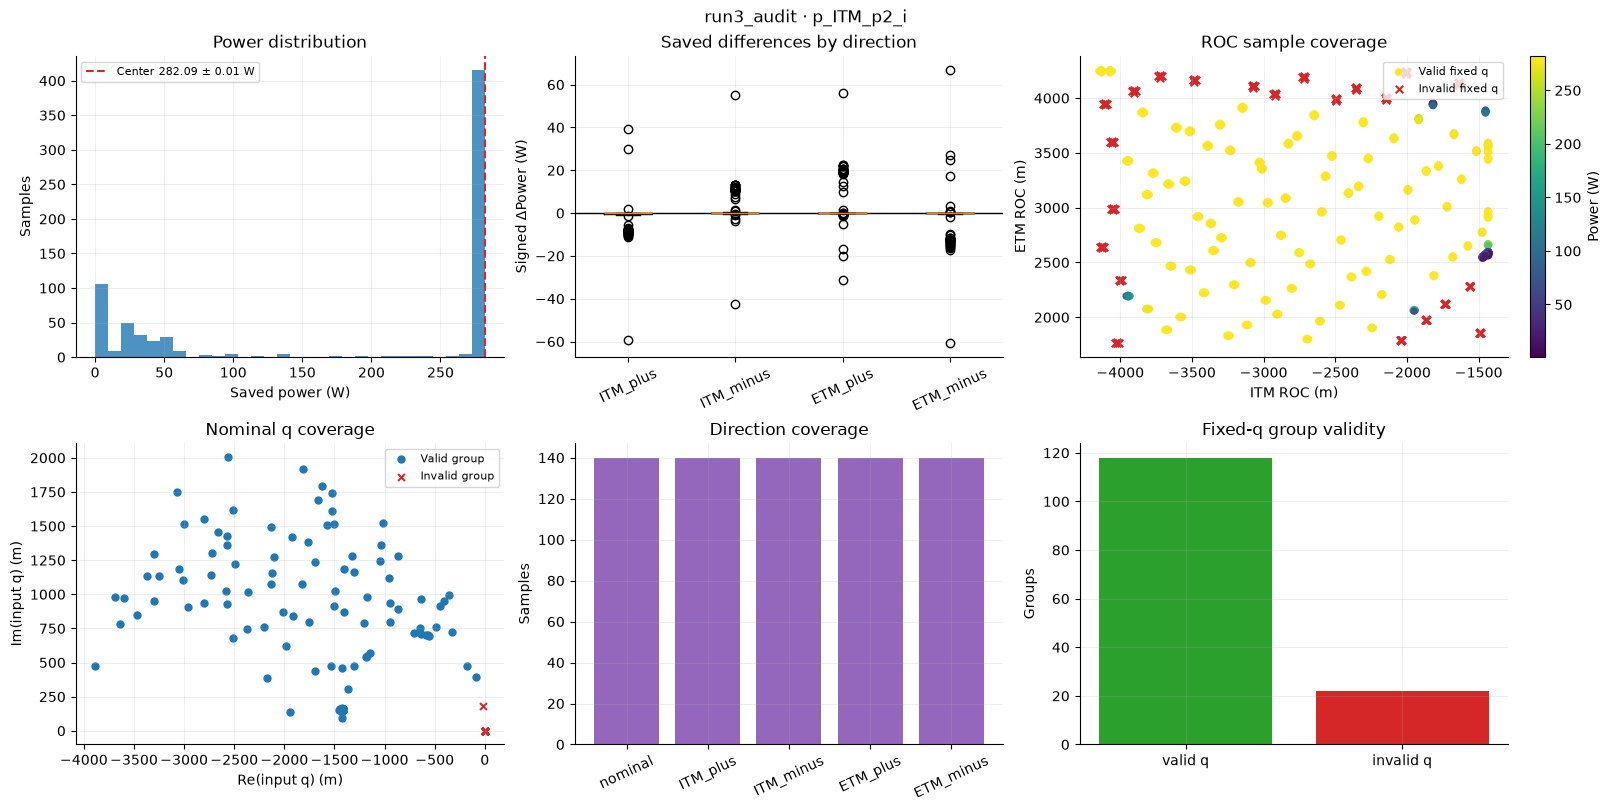

feature,minimum,maximum,std
ITM ROC (m),-4147.64,-1429.27,911.626
ETM ROC (m),1761.14,4259.01,662.483
Re(q) (m),-3973.03,0,994.444
Im(q) (m),0,2005.96,550.205


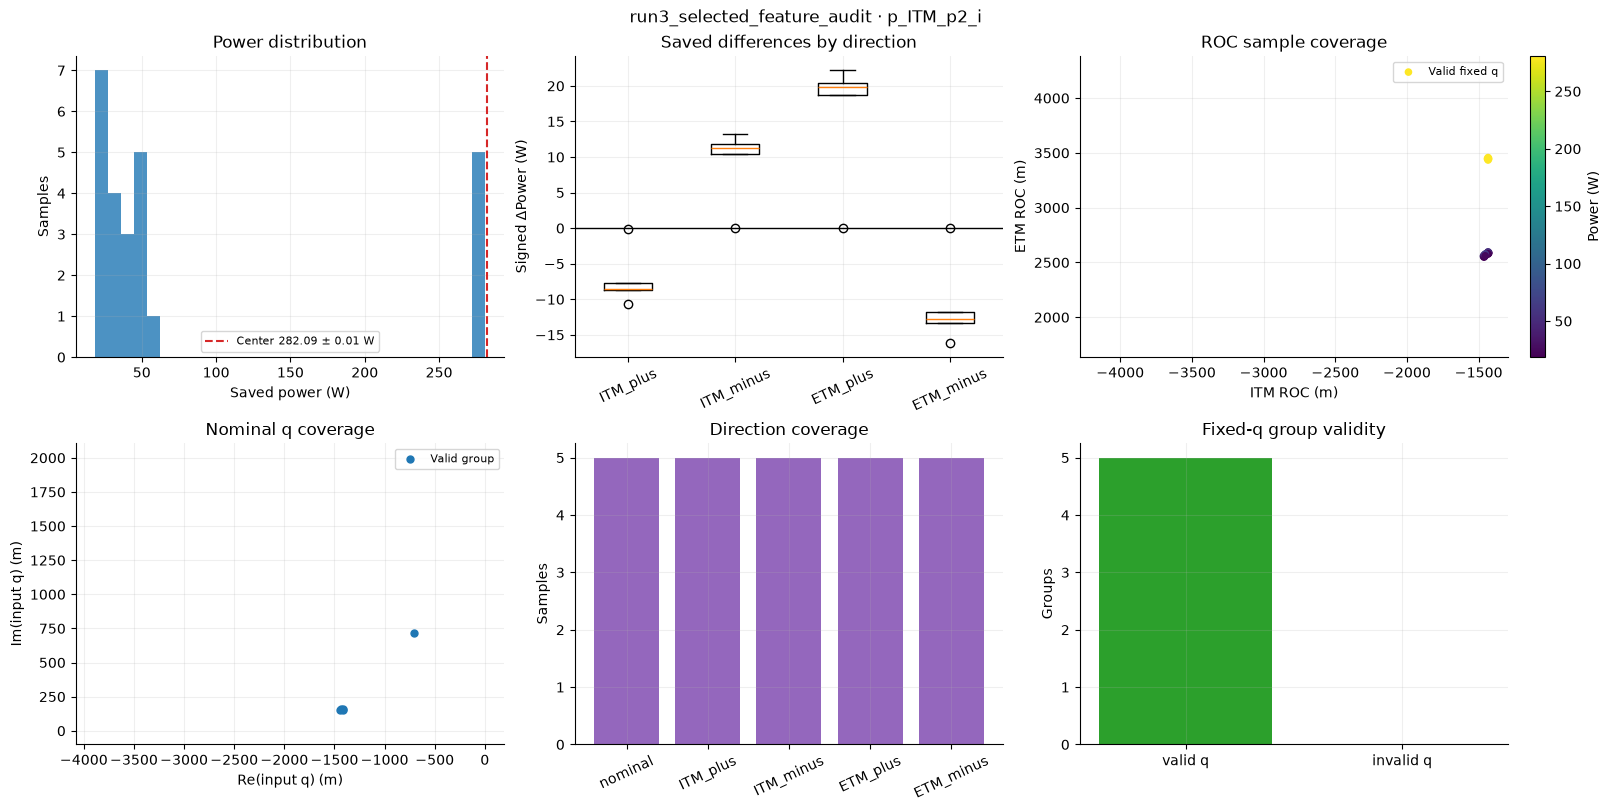

feature,minimum,maximum,std
ITM ROC (m),-1467.18,-1429.27,12.474
ETM ROC (m),2548.4,3457.51,348.678
Re(q) (m),-1446.59,-704.544,289.986
Im(q) (m),151.033,716.892,224.322


In [4]:
audit_rows = []
for name, record in audits.items():
    audit = record['audit']
    check = audit.get('inference_check') or {}
    audit_rows.append({
        'audit': name, **{k: audit.get(k) for k in
            ('groups', 'rows', 'valid_fixed_q_groups', 'zero_output_rows', 'center_rows')},
        'invalid_fixed_q_groups': audit.get('groups', 0) - audit.get('valid_fixed_q_groups', 0),
        'power_range_W': audit.get('power_range_w'),
        'delta_range_W': audit.get('delta_range_w'),
        'feature_check_rows': check.get('rows'), 'feature_mismatches': check.get('mismatches'),
        'detector': record['config'].get('detector'),
    })
table(audit_rows, title='Audit totals (each audit is a separate sample selection)')

# Use the full audit's coverage extents even when only a selected audit is displayed.
coverage_reference_rows = read_csv(OUTPUTS_DIR / f'run{RUN_NUMBER}_audit' / 'samples.csv')
if not coverage_reference_rows:
    coverage_reference_rows = [row for record in audits.values() for row in record['samples']]


def coverage_axis_limits(rows, features):
    limits = {}
    for feature in features:
        coordinates = values(rows, feature)
        coordinates = coordinates[np.isfinite(coordinates)]
        if coordinates.size:
            lo, hi = coordinates.min(), coordinates.max()
            padding = 0.05 * max(hi - lo, 1.0)
            limits[feature] = (lo - padding, hi + padding)
    return limits


roc_limits = coverage_axis_limits(coverage_reference_rows, ('ITM_Rc', 'ETM_Rc'))
nominal_reference_rows = [row for row in coverage_reference_rows if row['direction'] == 'nominal']
nominal_q_limits = coverage_axis_limits(nominal_reference_rows, ('q_input_real', 'q_input_imag'))

for name, record in audits.items():
    rows, audit = record['samples'], record['audit']
    if not rows:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    axes[0, 0].hist(values(rows, 'power'), bins=30, color='tab:blue', alpha=0.8)
    center = record['config'].get('center_loss', {})
    if center:
        axes[0, 0].axvline(center['center_power'], color='tab:red', ls='--',
                          label=f"Center {center['center_power']} ± {center['center_width']} W")
        axes[0, 0].legend(fontsize=8)
    axes[0, 0].set(xlabel='Saved power (W)', ylabel='Samples', title='Power distribution')
    directions = [d for d in DIRECTIONS if d != 'nominal' and any(r['direction'] == d for r in rows)]
    if directions:
        axes[0, 1].boxplot([values([r for r in rows if r['direction'] == d], 'delta_power') for d in directions])
        axes[0, 1].set_xticks(range(1, len(directions) + 1), directions, rotation=25)
    axes[0, 1].axhline(0, color='black', lw=1)
    axes[0, 1].set(ylabel='Signed ΔPower (W)', title='Saved differences by direction')
    valid = [r for r in rows if r.get('valid_fixed_q_group')]
    invalid = [r for r in rows if not r.get('valid_fixed_q_group')]
    scatter = axes[0, 2].scatter(values(valid, 'ITM_Rc'), values(valid, 'ETM_Rc'),
                                c=values(valid, 'power'), s=20, cmap='viridis', label='Valid fixed q')
    if invalid:
        axes[0, 2].scatter(values(invalid, 'ITM_Rc'), values(invalid, 'ETM_Rc'),
                           marker='x', color='tab:red', s=30, label='Invalid fixed q')
    fig.colorbar(scatter, ax=axes[0, 2], label='Power (W)')
    axes[0, 2].set(xlabel='ITM ROC (m)', ylabel='ETM ROC (m)', title='ROC sample coverage',
                   xlim=roc_limits.get('ITM_Rc'), ylim=roc_limits.get('ETM_Rc'))
    axes[0, 2].legend(fontsize=8)
    nominal = [r for r in rows if r['direction'] == 'nominal']
    for status, marker, color in ((True, 'o', 'tab:blue'), (False, 'x', 'tab:red')):
        subset = [r for r in nominal if bool(r.get('valid_fixed_q_group')) == status]
        if subset:
            axes[1, 0].scatter(values(subset, 'q_input_real'), values(subset, 'q_input_imag'),
                               marker=marker, color=color, s=25,
                               label='Valid group' if status else 'Invalid group')
    axes[1, 0].set(xlabel='Re(input q) (m)', ylabel='Im(input q) (m)', title='Nominal q coverage',
                   xlim=nominal_q_limits.get('q_input_real'), ylim=nominal_q_limits.get('q_input_imag'))
    axes[1, 0].legend(fontsize=8)
    counts = Counter(r['direction'] for r in rows)
    present = [d for d in DIRECTIONS if d in counts]
    axes[1, 1].bar(present, [counts[d] for d in present], color='tab:purple')
    axes[1, 1].tick_params(axis='x', rotation=25)
    axes[1, 1].set(ylabel='Samples', title='Direction coverage')
    axes[1, 2].bar(['valid q', 'invalid q'],
                   [audit['valid_fixed_q_groups'], audit['groups'] - audit['valid_fixed_q_groups']],
                   color=['tab:green', 'tab:red'])
    axes[1, 2].set(ylabel='Groups', title='Fixed-q group validity')
    fig.suptitle(f'{name} · {record["config"].get("detector", "detector unspecified")}')
    show_figure(fig, f'audit_{name}')
    feature_stats = [{'feature': feature, 'minimum': lo, 'maximum': hi, 'std': std}
                     for feature, lo, hi, std in zip(
                         ['ITM ROC (m)', 'ETM ROC (m)', 'Re(q) (m)', 'Im(q) (m)'],
                         audit.get('feature_min', []), audit.get('feature_max', []), audit.get('feature_std', []))]
    table(feature_stats, title=f'{name}: feature ranges')


## Production feature reconstruction

The saved pass/fail flags use relative tolerance `2e-4` and absolute tolerance `0.05`
on features reconstructed from float32 inputs. Use those flags when judging agreement;
a single cutoff on the maximum error would not reproduce the check. Agreement
supports feature plumbing for these rows, rather than validating optical labels.


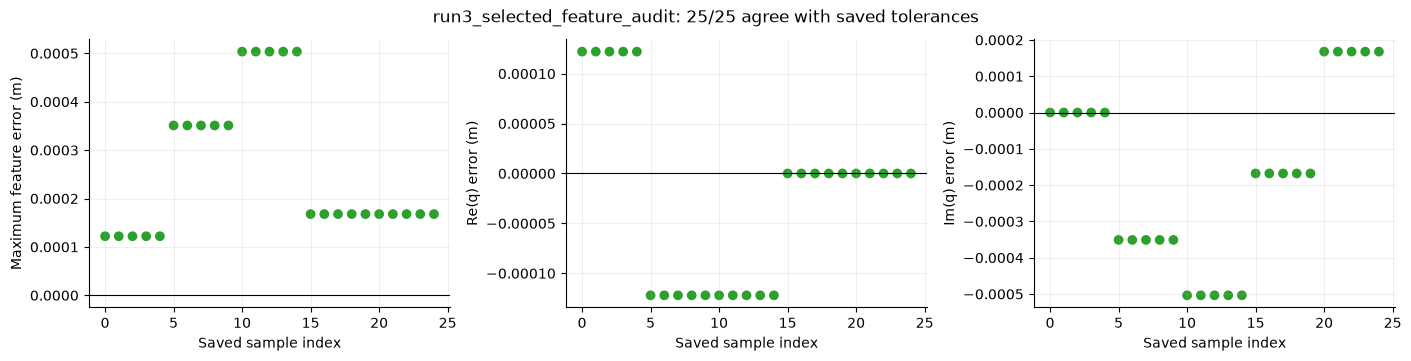

audit,group_id,h5_key,max_feature_abs_error,q_real_error,q_imag_error,matches_tolerance,trace_valid
run3_selected_feature_audit,round:1:0,sim_0,0.00012207,0.00012207,0,True,True
run3_selected_feature_audit,round:1:0,sim_1,0.00012207,0.00012207,0,True,True
run3_selected_feature_audit,round:1:0,sim_2,0.00012207,0.00012207,0,True,True
run3_selected_feature_audit,round:1:0,sim_3,0.00012207,0.00012207,0,True,True
run3_selected_feature_audit,round:1:0,sim_4,0.00012207,0.00012207,0,True,True
run3_selected_feature_audit,round:10:0,sim_0,0.000350952,-0.00012207,-0.000350952,True,True
run3_selected_feature_audit,round:10:0,sim_1,0.000350952,-0.00012207,-0.000350952,True,True
run3_selected_feature_audit,round:10:0,sim_2,0.000350952,-0.00012207,-0.000350952,True,True
run3_selected_feature_audit,round:10:0,sim_3,0.000350952,-0.00012207,-0.000350952,True,True
run3_selected_feature_audit,round:10:0,sim_4,0.000350952,-0.00012207,-0.000350952,True,True


In [5]:
feature_checks = []
for name, record in audits.items():
    rows = record['features']
    if not rows:
        continue
    feature_checks.extend({'audit': name, **row} for row in rows)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
    colors = ['tab:green' if r.get('matches_tolerance') and r.get('trace_valid') else 'tab:red' for r in rows]
    for ax, field, label in zip(axes,
            ['max_feature_abs_error', 'q_real_error', 'q_imag_error'],
            ['Maximum feature error (m)', 'Re(q) error (m)', 'Im(q) error (m)']):
        ax.scatter(range(len(rows)), values(rows, field), c=colors)
        ax.axhline(0, color='black', lw=0.8)
        ax.set(xlabel='Saved sample index', ylabel=label)
    passed = sum(bool(r.get('matches_tolerance')) for r in rows)
    fig.suptitle(f'{name}: {passed}/{len(rows)} agree with saved tolerances')
    show_figure(fig, f'feature_check_{name}')
table(feature_checks, title='All reconstructed-feature checks')


## Run 3: matched initial perturbations and actual optimization

The written analysis separates matched initial-validation comparisons, original
online PSO decisions, final-checkpoint reconstruction, and local fitting tests.
Read the paired-transfer limitations before interpreting a small-set fit as a
replacement for a global model. The figures below use original captured powers
and saved objective settings; no power simulations run when this report refreshes.


# Run 3 surrogate diagnostics

Run 3 contains the intended 100 nominal designs and 400 single-mirror
perturbations. This change improves prediction magnitudes on the initial
validation designs, but the model still learns the wrong local responses at
many points selected by PSO. Feedback mostly corrects nominal power while
leaving perturbation sensitivity inaccurate. Run 3 also found a substantially
better Finesse design early in the search, then repeatedly selected worse ones.

These results use saved Finesse labels, saved production checkpoints, and the
original captured PSO evaluations. The new fitting experiments write separate
diagnostic checkpoints. No production training, checkpoint, data file, or
optical power simulation was changed.

## What was checked

The diagnostic loader now reads the initial HDF5 `design_group_size` attribute.
Run 3 therefore has 100 five-row initial groups, while historical run 2 retains
100 two-row nominal/joint groups. Five-row direction ordering is checked for
both initial and feedback data. Treating run 3 as consecutive pairs would have
silently produced incorrect nominal/partner associations.

The full run 3 audit contains 140 groups and 700 rows: 500 initial rows and
200 feedback rows. Of the initial groups, 78 have valid fixed q throughout;
22 do not. Initial data contains 104 zero-power rows and 230 rows in the saved
282.09 +/- 0.01 W center band. Production training includes these rows; valid-q
subsets below are explicitly identified. Zero labels do not establish whether
a cavity was unstable or a solver/lock failed.

All 25 feature reconstructions from feedback rounds 1, 10, 20, 30, and 40
passed the documented tolerances. This supports the sampled feature path;
it does not validate optical power solves. Artifacts:
[full audit](outputs/run3_audit/audit.json),
[feature audit](outputs/run3_selected_feature_audit/audit.json).

## The initial sampling change helped, but did not fix response signs

The two runs share identical nominal features and identical initial training
and validation design IDs. Both base checkpoints were evaluated on the same
15 valid held-out run 3 designs, containing 75 rows and 60 directional responses.
This avoids comparing different response types or different geometries.

| Base checkpoint | Power MAE (W) | DeltaPower MAE (W) | Perturbation-cost MAE (W/m) | Correct significant signs |
| --- | ---: | ---: | ---: | ---: |
| Run 2 | 8.123 | 1.213 | 0.478 | 2/10 |
| Run 3 | 7.124 | 0.642 | 0.235 | 2/10 |

Run 3 reduces difference error by about 47% and perturbation-cost error by
about 51% on this cohort. The sample count and significance threshold matter:
only 10 of these 60 responses have absolute true differences above 0.1 W.

The response shape is still wrong. Across all 78 valid initial designs,
Finesse power decreases in both ITM directions for 59 designs and in both ETM
directions for 62 designs. The run 3 base model predicts opposite signs for
the two directions in every one of the 78 designs, for both mirrors. On the
held-out subset, Finesse has 11/15 ITM and 13/15 ETM pairs with both directions
decreasing; the model has zero such pairs.

Most initial responses are small: only 52 of 312 valid directional labels
exceed 0.1 W. Typical signed changes are a few thousandths of a watt. The
ROC steps average about 0.012-0.013 input standard deviations. Matching the
sampling pattern therefore does not by itself force accurate local slopes
and curvature. See [training audit](outputs/run3_training_audit/training_audit.json).

## Accuracy where run 3 actually searches

The following checkpoints were evaluated on exactly the same 40 run 3
feedback designs. The final run 3 checkpoint has already trained on these
feedback labels, so its result measures replay reconstruction.

| Checkpoint | DeltaPower MAE (W) | Correct significant signs |
| --- | ---: | ---: |
| Run 2 base | 10.250 | 2/131 |
| Run 3 base | 10.001 | 2/131 |
| Run 3 after round 40 | 9.935 | 48/131 |

Both run 3 base and final checkpoints get every significant ETM response
wrong: 0/67 correct. The final checkpoint improves nominal powers and some
ITM signs, but differences remain much too flat.

At round 40, the final checkpoint gives this concrete example:

| Sample | Finesse power (W) | Final MLP power (W) | Finesse DeltaPower (W) | MLP DeltaPower (W) |
| --- | ---: | ---: | ---: | ---: |
| Nominal | 39.974 | 38.797 | 0 | 0 |
| ITM+ | 29.276 | 38.797 | -10.698 | approximately 0 |
| ITM- | 53.213 | 38.796 | +13.239 | approximately 0 |
| ETM+ | 62.251 | 38.586 | +22.277 | -0.211 |
| ETM- | 23.766 | 39.008 | -16.208 | +0.211 |

The true perturbation cost is 9.528 W/m; the final model predicts about
0.0500 W/m, roughly 190 times too small. The nominal power is quite close,
yet the sensitivity driving the optimization objective is badly wrong.

Across all 40 feedback updates, evaluating the matching checkpoint immediately
before and after its update gives nominal-power MAE 11.395 -> 7.151 W, while
DeltaPower MAE stays essentially unchanged at 9.929 -> 9.937 W. Those
reconstructed predictions use stored float32 features; original captured
online records are kept separately, since tiny predicted differences can
change sign under feature rounding.

Artifacts: [checkpoint comparison](outputs/run3_comparison/comparison.json),
[feedback updates](outputs/run3_training_audit/feedback_updates.csv).

## The actual PSO outcome is mixed

Costs use the saved full objective:

`0.5 / nominal_power + 0.5 * sum(abs(DeltaPower) / ROC_step)`.

Run 3's best saved Finesse cost was approximately **0.01694 at round 4**,
compared with **0.59014** for run 2's best saved design. Lower is better:
run 3 found a design about 35 times better under this objective.

Later it repeatedly chose poor designs that the surrogate scored as nearly
flat. At round 40, the original online prediction was cost 0.0380 versus
Finesse cost 4.7766, about 126 times larger. The original round-40 evaluation
used checkpoint 39; this is distinct from the final-checkpoint replay above.
The saved records retain every earlier good design, so the final round alone
does not describe the best result achieved by the run.

Online mean true cost was 0.975 for run 2 and 2.996 for run 3. This describes
each run's own selected trajectory; it is not a controlled same-point model
comparison. All captured costs were reconstructed from their original powers,
steps, and weights and checked against the saved values.

![Saved online full costs and nominal powers](outputs/run3_comparison/online_cost_and_power.png)

## Directly supervising differences helps local fitting

Separate models fitted the 25 saved rows from rounds 1, 10, 20, 30, and 40 for
up to 2,000 epochs. Within each experiment, loss variants shared identical
initial weights, normalization, and training settings (one seed, 9302). Checkpoints were
selected using the same training power/difference score.

| Initialization and scaling | Current row loss: DeltaPower MAE (W) | Paired loss: DeltaPower MAE (W) |
| --- | ---: | ---: |
| Fresh weights, scaling from these 25 rows | 3.276 | 0.290 |
| Production final checkpoint, original scaling | 4.945 | 1.603 |

The paired objective adds an explicit signed-difference penalty. It improves
these fits by about 91% and 68%, respectively. The center-focused and ordinary
log-power variants give identical results here because the selected labels
lie outside the narrow center band. Most selected checkpoints reach the epoch
budget, so the residual errors do not establish a model capacity limit.

Local fitting does not establish a usable global surrogate. The fresh models
were also evaluated on the other 35 feedback groups without further training.
Both produced extreme powers at the distant round-4 design, whose ITM ROC is
at the opposite end of the global range from the five training designs.
The ordinary and paired maximum difference errors reached roughly 6.6e161 W
and 1.4e136 W. Their median difference errors were 0.628 W and 0.284 W, but
the extreme failures dominate their mean errors. Small-set normalization and
coverage make these checkpoints unsuitable for global PSO use.

Artifacts: [fresh fits](outputs/run3_five_groups_fresh/summary.csv),
[final-checkpoint fits](outputs/run3_five_groups_warm/summary.csv),
[ordinary transfer evaluation](outputs/run3_transfer_center_focused/metrics.json),
[paired transfer evaluation](outputs/run3_transfer_paired/metrics.json).

## Interpretation and next experiment

The change to four-direction initial sampling was useful. The remaining
failure is that row-wise log-power training and checkpoint selection do not
directly require the differences consumed by PSO to be correct. The observed
flat feedback predictions, wrong symmetric response shape, and improvement
under paired supervision support investigating this training objective.
They do not isolate loss, scaling, coverage, optimization budget, and feedback
selection as independent causes. With 400 rather than 160 initial training
rows, the same batch size gives 13 rather than 5 optimizer updates per epoch.
The automatic newest-feedback weight also changes from 40 to 100. The run
comparison therefore measures the actual combined intervention, rather than
an isolated sampling-layout effect.

A controlled next experiment should keep the full initial design split,
global training-only scaling, model initialization, batching, and budget
fixed; compare current and paired supervision; select checkpoints using
validation power and signed-difference errors; and then assess held-out
designs and actual Finesse-verified optimization results. Dense response or
independent-q sampling could address coverage separately. The best
Finesse-verified design should also be tracked alongside the latest round.

No global retraining comparison or production change was made here.


comparison,run,checkpoint,split,groups,rows,power_mae,nominal_power_mae,delta_mae,sign_count,sign_correct,sign_accuracy,perturbation_cost_mae,full_cost_mae,predicted_full_cost_mean,true_full_cost_mean,interpretation
original_online_own_selected_points,2,base for round1; roundN-1 for roundN,online,40,200,6.15927,2.29518,5.83834,160,77,0.48125,1.87473,0.938135,0.0369371,0.975072,Each run chose its own geometries. These are original predictions before that round's Finesse feedback; not a controlled comparison of architectures.
original_online_own_selected_points,3,base for round1; roundN-1 for roundN,online,40,200,17.8715,11.3952,9.92912,131,48,0.366412,5.9183,2.95993,0.0423476,2.9962,Each run chose its own geometries. These are original predictions before that round's Finesse feedback; not a controlled comparison of architectures.
same_target_feedback_geometries,2,base,feedback,40,200,18.7552,19.7752,10.2497,131,2,0.0152672,5.8435,2.92647,0.148416,2.9962,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
same_target_feedback_geometries,2,round40,feedback,40,200,17.74,14.8932,10.1988,131,2,0.0152672,5.86519,2.93536,0.127803,2.9962,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
own_initial_checkpoint_split,2,base,training,80,160,7.42156,7.20673,4.99558,19,7,0.368421,—,—,—,—,"Training fit, including all rows production trained."
own_initial_checkpoint_split,2,base,training_valid_fixed_q,64,128,9.16037,8.9597,6.09655,18,6,0.333333,—,—,—,—,"Training fit, including all rows production trained. Only valid fixed-q groups; overlaps corresponding all-row split."
own_initial_checkpoint_split,2,base,validation,20,40,6.22299,5.86453,1.44116,3,0,0,—,—,—,—,Whole-design validation labels were held out from weight updates but used for checkpoint selection; not an independent test.
own_initial_checkpoint_split,2,base,validation_valid_fixed_q,15,30,8.23162,7.75369,1.91938,3,0,0,—,—,—,—,Whole-design validation labels were held out from weight updates but used for checkpoint selection; not an independent test. Only valid fixed-q groups; overlaps corresponding all-row split.
same_target_feedback_geometries,3,base,feedback,40,200,25.002,26.2714,10.0011,131,2,0.0152672,5.88838,2.94913,0.0564967,2.9962,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
same_target_feedback_geometries,3,round40,feedback,40,200,14.4832,7.67772,9.93456,131,48,0.366412,5.92533,2.96321,0.045737,2.9962,"Controlled checkpoint comparison at identical target feedback geometries. All target feedback labels were replayed during training; measures fit, not generalization."


run,round,group_id,itm_roc,etm_roc,model_path,checkpoint_round,evaluation_role,training_exposure,cost_mode,power_weight,perturbation_weight,delta_itm,delta_etm,predicted_power_cost,predicted_perturbation_cost,predicted_weighted_power_cost,predicted_weighted_perturbation_cost,predicted_total_cost,true_power_cost,true_perturbation_cost,true_weighted_power_cost,true_weighted_perturbation_cost,true_total_cost,nominal_power,predicted_nominal_power,nominal_power_error,delta_mae,sign_count,sign_correct,true_to_predicted_cost_ratio,true_weighted_power_fraction
2,1,round:1:0,-1434,3963.14,/home/xuesi.ma/ligo-opt/MLP/models/run2/base_200_mlp.pt,0,original_online_before_feedback,Own initial training rows and feedback rounds 1-0,full,0.5,0.5,4.7322,13.0783,0.0382145,0.0400058,0.0191072,0.0200029,0.0391101,0.0650367,1.11524,0.0325183,0.55762,0.590139,15.3759,26.1681,10.7922,3.57914,4,0,15.0892,0.0551029
2,2,round:2:0,-1434,3938.63,/home/xuesi.ma/ligo-opt/MLP/models/run2/power_predictor_ligoParams_finetuned_round1.pt,1,original_online_before_feedback,Own initial training rows and feedback rounds 1-1,full,0.5,0.5,4.7322,12.9975,0.0277835,0.0388797,0.0138918,0.0194398,0.0333316,0.0372184,1.57977,0.0186092,0.789887,0.808496,26.8685,35.9926,9.12412,4.90001,4,2,24.2562,0.023017
2,3,round:3:0,-1434,3927.34,/home/xuesi.ma/ligo-opt/MLP/models/run2/power_predictor_ligoParams_finetuned_round2.pt,2,original_online_before_feedback,Own initial training rows and feedback rounds 1-2,full,0.5,0.5,4.7322,12.9602,0.0259851,0.0397921,0.0129926,0.0198961,0.0328886,0.0278643,2.05927,0.0139322,1.02964,1.04357,35.8882,38.4836,2.59543,6.29409,4,2,31.7304,0.0133505
2,4,round:4:0,-1434,3927.26,/home/xuesi.ma/ligo-opt/MLP/models/run2/power_predictor_ligoParams_finetuned_round3.pt,3,original_online_before_feedback,Own initial training rows and feedback rounds 1-3,full,0.5,0.5,4.7322,12.96,0.0265486,0.039363,0.0132743,0.0196815,0.0329558,0.0278083,2.06241,0.0139042,1.03121,1.04511,35.9605,37.6668,1.70638,6.29847,4,2,31.7125,0.013304
2,5,round:5:0,-1434,3925.08,/home/xuesi.ma/ligo-opt/MLP/models/run2/power_predictor_ligoParams_finetuned_round4.pt,4,original_online_before_feedback,Own initial training rows and feedback rounds 1-4,full,0.5,0.5,4.7322,12.9528,0.0257181,0.0404123,0.0128591,0.0202061,0.0330652,0.0263251,2.14649,0.0131625,1.07324,1.08641,37.9866,38.8831,0.896469,6.53935,4,2,32.8564,0.0121157
2,6,round:6:0,-1434,3925.92,/home/xuesi.ma/ligo-opt/MLP/models/run2/power_predictor_ligoParams_finetuned_round5.pt,5,original_online_before_feedback,Own initial training rows and feedback rounds 1-5,full,0.5,0.5,4.7322,12.9555,0.0259714,0.0404299,0.0129857,0.020215,0.0332006,0.0268794,2.11486,0.0134397,1.05743,1.07087,37.2033,38.5039,1.30069,6.44663,4,2,32.2545,0.0125502
2,7,round:7:0,-1434,3926.47,/home/xuesi.ma/ligo-opt/MLP/models/run2/power_predictor_ligoParams_finetuned_round6.pt,6,original_online_before_feedback,Own initial training rows and feedback rounds 1-6,full,0.5,0.5,4.7322,12.9574,0.0262052,0.0409508,0.0131026,0.0204754,0.033578,0.0272587,2.09336,0.0136294,1.04668,1.06031,36.6855,38.1603,1.47482,6.38476,4,2,31.5775,0.0128541
2,8,round:8:0,-1434,3926.52,/home/xuesi.ma/ligo-opt/MLP/models/run2/power_predictor_ligoParams_finetuned_round7.pt,7,original_online_before_feedback,Own initial training rows and feedback rounds 1-7,full,0.5,0.5,4.7322,12.9575,0.0262743,0.040981,0.0131371,0.0204905,0.0336277,0.0272933,2.09141,0.0136466,1.0457,1.05935,36.6391,38.06,1.42094,6.37757,4,2,31.5023,0.0128821
2,9,round:9:0,-1434,3926.71,/home/xuesi.ma/ligo-opt/MLP/models/run2/power_predictor_ligoParams_finetuned_round8.pt,8,original_online_before_feedback,Own initial training rows and feedback rounds 1-8,full,0.5,0.5,4.7322,12.9581,0.026489,0.041014,0.0132445,0.020507,0.0337515,0.0274212,2.08419,0.0137106,1.04209,1.0558,36.4682,37.7515,1.28333,6.35462,4,2,31.2817,0.0129859
2,10,round:10:0,-1434,3925.91,/home/xuesi.ma/ligo-opt/MLP/models/run2/power_predictor_ligoParams_finetuned_r

**run3_comparison: online_cost_and_power**

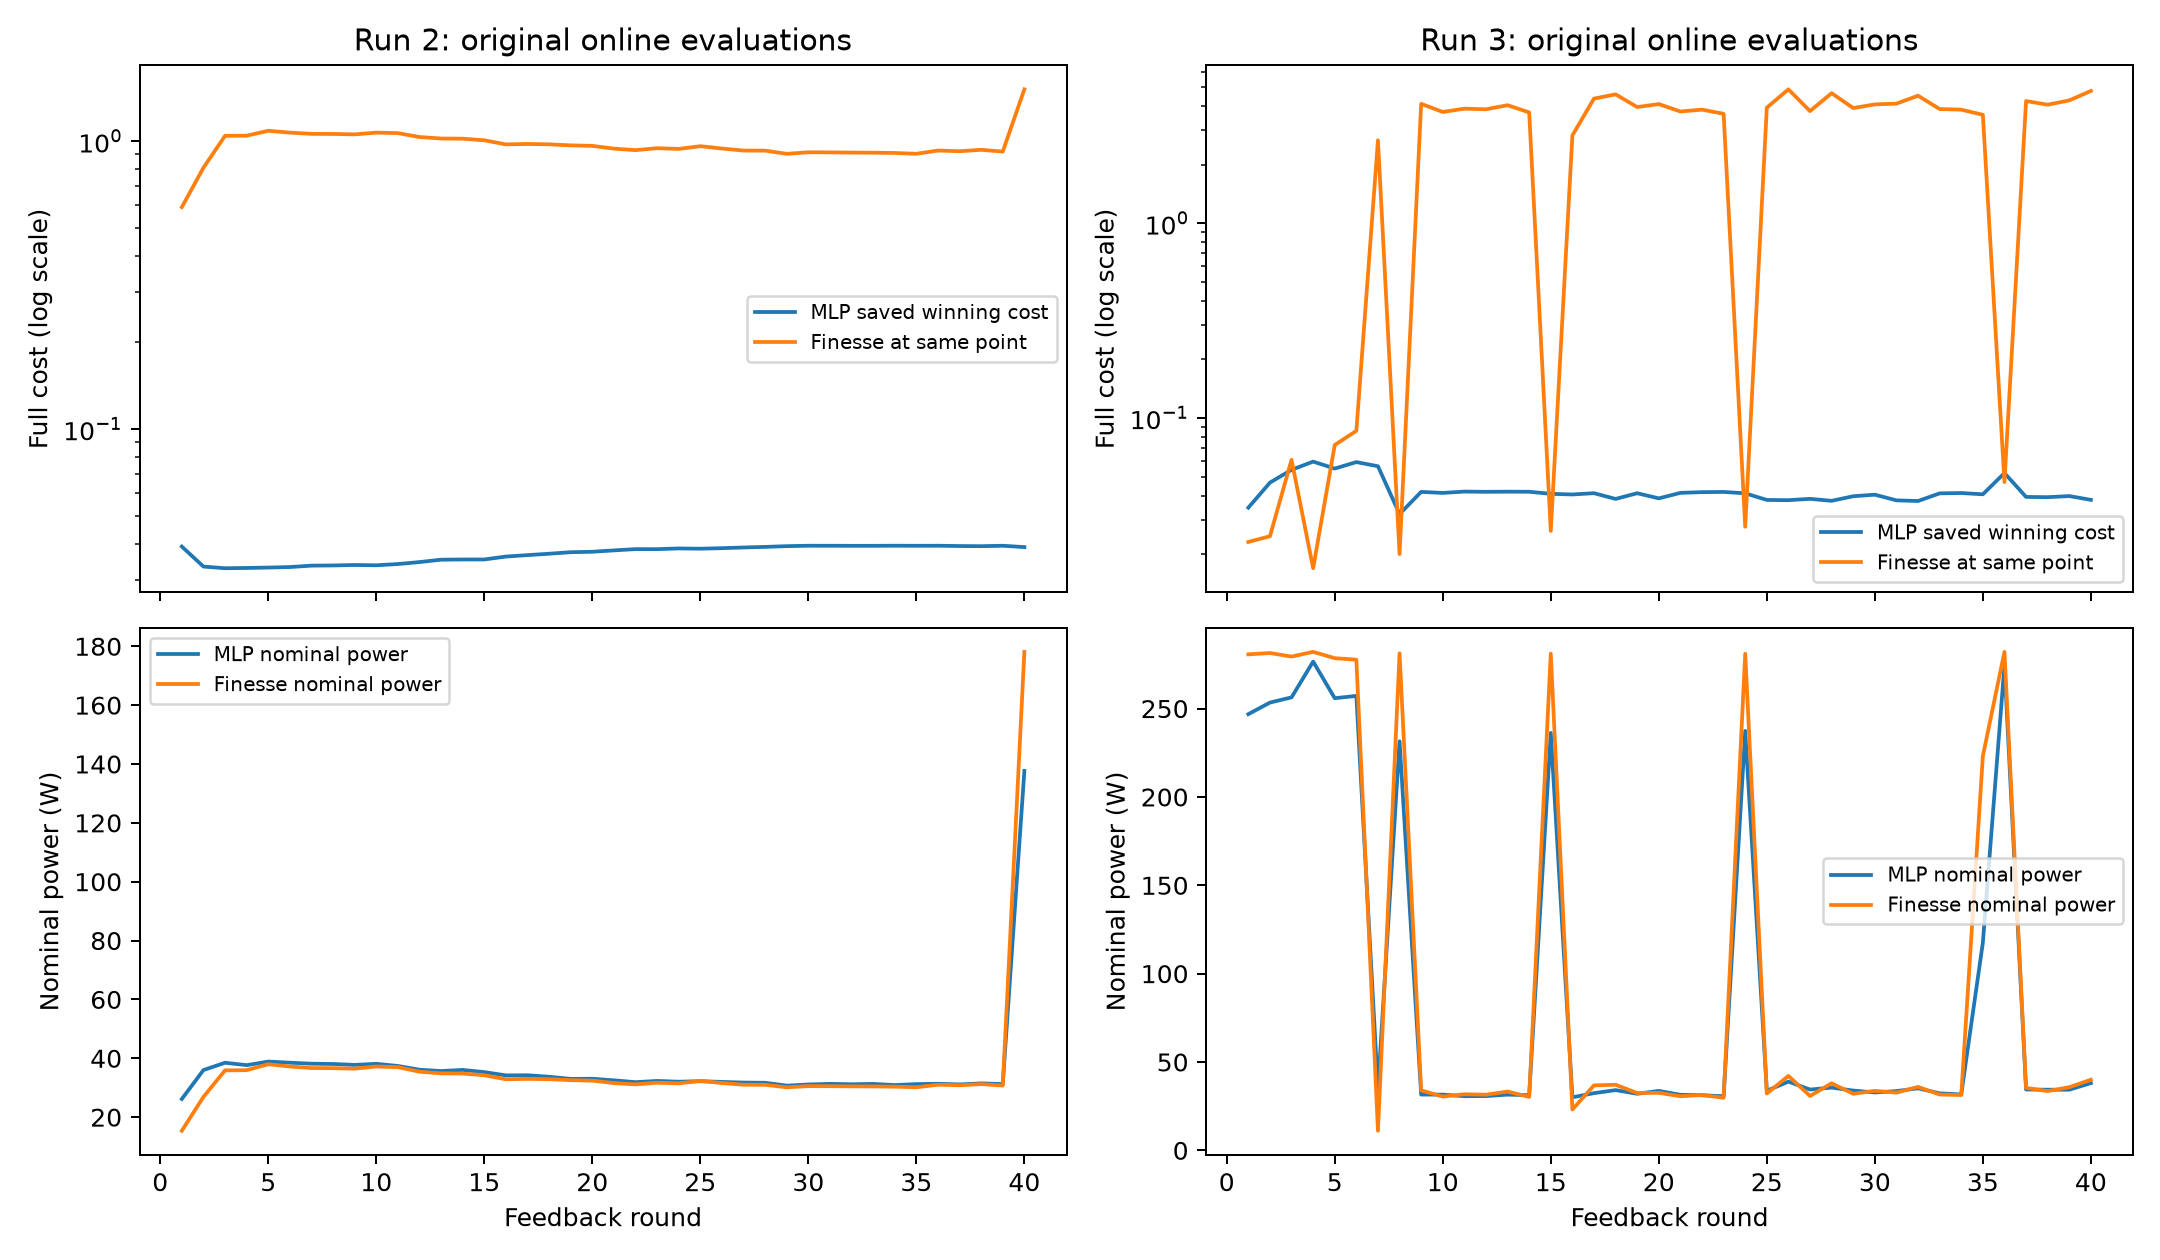

**run3_comparison: online_roc_coverage**

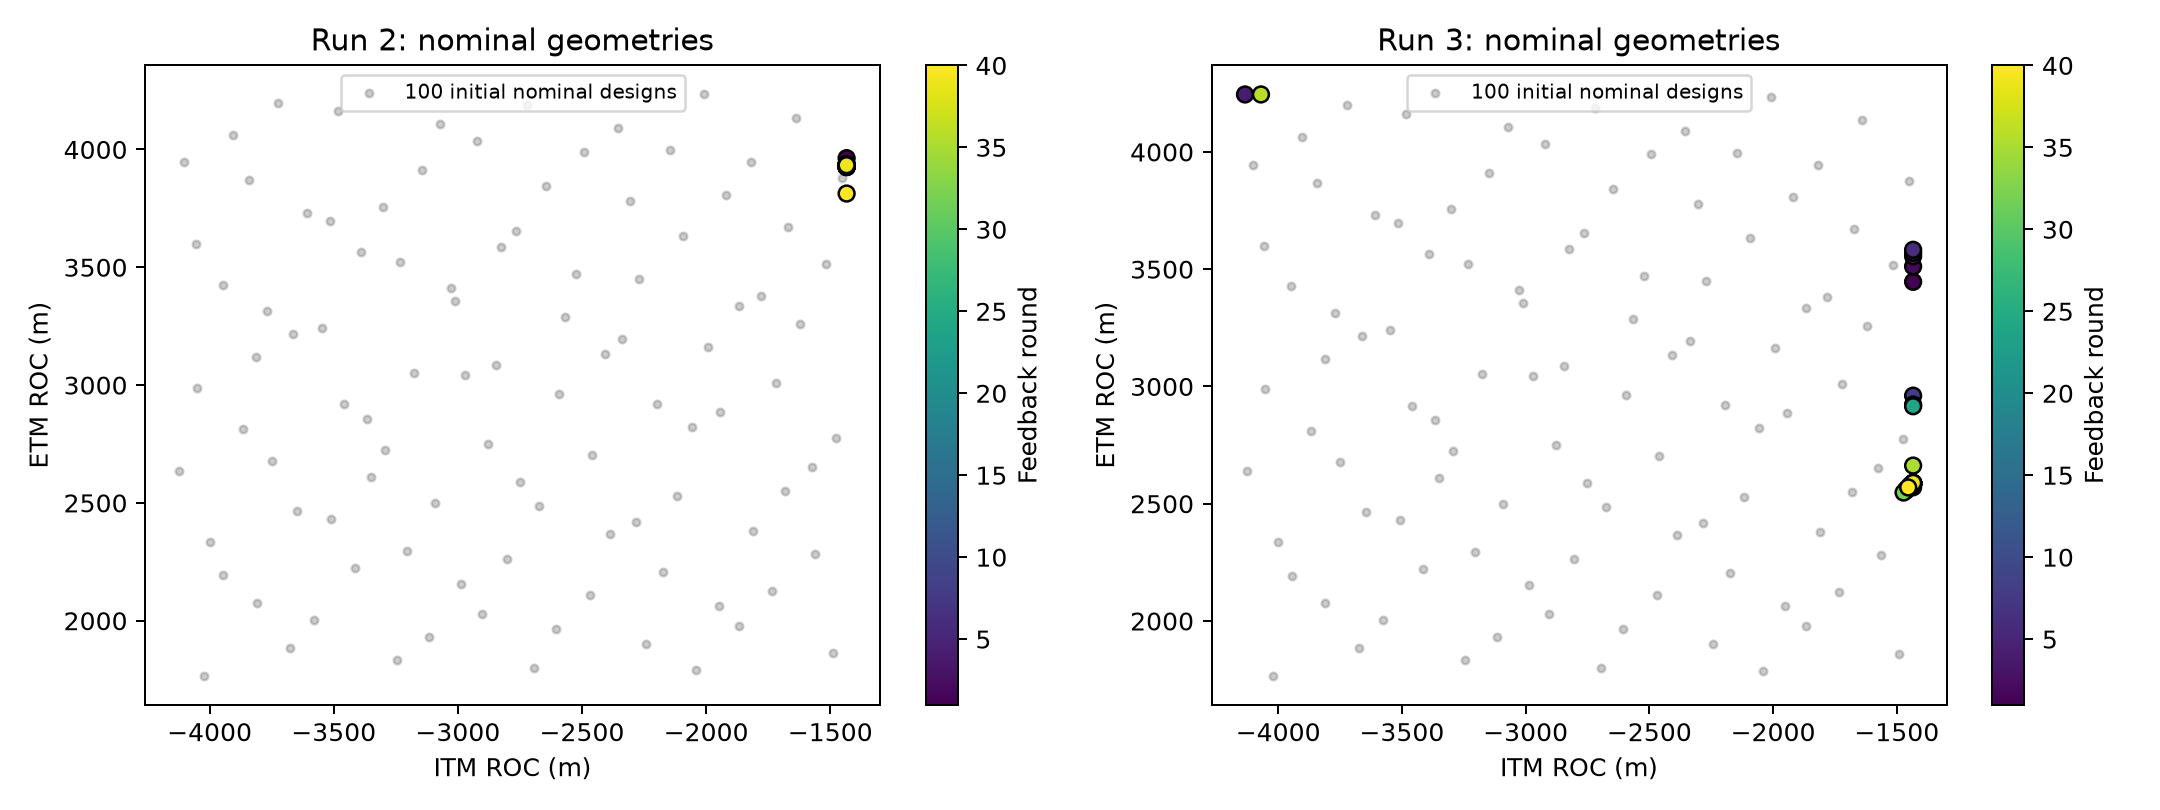

**run3_comparison: same_geometry_delta_errors**

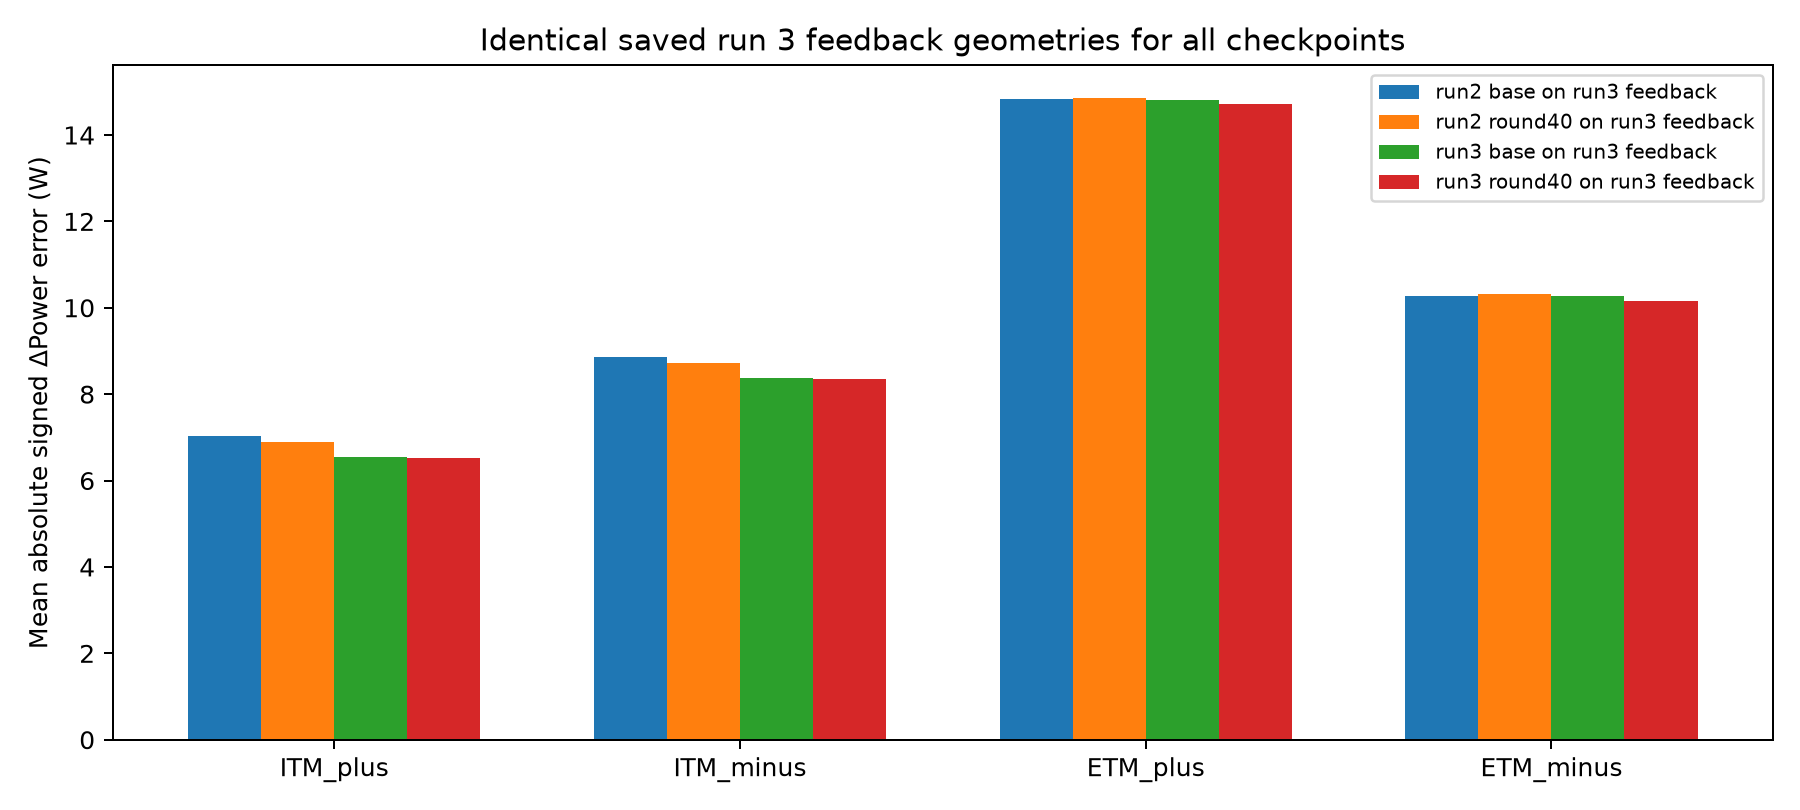

round,stage,valid_fixed_q,nominal_itm_roc_m,nominal_etm_roc_m,true_nominal_power,predicted_nominal_power,nominal_power_abs_error,power_mae,delta_mae,sign_count,sign_accuracy,group_id,true_perturbation_cost,predicted_perturbation_cost,valid_perturbation_cost,best_epoch,newest_row_weight
1,pre,True,-1434,3446.14,280.681,246.855,33.8265,33.8308,0.198672,0,—,round:1:0,0.0426523,0.0653223,True,10,100
1,post,True,-1434,3446.14,280.681,258.093,22.5879,22.592,0.279282,0,—,round:1:0,0.0426523,0.110171,True,10,100
2,pre,True,-1434,3511.81,281.446,253.394,28.0515,27.9876,0.384254,1,0,round:2:0,0.0458914,0.0893729,True,15,100
2,post,True,-1434,3511.81,281.446,260.252,21.1942,21.1301,0.431337,1,0,round:2:0,0.0458914,0.120559,True,15,100
3,pre,True,-1434,3555.04,279.427,256.35,23.0771,23.0578,0.650959,2,0,round:3:0,0.118498,0.104577,True,15,100
3,post,True,-1434,3555.04,279.427,260.812,18.6153,18.5958,0.692385,2,0,round:3:0,0.118498,0.129343,True,15,100
4,pre,True,-4134,4245,282.094,276.606,5.48765,5.40096,0.425166,2,0.5,round:4:0,0.0303367,0.115904,True,20,100
4,post,True,-4134,4245,282.094,276.853,5.24146,5.15455,0.426774,2,0.5,round:4:0,0.0303367,0.118419,True,20,100
5,pre,True,-1434,3569.97,278.516,255.868,22.6472,22.6241,0.70592,2,0,round:5:0,0.141823,0.106163,True,5,100
5,post,True,-1434,3569.97,278.516,258.587,19.9285,19.9053,0.736054,2,0,round:5:0,0.141823,0.120319,True,5,100


In [6]:
run3_findings_path = DIAGNOSTICS_DIR / 'RUN3_FINDINGS.md'
if run3_findings_path.exists():
    display(Markdown(run3_findings_path.read_text()))
for comparison_path in sorted(OUTPUTS_DIR.rglob('comparison.json')):
    name = comparison_path.parent.relative_to(OUTPUTS_DIR).as_posix()
    if not included(name):
        continue
    comparison = read_json(comparison_path)
    json_panel(f'{name}: full comparison and source hashes', comparison)
    table(read_csv(comparison_path.parent / 'summary.csv'),
          title=f'{name}: checkpoint and original online metrics', collapsed=True)
    table(read_csv(comparison_path.parent / 'online_rounds.csv'),
          title=f'{name}: every original PSO selection and cost component', collapsed=True)
    for figure_path in sorted(comparison_path.parent.glob('*.png')):
        display(Markdown(f'**{name}: {figure_path.stem}**'))
        display(Image(filename=str(figure_path)))
for training_path in sorted(OUTPUTS_DIR.rglob('training_audit.json')):
    name = training_path.parent.relative_to(OUTPUTS_DIR).as_posix()
    if included(name):
        json_panel(f'{name}: matched initial designs, symmetry, and feedback updates',
                   read_json(training_path))
        table(read_csv(training_path.parent / 'feedback_updates.csv'),
              title=f'{name}: before/after every feedback update', collapsed=True)


## Experiment conditions and comparable results

Scratch/local scaling and warm-start/original scaling change both initialization
and normalization. Their difference cannot be attributed solely to the loss.
Checkpoint selection uses the monitored split and the saved training-only scales:

`power_MAE / training_power_RMS + delta_MAE / training_delta_RMS`.

Sign accuracy excludes true `|ΔPower|` at or below the saved threshold (currently
0.1 W); the significant sample count is shown alongside it.

Grouped holdouts measure saved designs. Nearby PSO geometries can remain correlated,
so these splits do not establish spatial extrapolation. Use validation for choosing
settings; repeatedly choosing variants from test results compromises the holdout.


In [7]:
condition_rows, initialization_rows = [], []
for name, experiment in experiments.items():
    config, provenance = experiment['config'], experiment['provenance']
    selected_runs = [r for r in runs.values() if r['tags']['experiment'] == name]
    first = selected_runs[0]
    sizes = {split: stats['groups'] for split, stats in first['metrics'].get('splits', {}).items()}
    excluded = provenance.get('excluded_invalid_fixed_q_groups', first['metrics'].get('excluded', {}))
    condition_rows.append({
        'experiment': name, 'scope': experiment['scope'], 'detector': config.get('detector'),
        'initial_checkpoint': first['metrics'].get('checkpoint') or config.get('initial_checkpoint') or 'fresh weights',
        'normalization': 'checkpoint (evaluation)' if first['metrics'].get('checkpoint') else config.get('normalization'),
        'epochs': config.get('epochs') if first['history'] else None,
        'monitor_split': first['metrics'].get('monitor_split'),
        'groups_by_split': sizes, 'excluded_groups': {k: len(v) for k, v in excluded.items()},
        'power_scale_W': provenance.get('power_scale_w'), 'delta_scale_W': provenance.get('delta_scale_w'),
    })
    seeds = sorted({r['config'].get('seed') for r in selected_runs if r['config'].get('seed') is not None})
    for seed in seeds:
        hashes = {r['config'].get('initial_state_sha256') for r in selected_runs if r['config'].get('seed') == seed}
        hashes.discard(None)
        initialization_rows.append({'experiment': name, 'seed': seed, 'recorded_initial_states': len(hashes),
                                    'same_start_across_variants': len(hashes) == 1 if hashes else None})
table(condition_rows, title='Saved experimental conditions')
table(initialization_rows, title='Initialization consistency within each experiment / seed')
table(metric_rows, columns=['experiment', 'variant', 'seed', 'split', 'detector', 'best_epoch',
    'groups', 'rows', 'power_mae', 'power_max_abs_error', 'delta_mae', 'delta_max_abs_error',
    'sign_accuracy', 'sign_count', 'sign_threshold_w', 'perturbation_cost_mae',
    'valid_cost_groups', 'invalid_cost_groups'], title='All saved metrics')


experiment,scope,detector,initial_checkpoint,normalization,epochs,monitor_split,groups_by_split,excluded_groups,power_scale_W,delta_scale_W
run3_comparison/run2_base_on_initial,standalone checkpoint evaluation,p_ITM_p2_i,/home/xuesi.ma/ligo-opt/MLP/models/run2/base_200_mlp.pt,checkpoint (evaluation),—,—,"{'training': 80, 'training_valid_fixed_q': 64, 'validation': 20, 'validation_valid_fixed_q': 15}","{'training': 0, 'training_valid_fixed_q': 0, 'validation': 0, 'validation_valid_fixed_q': 0}",—,—
run3_comparison,standalone checkpoint evaluation,—,/home/xuesi.ma/ligo-opt/MLP/models/run2/base_200_mlp.pt,checkpoint (evaluation),—,—,{'feedback': 40},{'feedback': 0},—,—
run3_comparison/run3_base_on_initial,standalone checkpoint evaluation,p_ITM_p2_i,/home/xuesi.ma/ligo-opt/MLP/models/run3/base_500_mlp.pt,checkpoint (evaluation),—,—,"{'training': 80, 'training_valid_fixed_q': 63, 'validation': 20, 'validation_valid_fixed_q': 15}","{'training': 0, 'training_valid_fixed_q': 0, 'validation': 0, 'validation_valid_fixed_q': 0}",—,—
run3_five_groups_fresh,training-set fit,p_ITM_p2_i,fresh weights,training,2000,train,{'train': 5},{'train': 0},130.137,12.7967
run3_five_groups_warm,training-set fit,p_ITM_p2_i,MLP/models/run3/power_predictor_ligoParams_finetuned_round40.pt,checkpoint,2000,train,{'train': 5},{'train': 0},130.137,12.7967
run3_transfer_center_focused,standalone checkpoint evaluation,p_ITM_p2_i,/home/xuesi.ma/ligo-opt/analysis/surrogate_diagnostics/outputs/run3_five_groups_fresh/center_focused_seed9302/checkpoint.pt,checkpoint (evaluation),—,—,{'transfer': 35},{'transfer': 0},—,—
run3_transfer_paired,standalone checkpoint evaluation,p_ITM_p2_i,/home/xuesi.ma/ligo-opt/analysis/surrogate_diagnostics/outputs/run3_five_groups_fresh/paired_seed9302/checkpoint.pt,checkpoint (evaluation),—,—,{'transfer': 35},{'transfer': 0},—,—


experiment,seed,recorded_initial_states,same_start_across_variants
run3_five_groups_fresh,9302,1,True
run3_five_groups_warm,9302,1,True


experiment,variant,seed,split,detector,best_epoch,groups,rows,power_mae,power_max_abs_error,delta_mae,delta_max_abs_error,sign_accuracy,sign_count,sign_threshold_w,perturbation_cost_mae,valid_cost_groups,invalid_cost_groups
run3_comparison/run2_base_on_initial,checkpoint,—,training,p_ITM_p2_i,—,80,160,7.42156,88.4494,4.99558,107.352,0.368421,19,0.1,—,0,0
run3_comparison/run2_base_on_initial,checkpoint,—,training_valid_fixed_q,p_ITM_p2_i,—,64,128,9.16037,88.4494,6.09655,107.352,0.333333,18,0.1,—,0,0
run3_comparison/run2_base_on_initial,checkpoint,—,validation,p_ITM_p2_i,—,20,40,6.22299,47.6338,1.44116,3.14181,0,3,0.1,—,0,0
run3_comparison/run2_base_on_initial,checkpoint,—,validation_valid_fixed_q,p_ITM_p2_i,—,15,30,8.23162,47.6338,1.91938,3.14181,0,3,0.1,—,0,0
run3_comparison,checkpoint,—,feedback,p_ITM_p2_i,—,40,200,18.7552,93.71,10.2497,22.5761,0.0152672,131,0.1,5.8435,40,0
run3_comparison,checkpoint,—,feedback,p_ITM_p2_i,—,40,200,17.74,114.115,10.1988,22.6641,0.0152672,131,0.1,5.86519,40,0
run3_comparison/run3_base_on_initial,checkpoint,—,training,p_ITM_p2_i,—,80,400,4.57823,82.4172,2.0875,67.1701,0.541667,48,0.1,1.09304,64,16
run3_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,p_ITM_p2_i,—,63,315,5.35676,73.1971,2.28532,61.1513,0.5,42,0.1,1.0099,63,0
run3_comparison/run3_base_on_initial,checkpoint,—,validation,p_ITM_p2_i,—,20,100,5.38223,42.8268,0.481991,1.91019,0.2,10,0.1,0.23489,15,5
run3_comparison/run3_base_on_initial,checkpoint,—,validation_valid_fixed_q,p_ITM_p2_i,—,15,75,7.12385,42.8268,0.642019,1.91019,0.2,10,0.1,0.23489,15,0


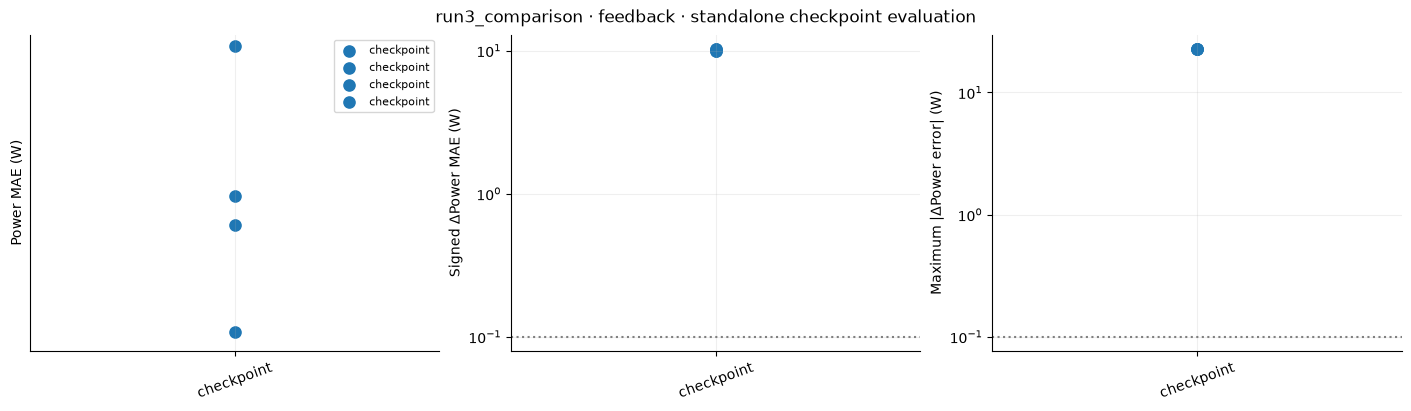

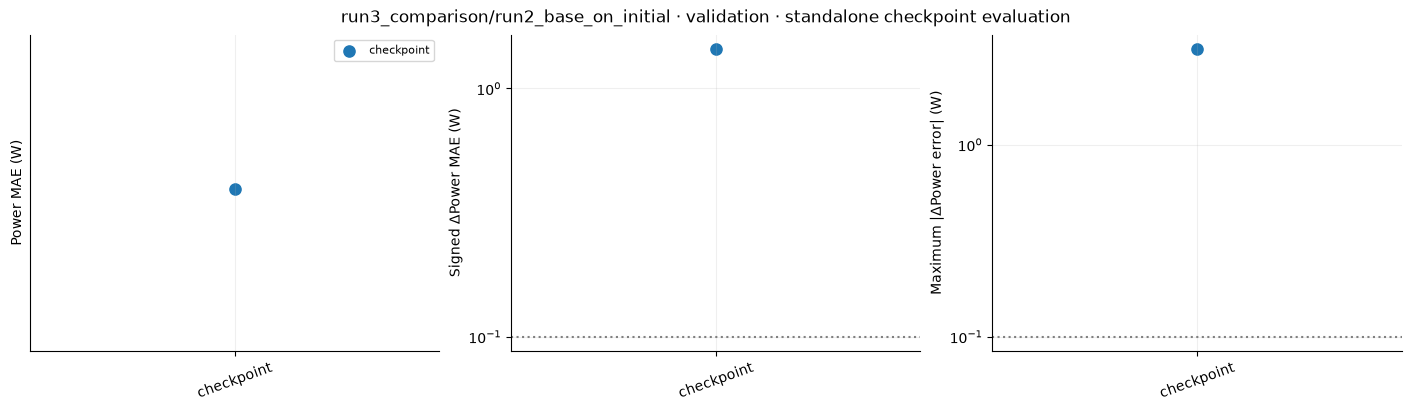

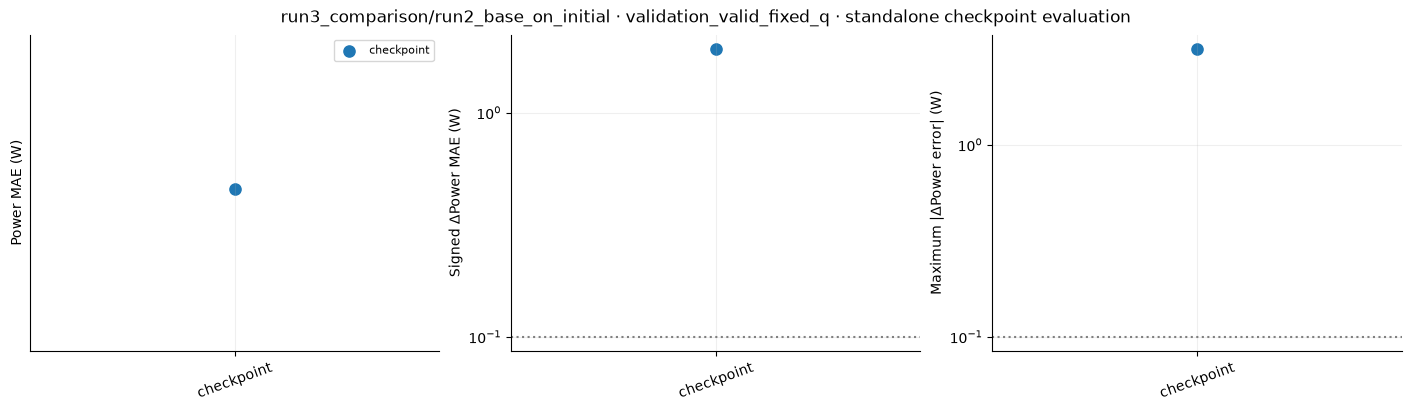

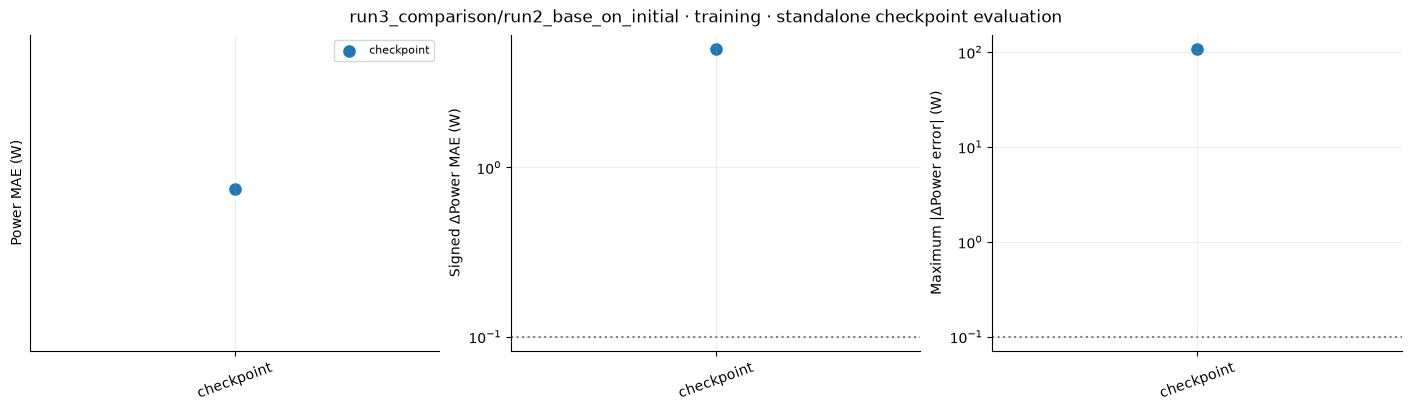

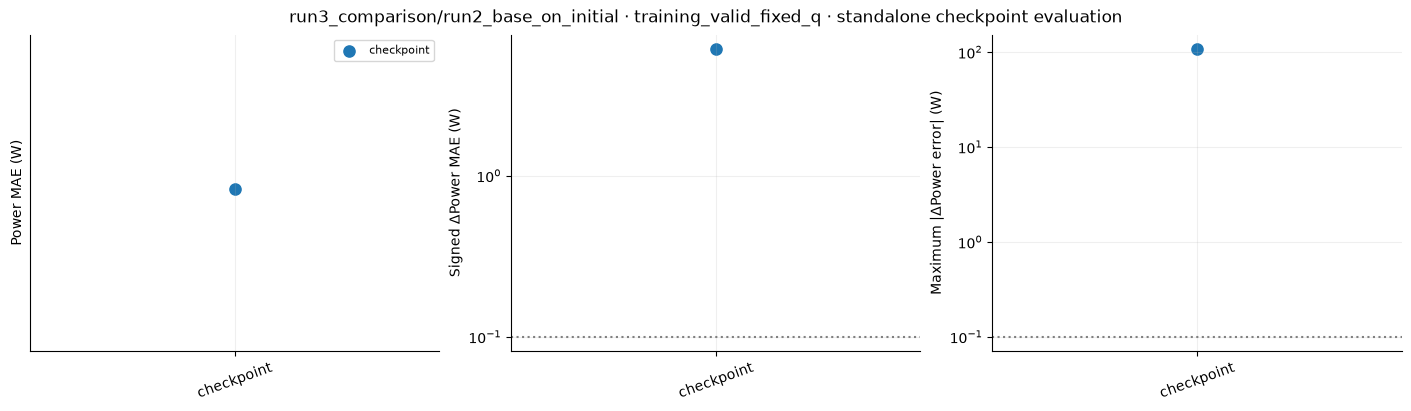

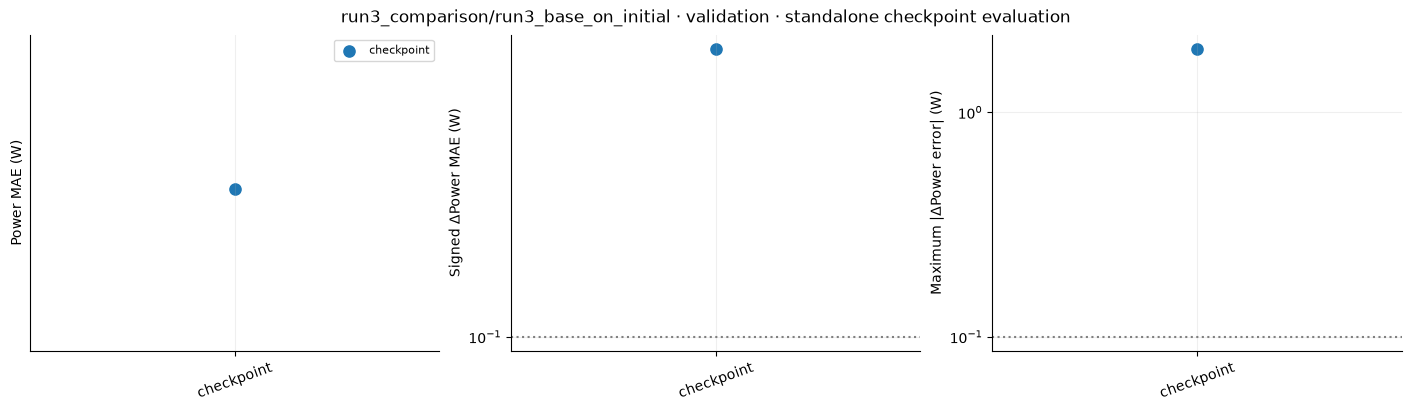

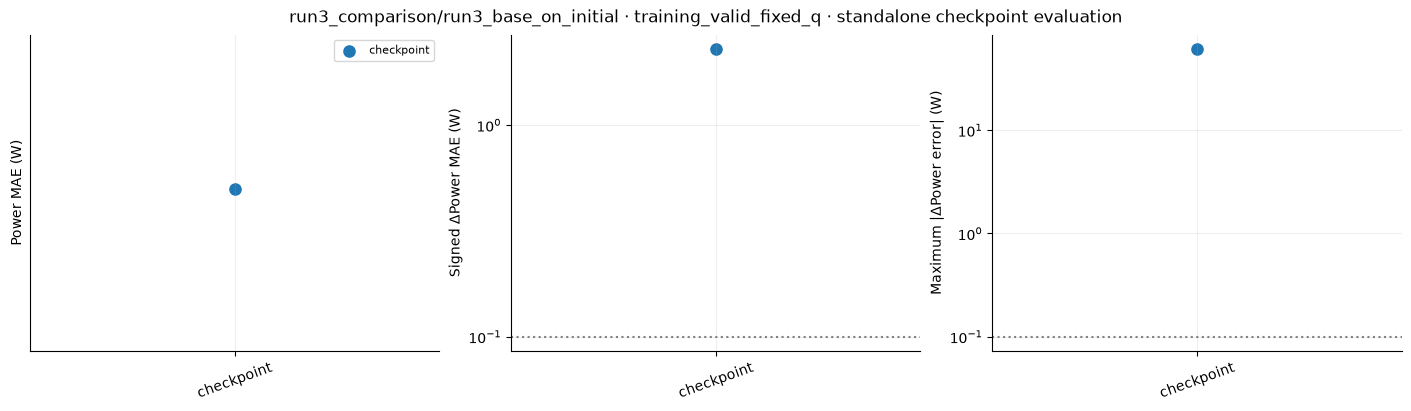

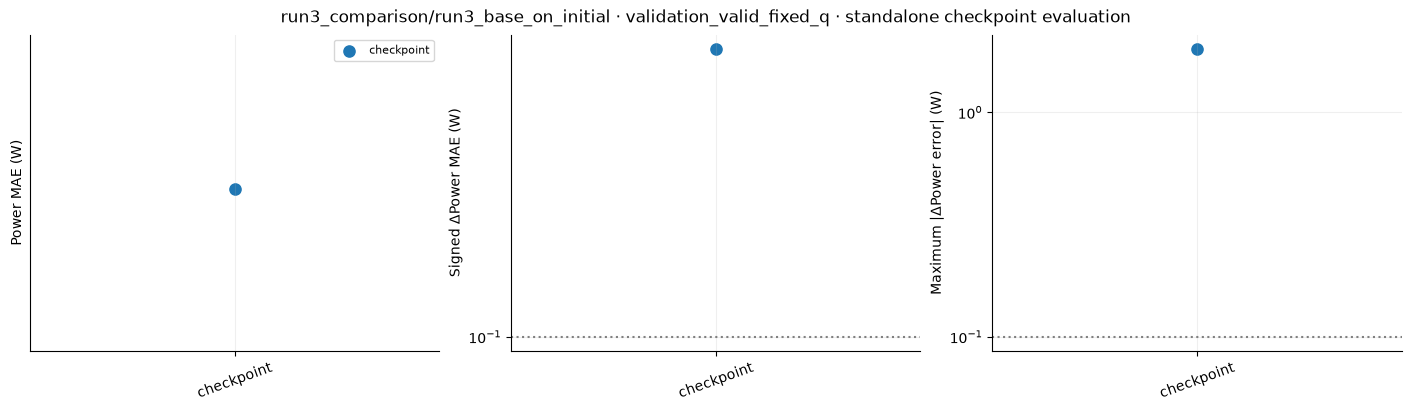

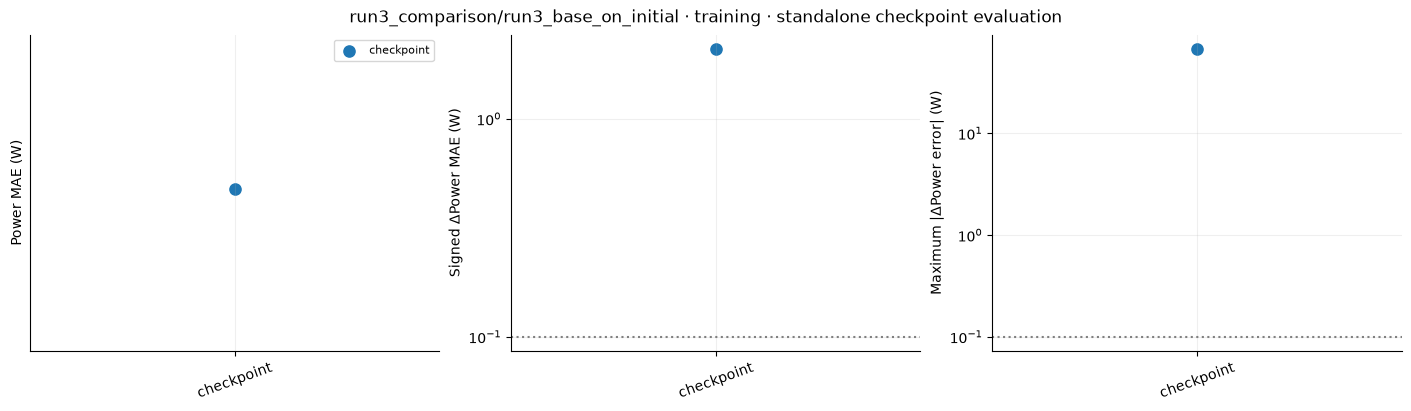

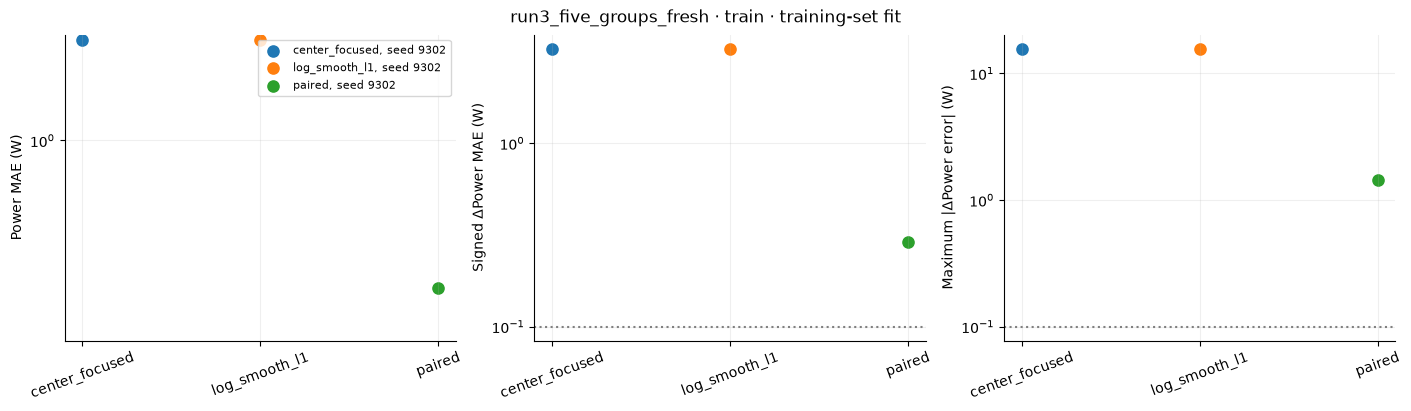

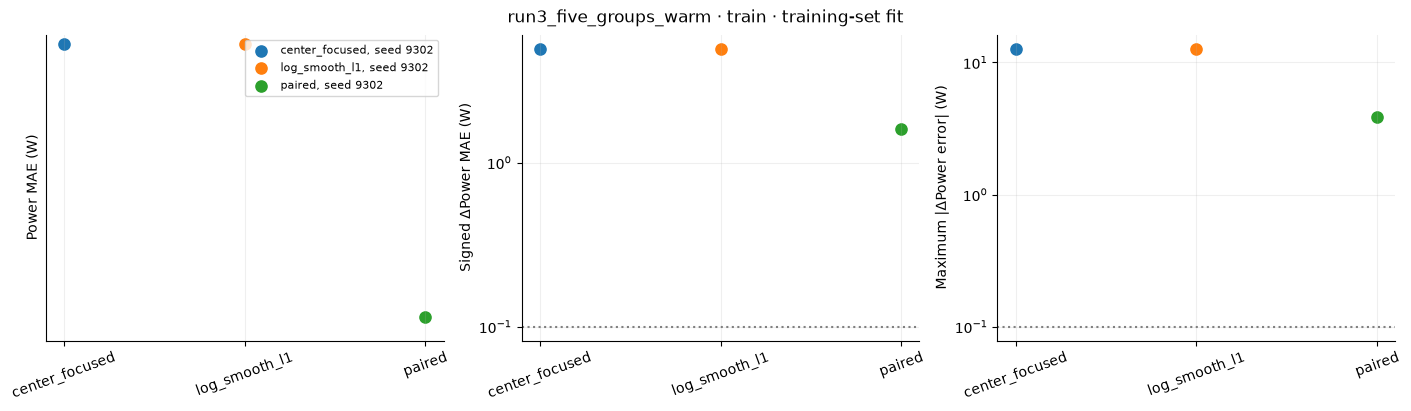

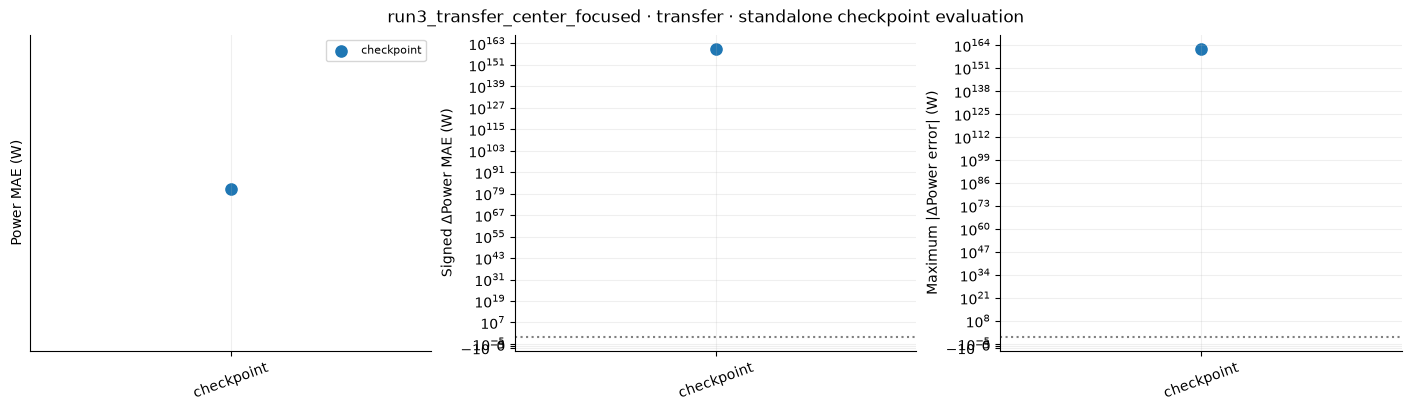

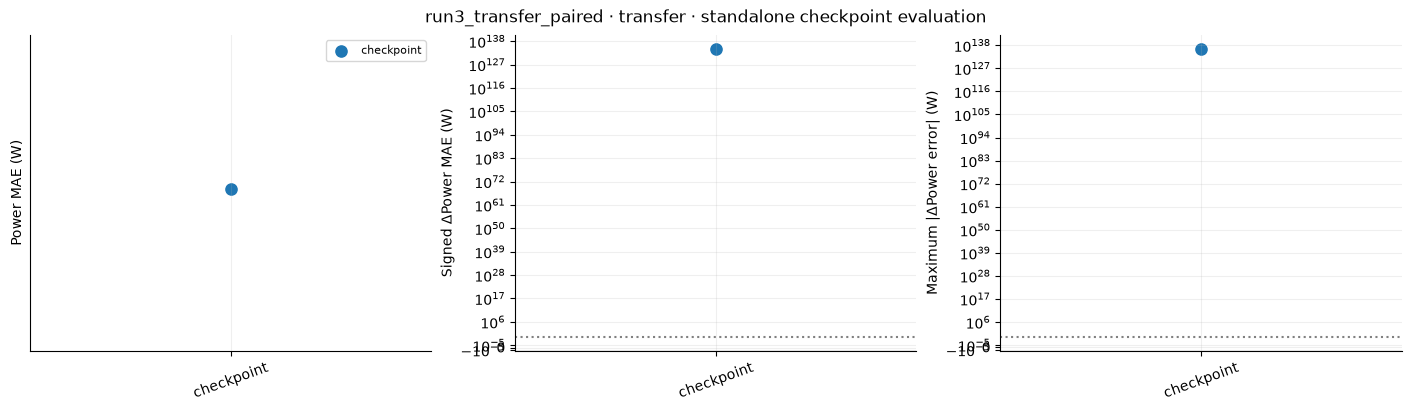

In [8]:
comparison_keys = sorted({(r['experiment'], r['split']) for r in metric_rows},
                         key=lambda key: (key[0], SPLITS.index(key[1]) if key[1] in SPLITS else 99))
for experiment, split in comparison_keys:
    selected = [r for r in metric_rows if r['experiment'] == experiment and r['split'] == split]
    variants = list(dict.fromkeys(r['variant'] for r in selected))
    seeds = list(dict.fromkeys(r['seed'] for r in selected))
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    for ax, field, label in zip(axes,
            ['power_mae', 'delta_mae', 'delta_max_abs_error'],
            ['Power MAE (W)', 'Signed ΔPower MAE (W)', 'Maximum |ΔPower error| (W)']):
        for row in selected:
            offset = (seeds.index(row['seed']) - (len(seeds) - 1) / 2) * 0.08
            ax.scatter(variants.index(row['variant']) + offset, row[field], s=65,
                       color=f'C{variants.index(row["variant"]) % 10}',
                       label=f'{row["variant"]}, seed {row["seed"]}' if row['seed'] is not None else row['variant'])
        ax.set_xticks(range(len(variants)), variants, rotation=20)
        ax.set(ylabel=label, yscale='symlog')
        ax.set_yscale('symlog', linthresh=1e-5)
        if field.startswith('delta'):
            ax.axhline(DELTA_ERROR_TARGET_W, color='grey', ls=':', label='Diagnostic target')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · {experiments[experiment]["scope"]}')
    show_figure(fig, f'metrics_{experiment}_{split}')


## Direction-level errors and sign agreement

Both average and worst-case difference errors matter. A small perturbation-cost
error can coexist with wrong individual signs because the cost sums absolute
differences. Blank heatmap cells have no saved metric; sign cells show the number
of differences above the significance threshold.


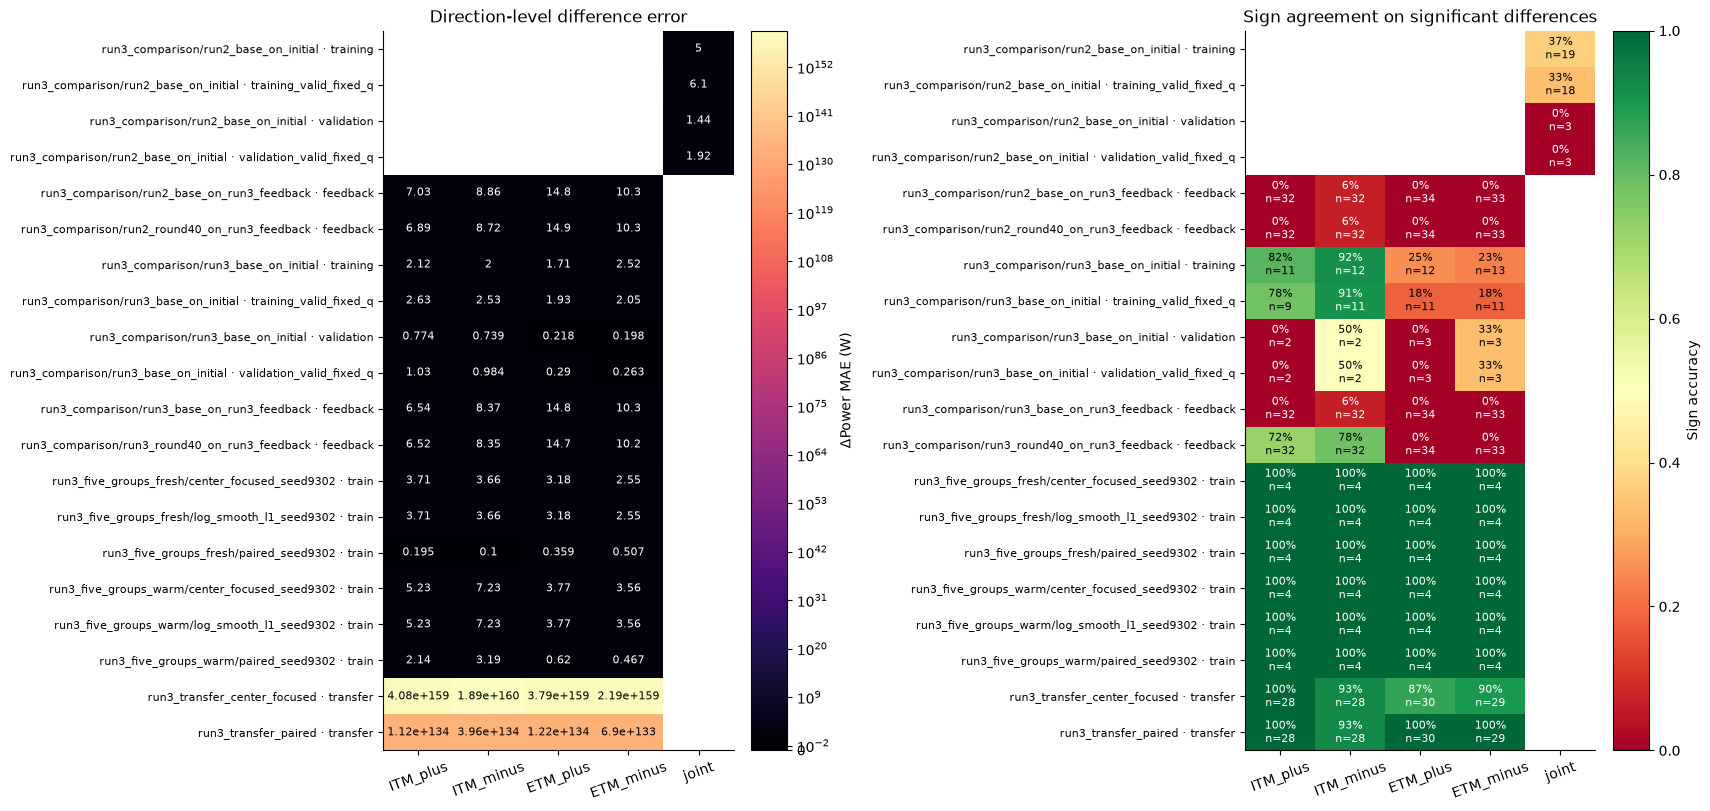

experiment,variant,seed,split,direction,count,delta_mae,delta_max_abs_error,sign_count,sign_accuracy
run3_comparison/run2_base_on_initial,checkpoint,—,training,joint,80,4.99558,107.352,19,0.368421
run3_comparison/run2_base_on_initial,checkpoint,—,training_valid_fixed_q,joint,64,6.09655,107.352,18,0.333333
run3_comparison/run2_base_on_initial,checkpoint,—,validation,joint,20,1.44116,3.14181,3,0
run3_comparison/run2_base_on_initial,checkpoint,—,validation_valid_fixed_q,joint,15,1.91938,3.14181,3,0
run3_comparison,checkpoint,—,feedback,ETM_minus,40,10.2807,17.367,33,0
run3_comparison,checkpoint,—,feedback,ETM_plus,40,14.8275,22.5761,34,0
run3_comparison,checkpoint,—,feedback,ITM_minus,40,8.85696,13.684,32,0.0625
run3_comparison,checkpoint,—,feedback,ITM_plus,40,7.03376,11.5118,32,0
run3_comparison,checkpoint,—,feedback,ETM_minus,40,10.3217,17.4578,33,0
run3_comparison,checkpoint,—,feedback,ETM_plus,40,14.8675,22.6641,34,0


In [9]:
direction_keys = list(dict.fromkeys((r['run_id'], r['split']) for r in direction_rows))
present_directions = [d for d in DIRECTIONS if any(r['direction'] == d for r in direction_rows)]
if direction_keys and present_directions:
    shape = (len(direction_keys), len(present_directions))
    error_matrix, sign_matrix = np.full(shape, np.nan), np.full(shape, np.nan)
    counts = np.zeros(shape, dtype=int)
    for row in direction_rows:
        i, j = direction_keys.index((row['run_id'], row['split'])), present_directions.index(row['direction'])
        error_matrix[i, j] = row['delta_mae']
        sign_matrix[i, j] = row['sign_accuracy'] if row['sign_accuracy'] is not None else np.nan
        counts[i, j] = row['sign_count']
    fig, axes = plt.subplots(1, 2, figsize=(17, max(5, 0.4 * len(direction_keys))), constrained_layout=True)
    vmax = max(float(np.nanmax(error_matrix)), 0.01)
    error_image = axes[0].imshow(error_matrix, aspect='auto', cmap='magma',
                           norm=SymLogNorm(linthresh=0.01, vmin=0, vmax=vmax))
    fig.colorbar(error_image, ax=axes[0], label='ΔPower MAE (W)')
    sign_image = axes[1].imshow(sign_matrix, aspect='auto', cmap='RdYlGn', vmin=0, vmax=1)
    fig.colorbar(sign_image, ax=axes[1], label='Sign accuracy')
    labels = [f'{run_id} · {split}' for run_id, split in direction_keys]
    for ax in axes:
        ax.set_xticks(range(len(present_directions)), present_directions, rotation=20)
        ax.set_yticks(range(len(labels)), labels, fontsize=8)
        ax.grid(False)
    for i in range(shape[0]):
        for j in range(shape[1]):
            if np.isfinite(error_matrix[i, j]):
                rgb = error_image.cmap(error_image.norm(error_matrix[i, j]))[:3]
                color = 'black' if np.dot(rgb, [0.299, 0.587, 0.114]) > 0.5 else 'white'
                axes[0].text(j, i, f'{error_matrix[i, j]:.3g}', ha='center', va='center', color=color, fontsize=8)
            if np.isfinite(sign_matrix[i, j]):
                rgb = sign_image.cmap(sign_image.norm(sign_matrix[i, j]))[:3]
                color = 'black' if np.dot(rgb, [0.299, 0.587, 0.114]) > 0.5 else 'white'
                axes[1].text(j, i, f'{sign_matrix[i, j]:.0%}\nn={counts[i, j]}', ha='center', va='center', color=color, fontsize=8)
    axes[0].set_title('Direction-level difference error')
    axes[1].set_title('Sign agreement on significant differences')
    show_figure(fig, 'direction_metrics')
table(direction_rows, columns=['experiment', 'variant', 'seed', 'split', 'direction', 'count',
    'delta_mae', 'delta_max_abs_error', 'sign_count', 'sign_accuracy'],
    title='Complete direction metrics', collapsed=True)


## Training trajectories and selected checkpoints

Solid curves show training; dashed curves show the monitored split. Vertical dotted
lines mark each variant's selected epoch. When the monitor is `train`, the two curves
describe the same samples. Epoch zero is retained. Loss components are displayed
within their experiment; different objectives need not have comparable loss values.


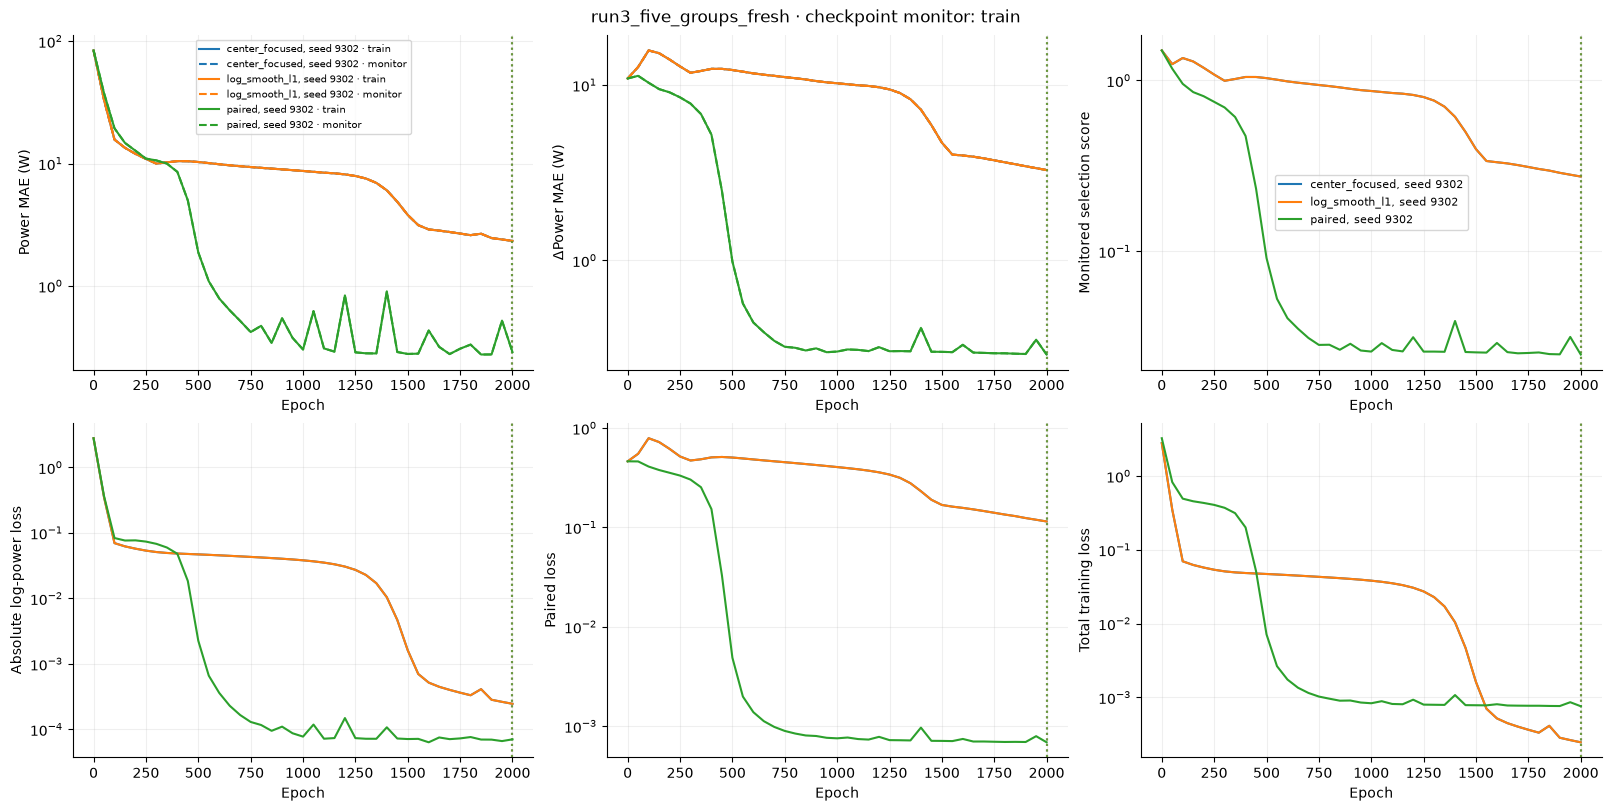

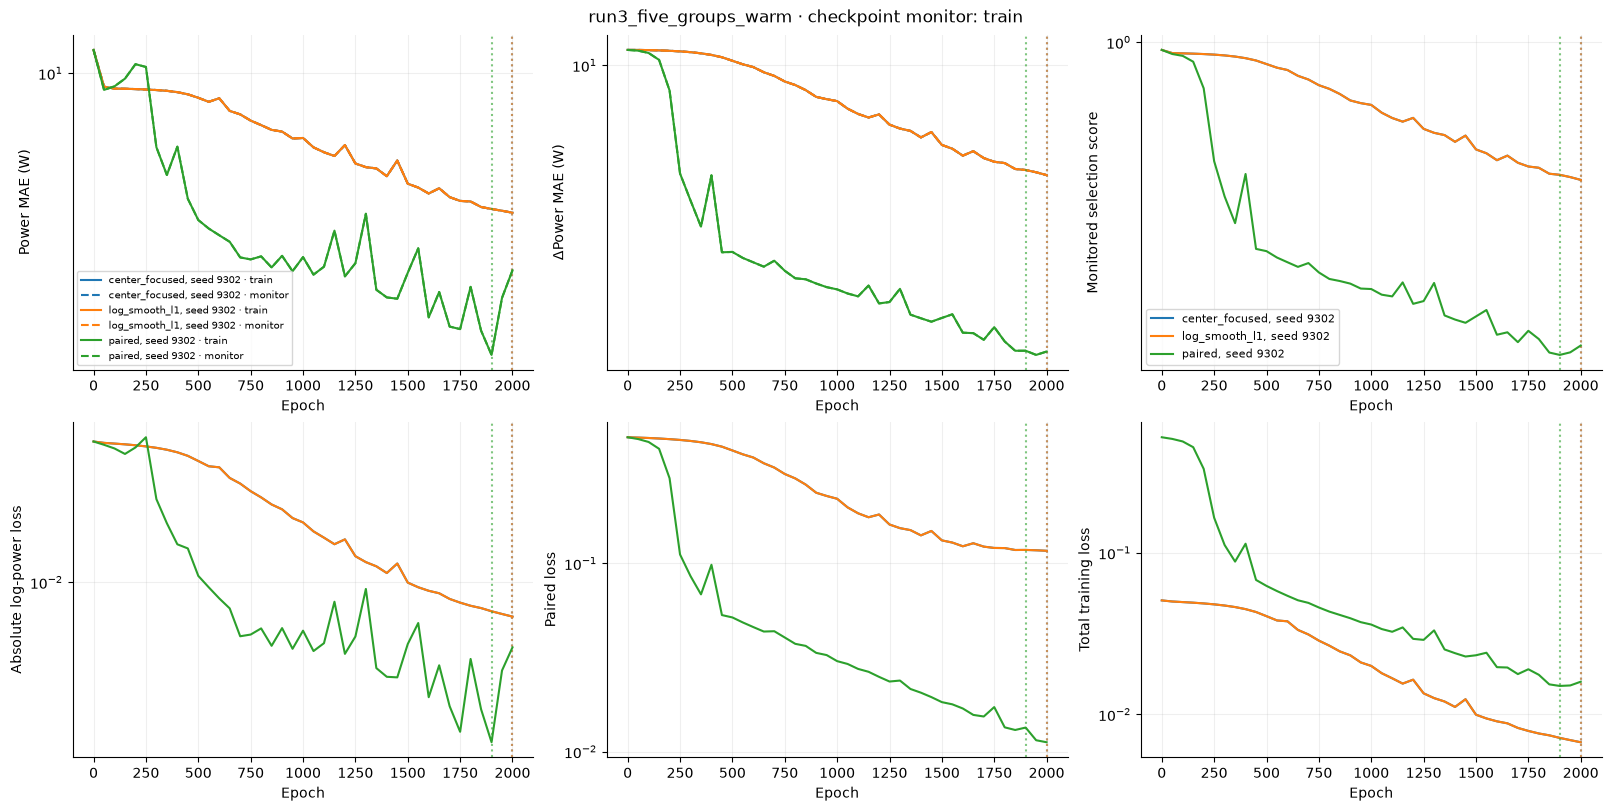

In [10]:
for experiment in experiments:
    selected_runs = [r for r in runs.values() if r['tags']['experiment'] == experiment and r['history']]
    if not selected_runs:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    for index, run in enumerate(selected_runs):
        history, tags = run['history'], run['tags']
        color = f'C{index % 10}'
        label = f'{tags["variant"]}, seed {tags["seed"]}'
        epoch = values(history, 'epoch')
        for ax, field, ylabel in zip(axes[0, :2], ['power_mae', 'delta_mae'], ['Power MAE (W)', 'ΔPower MAE (W)']):
            ax.plot(epoch, values(history, f'train_{field}'), color=color, label=f'{label} · train')
            ax.plot(epoch, values(history, f'monitor_{field}'), '--', color=color, label=f'{label} · monitor')
            ax.set(xlabel='Epoch', ylabel=ylabel)
            ax.set_yscale('symlog', linthresh=1e-5)
        for ax, field, ylabel in zip([axes[0, 2], *axes[1]],
                ['selection_score', 'absolute_loss', 'paired_loss', 'training_loss'],
                ['Monitored selection score', 'Absolute log-power loss', 'Paired loss', 'Total training loss']):
            ax.plot(epoch, values(history, field), color=color, label=label)
            ax.set(xlabel='Epoch', ylabel=ylabel)
            ax.set_yscale('symlog', linthresh=1e-5)
        best_epoch = run['metrics'].get('best_epoch')
        if best_epoch is not None:
            for ax in axes.flat:
                ax.axvline(best_epoch, color=color, ls=':', alpha=0.6)
    axes[0, 0].legend(fontsize=7)
    axes[0, 2].legend(fontsize=8)
    fig.suptitle(f'{experiment} · checkpoint monitor: {selected_runs[0]["metrics"].get("monitor_split")}')
    show_figure(fig, f'training_{experiment}')


## Power, signed differences, and residuals

Each panel compares checkpoints evaluated on the same experiment and split. The
diagonal is exact agreement; residuals are **MLP − saved Finesse** values. Nominal
rows are excluded from difference plots so their identically zero differences do
not inflate agreement. Every saved prediction participates in these plots.


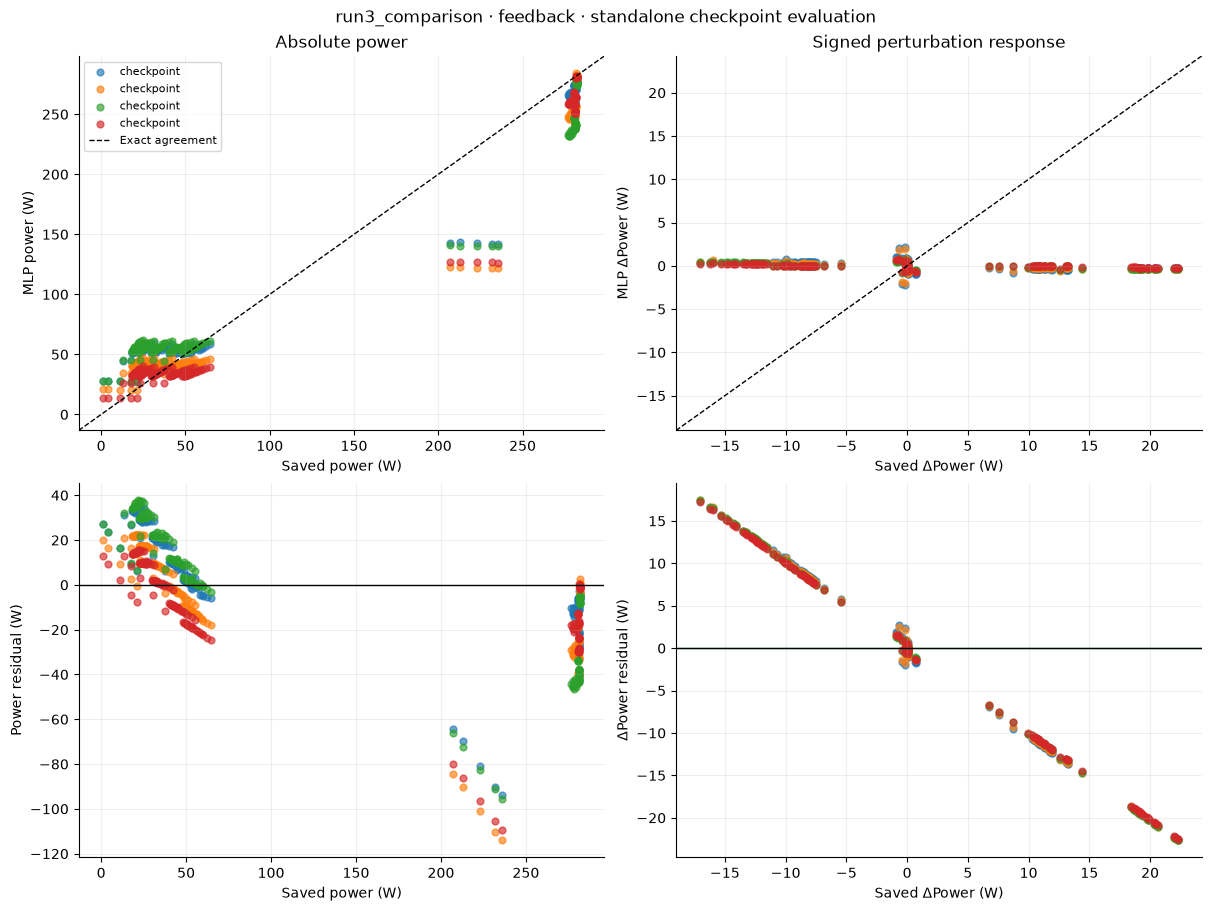

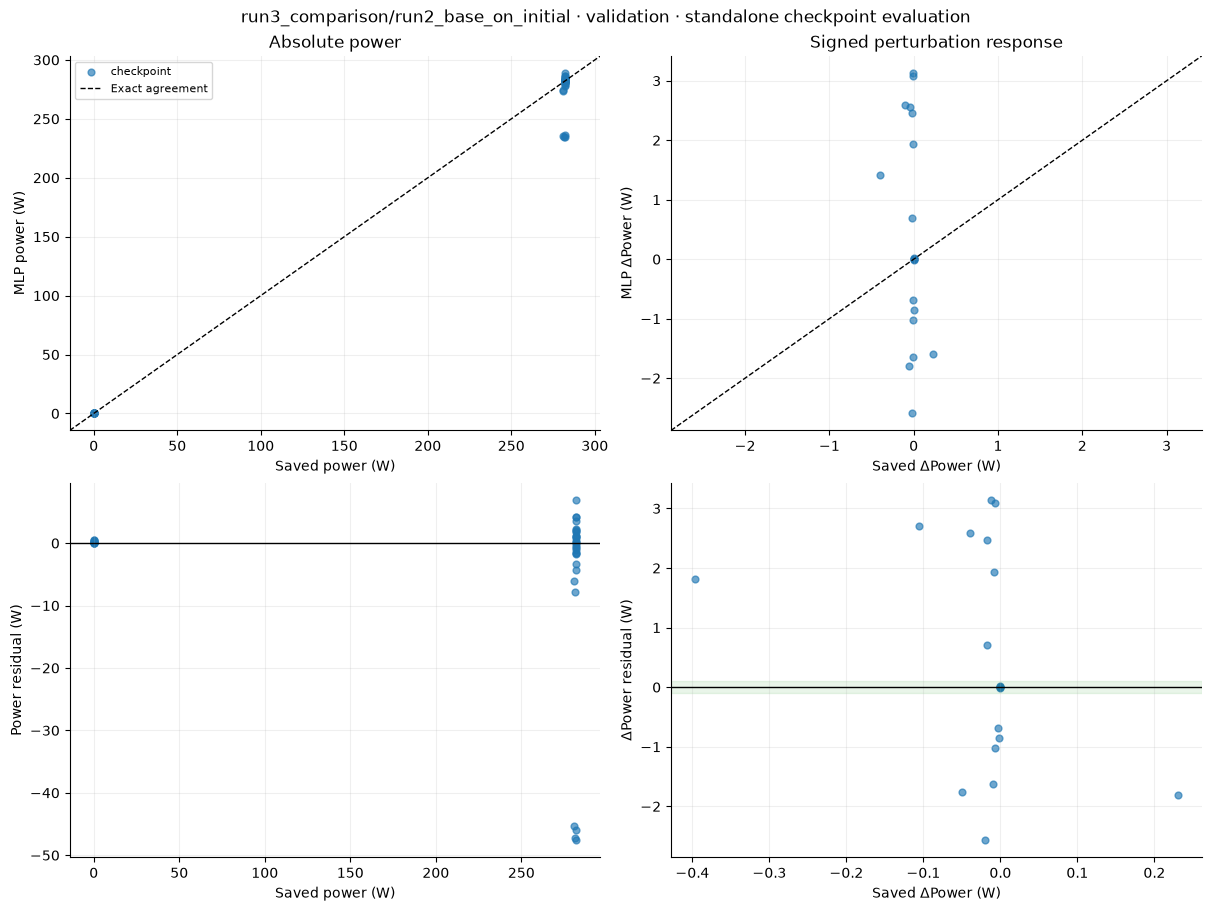

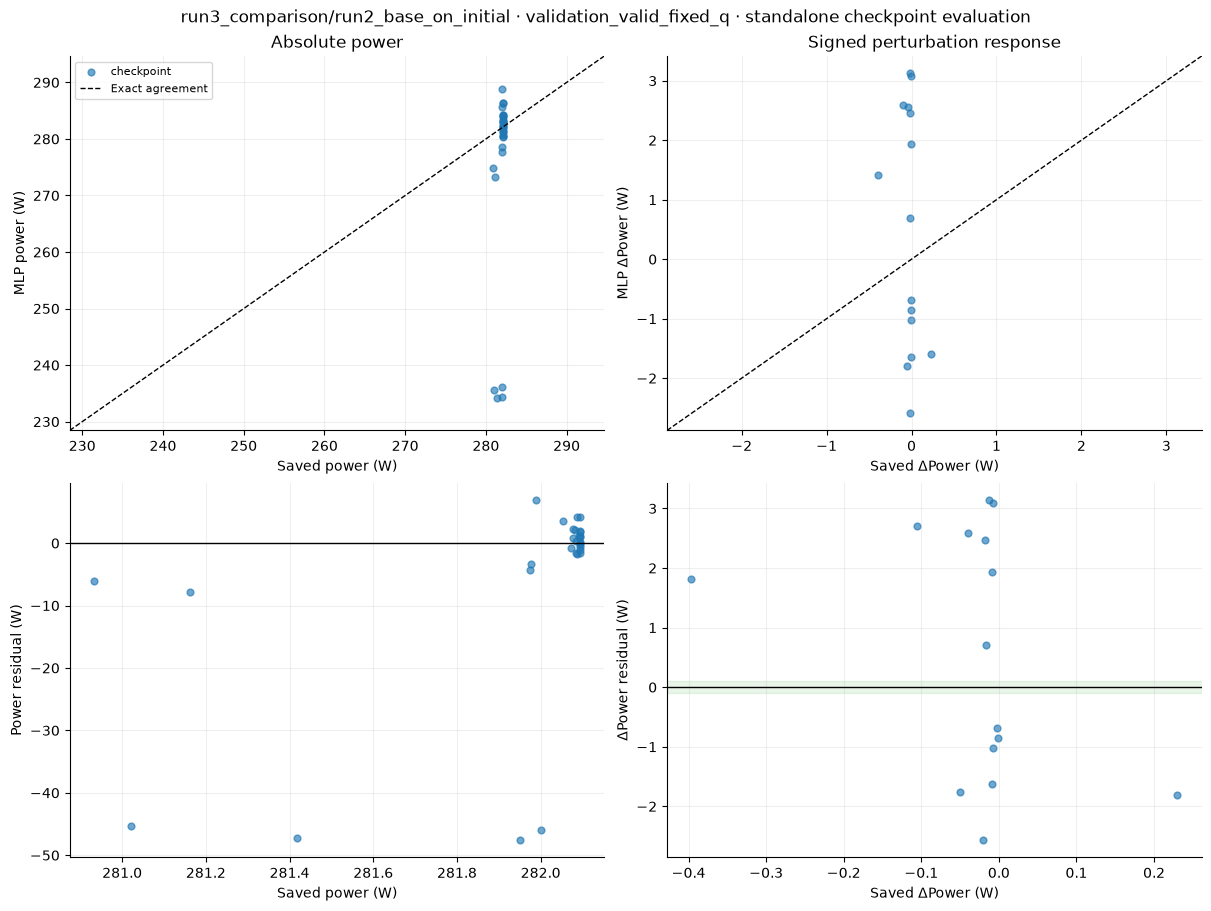

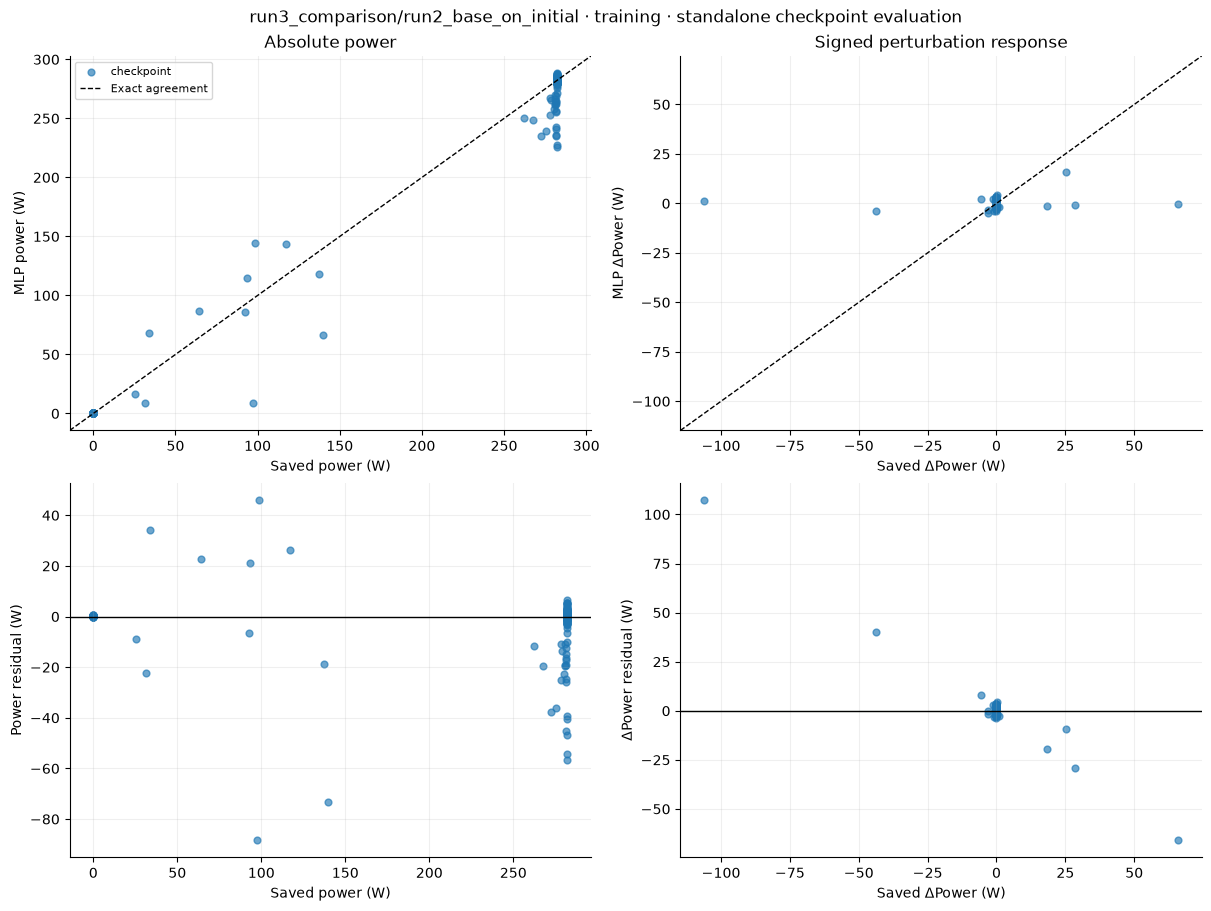

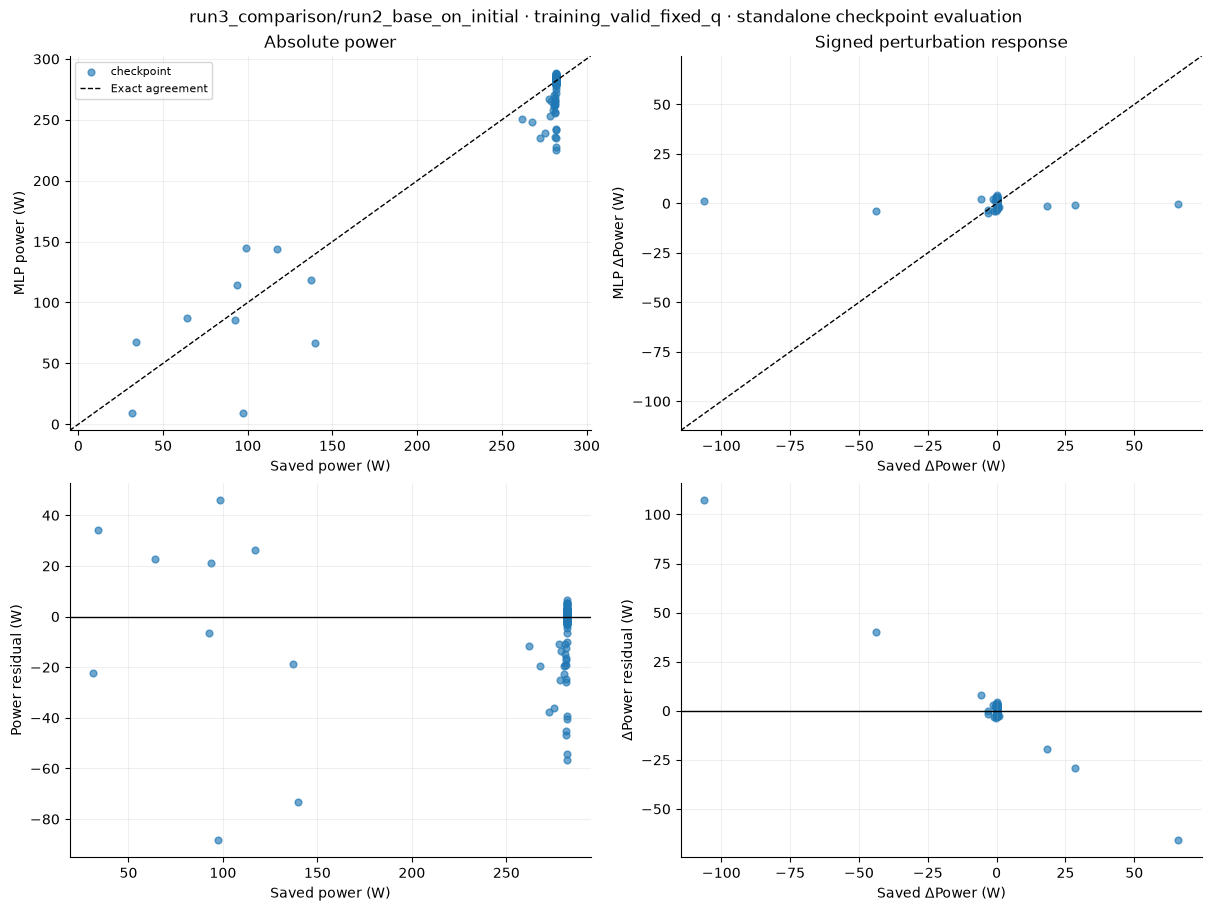

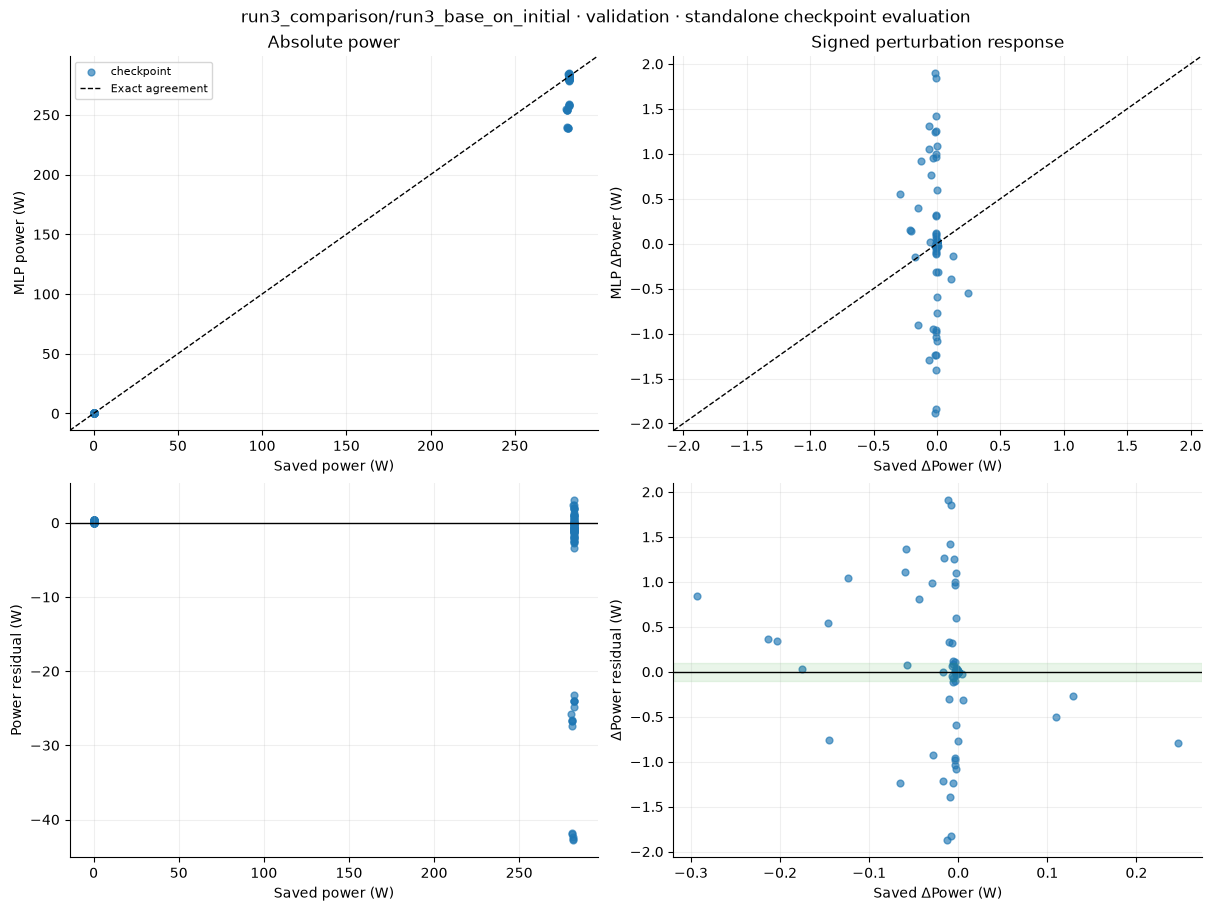

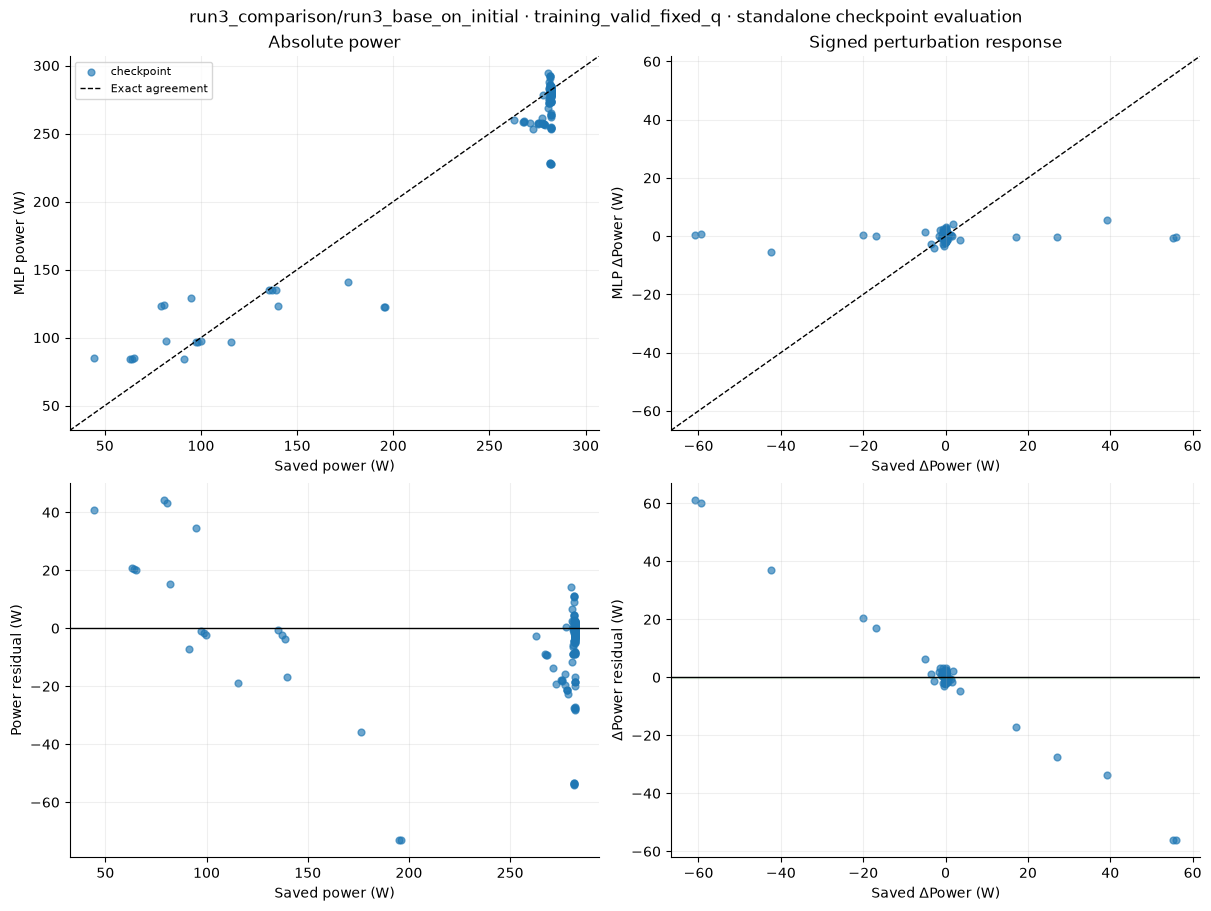

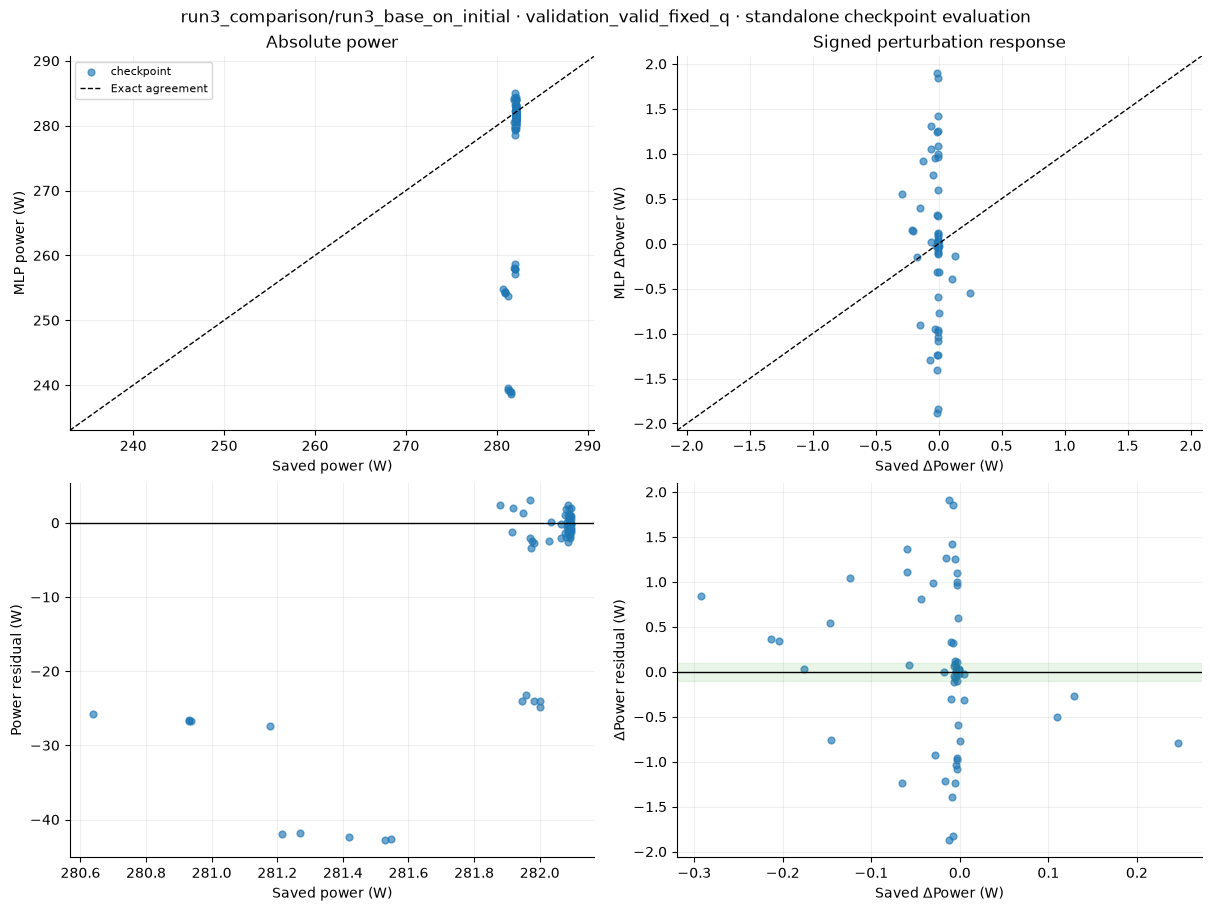

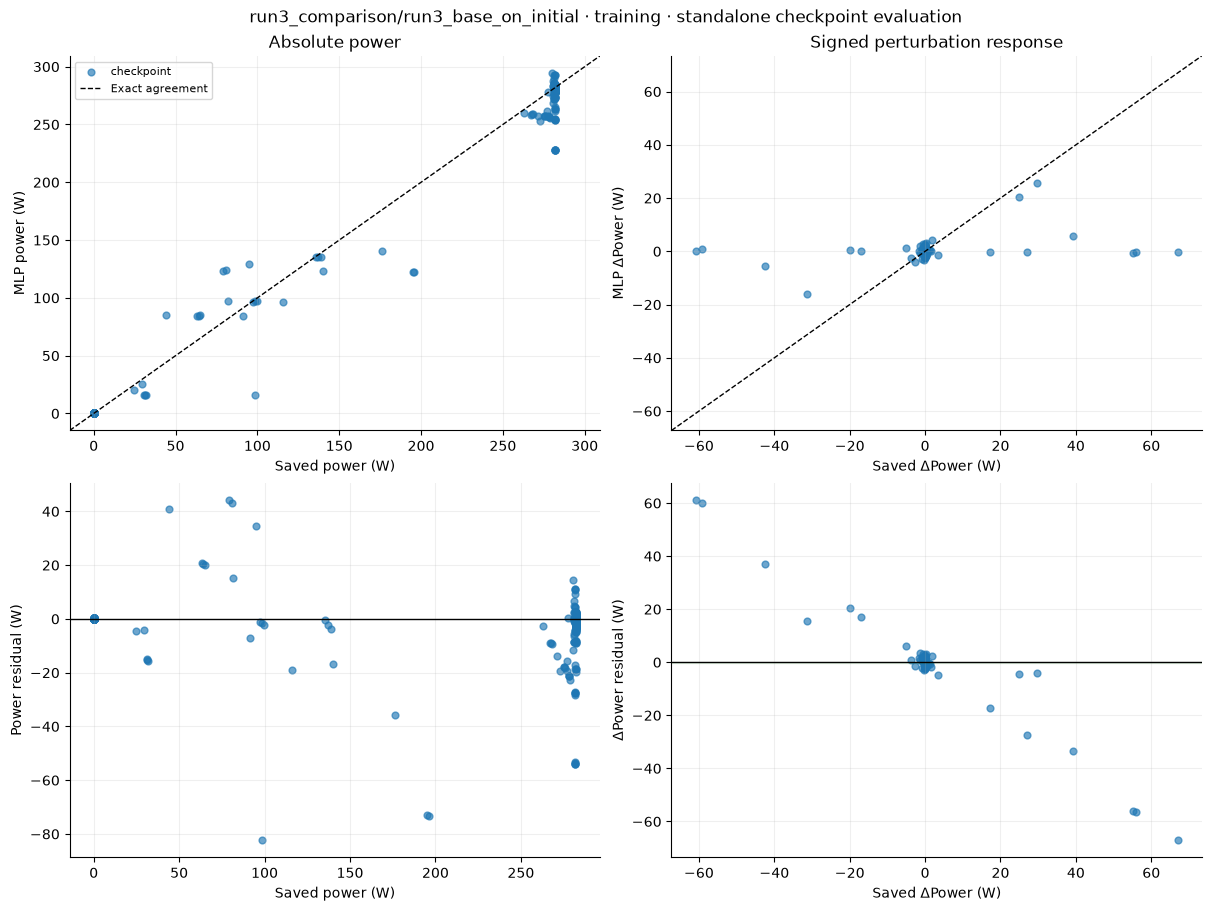

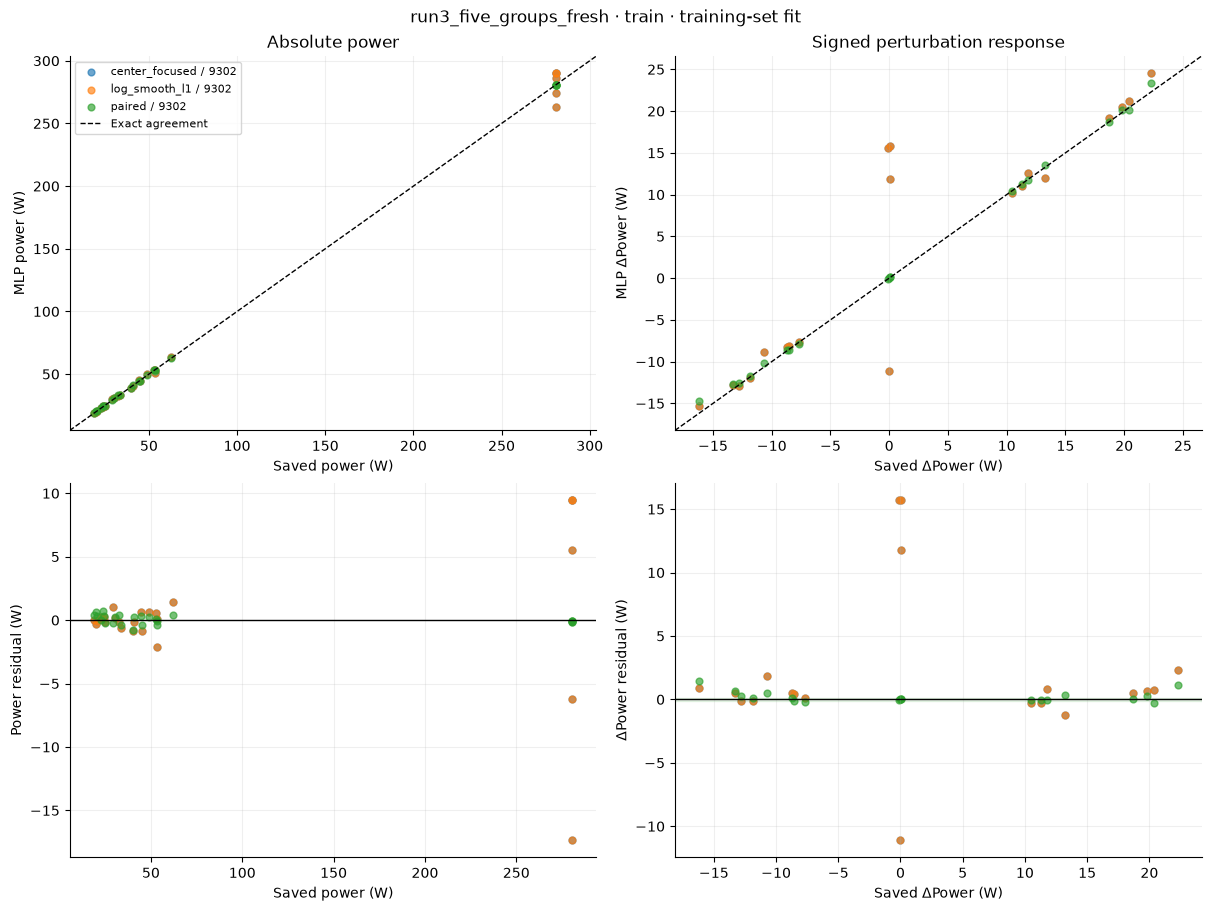

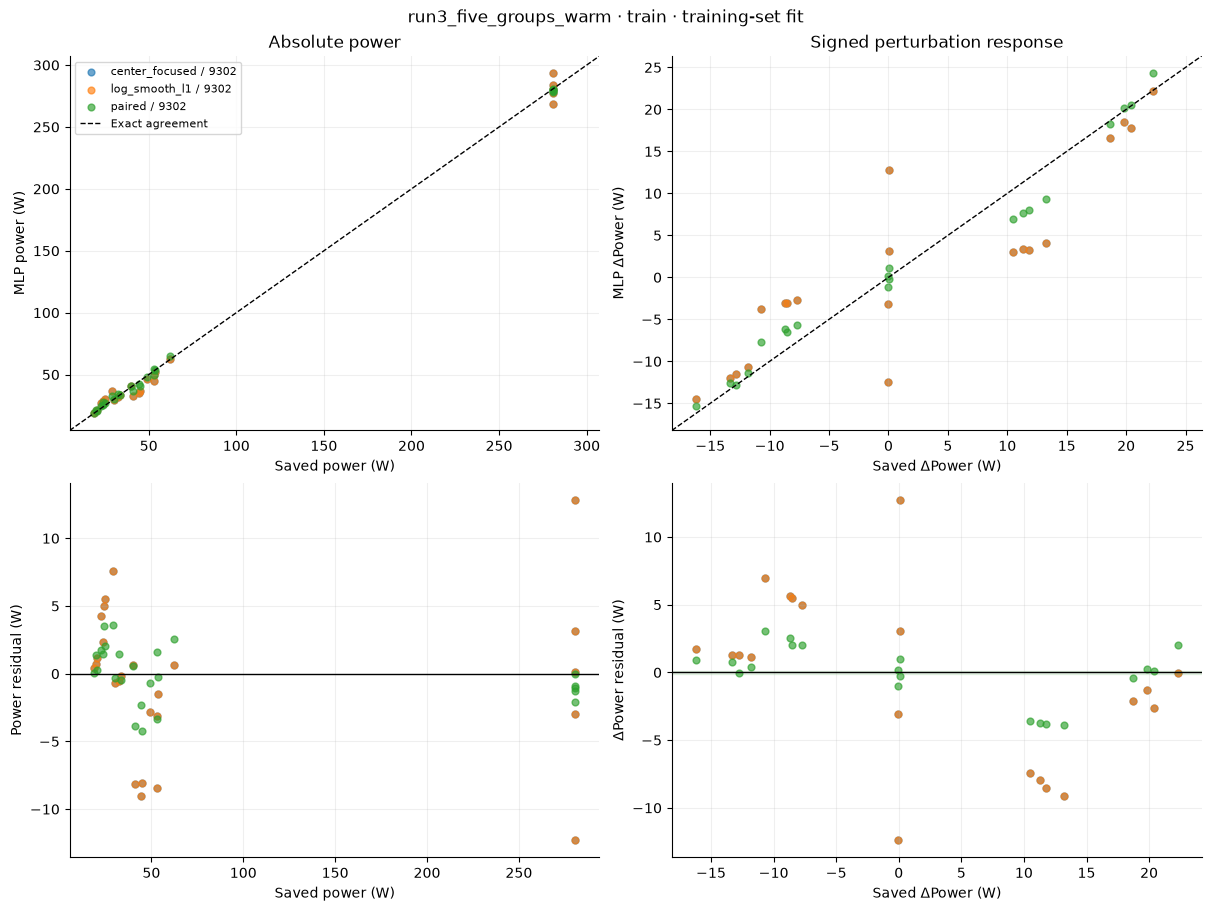

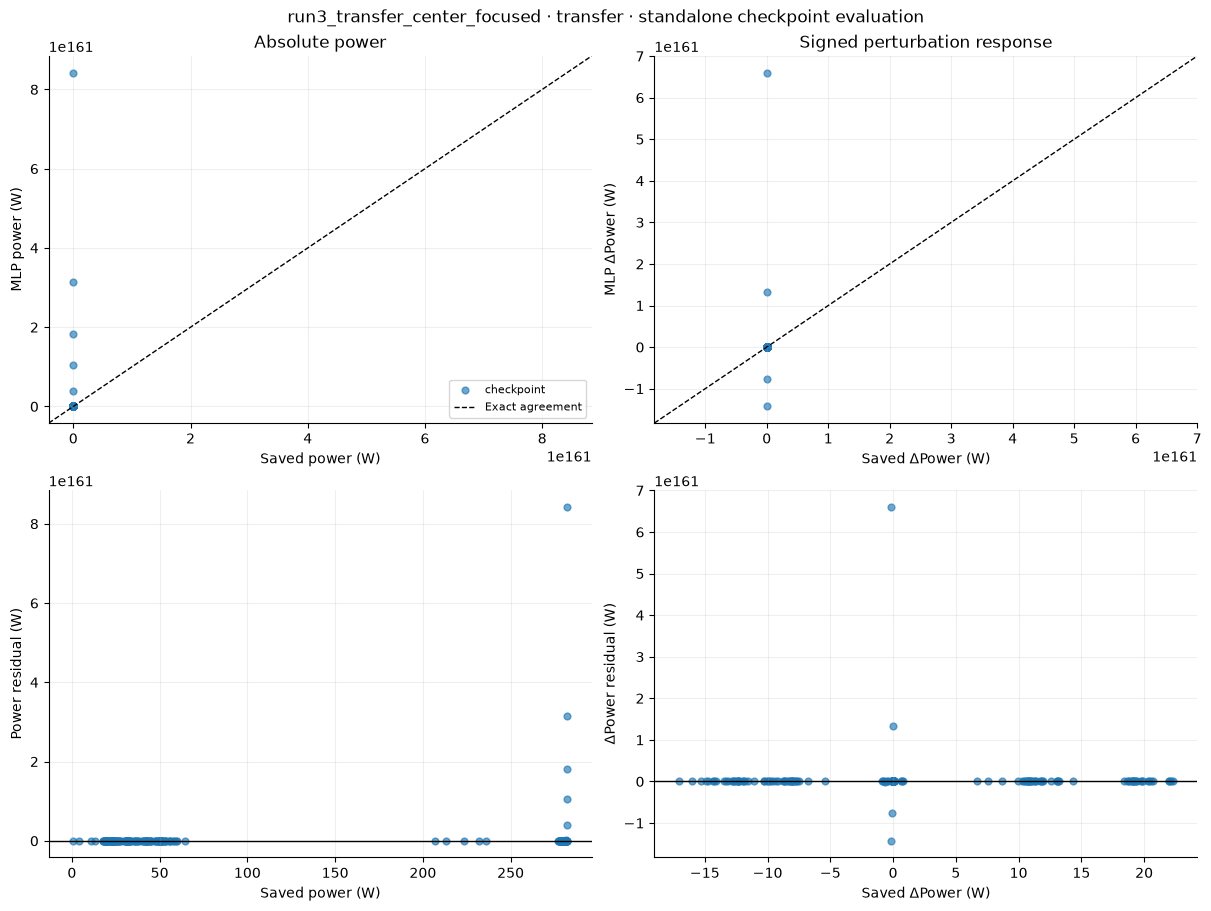

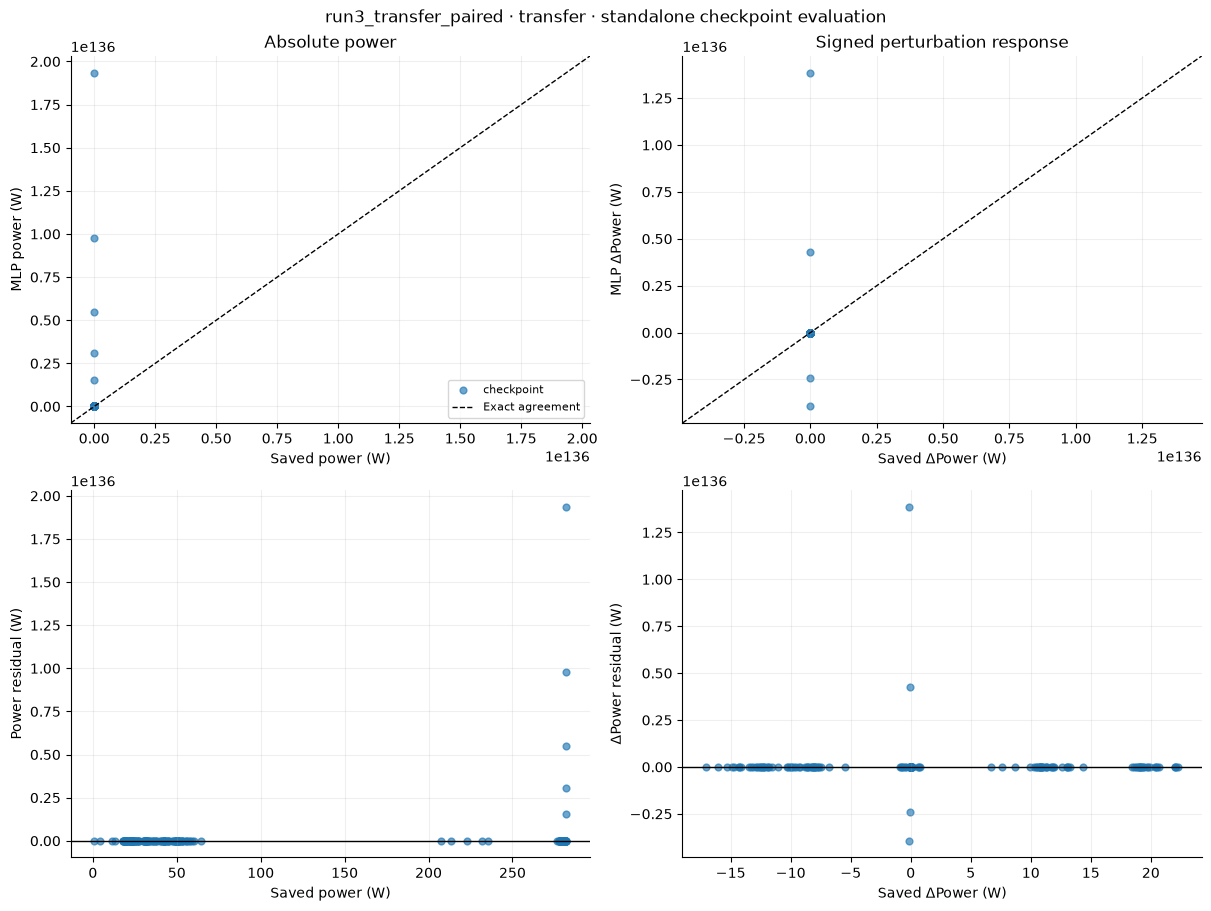

In [11]:
for experiment, split in comparison_keys:
    selected_runs = [r for r in runs.values() if r['tags']['experiment'] == experiment
                     and any(p['split'] == split for p in r['predictions'])]
    if not selected_runs:
        continue
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
    all_power_x, all_power_y, all_delta_x, all_delta_y = [], [], [], []
    for index, run in enumerate(selected_runs):
        rows = [r for r in run['predictions'] if r['split'] == split]
        paired = [r for r in rows if r['direction'] != 'nominal']
        label = run['tags']['variant'] + (f' / {run["tags"]["seed"]}' if run['tags']['seed'] is not None else '')
        color = f'C{index % 10}'
        px, py = values(rows, 'power'), values(rows, 'predicted_power')
        dx, dy = values(paired, 'delta_power'), values(paired, 'predicted_delta_power')
        axes[0, 0].scatter(px, py, color=color, label=label, alpha=0.65, s=24)
        axes[0, 1].scatter(dx, dy, color=color, label=label, alpha=0.65, s=24)
        axes[1, 0].scatter(px, values(rows, 'power_error'), color=color, alpha=0.65, s=24)
        axes[1, 1].scatter(dx, values(paired, 'delta_error'), color=color, alpha=0.65, s=24)
        all_power_x.extend(px); all_power_y.extend(py)
        all_delta_x.extend(dx); all_delta_y.extend(dy)
    parity_line(axes[0, 0], all_power_x, all_power_y)
    parity_line(axes[0, 1], all_delta_x, all_delta_y)
    axes[0, 0].set(xlabel='Saved power (W)', ylabel='MLP power (W)', title='Absolute power')
    axes[0, 1].set(xlabel='Saved ΔPower (W)', ylabel='MLP ΔPower (W)', title='Signed perturbation response')
    axes[1, 0].set(xlabel='Saved power (W)', ylabel='Power residual (W)')
    axes[1, 1].set(xlabel='Saved ΔPower (W)', ylabel='ΔPower residual (W)')
    for ax in axes[1]:
        ax.axhline(0, color='black', lw=1)
    axes[1, 1].axhspan(-DELTA_ERROR_TARGET_W, DELTA_ERROR_TARGET_W, color='tab:green', alpha=0.1)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · {experiments[experiment]["scope"]}')
    show_figure(fig, f'parity_residuals_{experiment}_{split}')


## Four-direction perturbation cost

The standard `costs.json` tables contain **sum |DeltaPower / DeltaROC|**, in W/m,
for complete five-point groups, including run 3 initial designs. The plots here
show the perturbation term. The run-comparison section separately reconstructs
weighted nominal and total production costs from their saved settings. Historical
joint initial pairs cannot define the four-direction cost. Unscorable entries
remain visible as missing values.


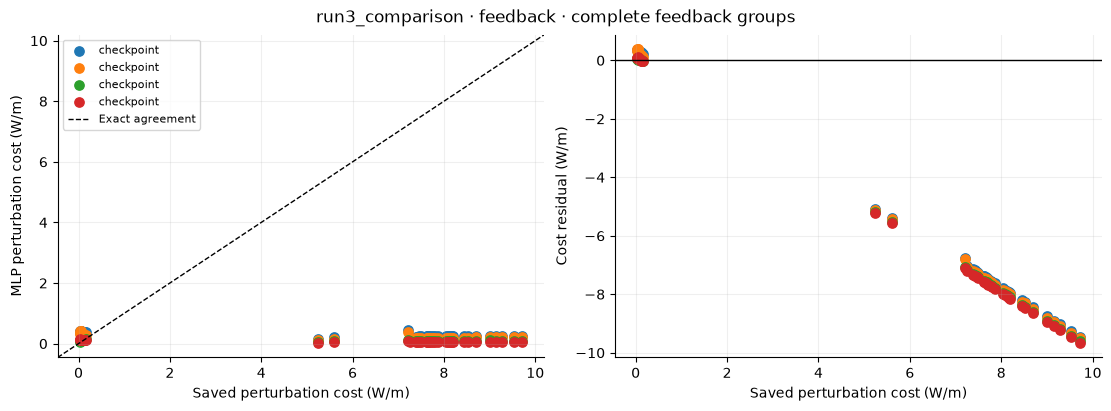

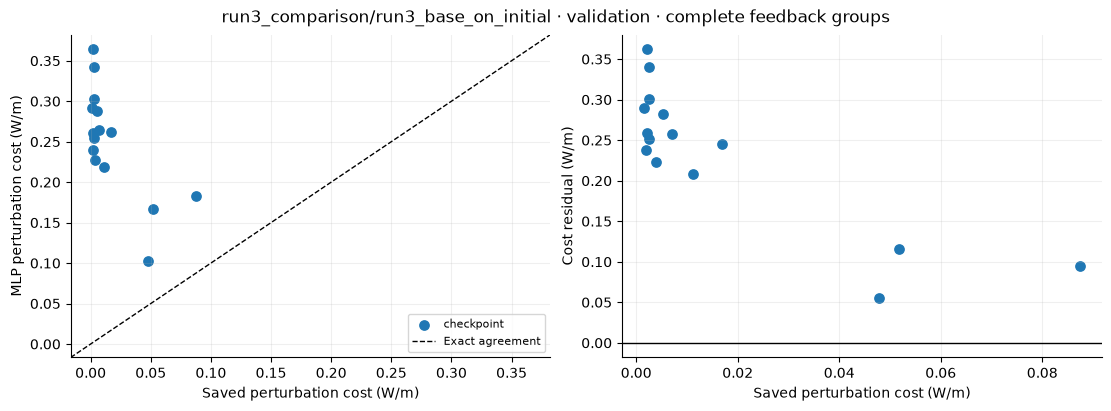

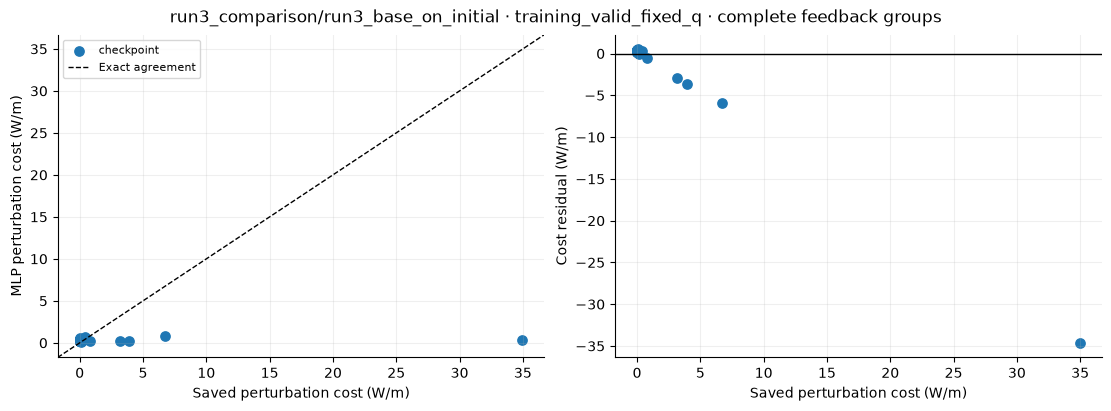

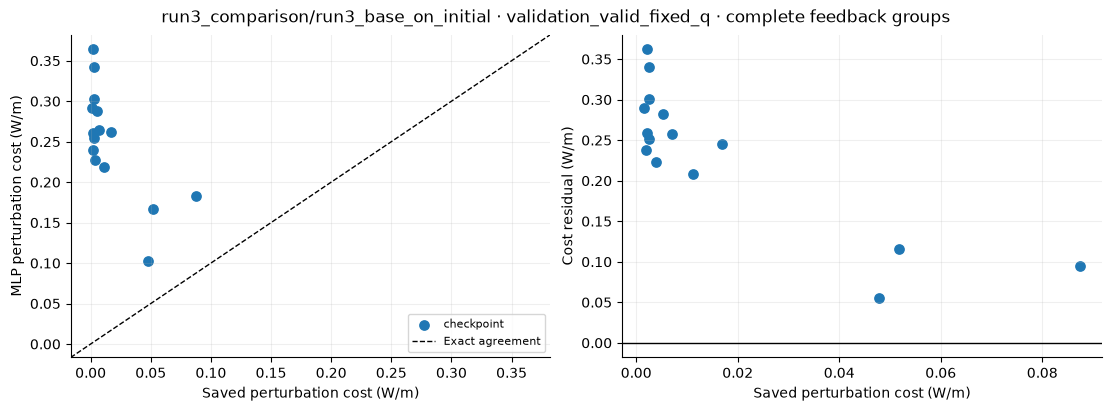

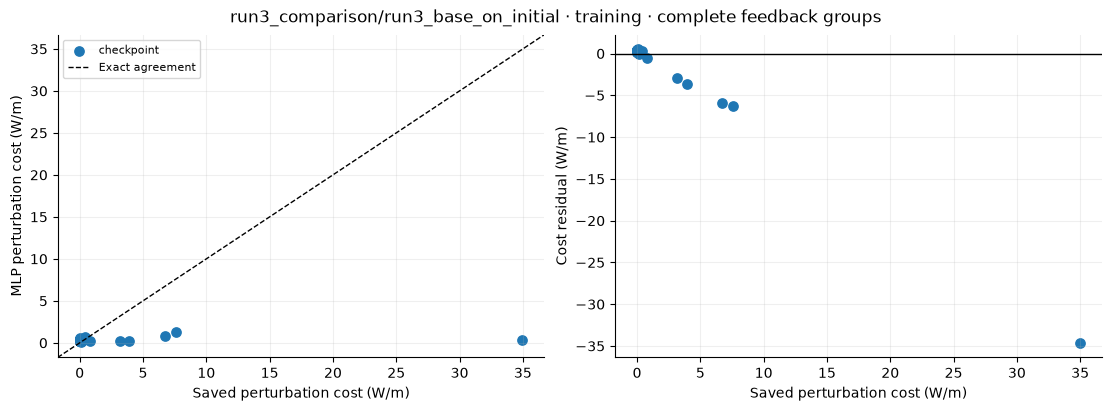

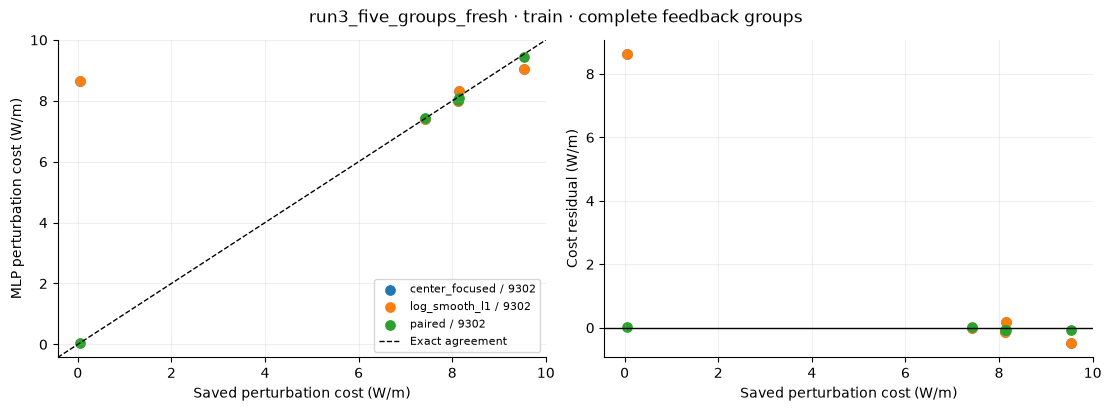

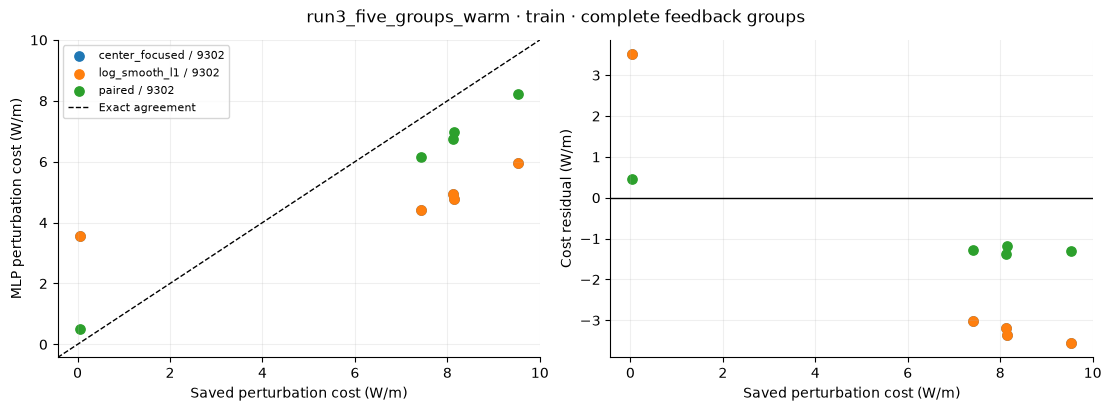

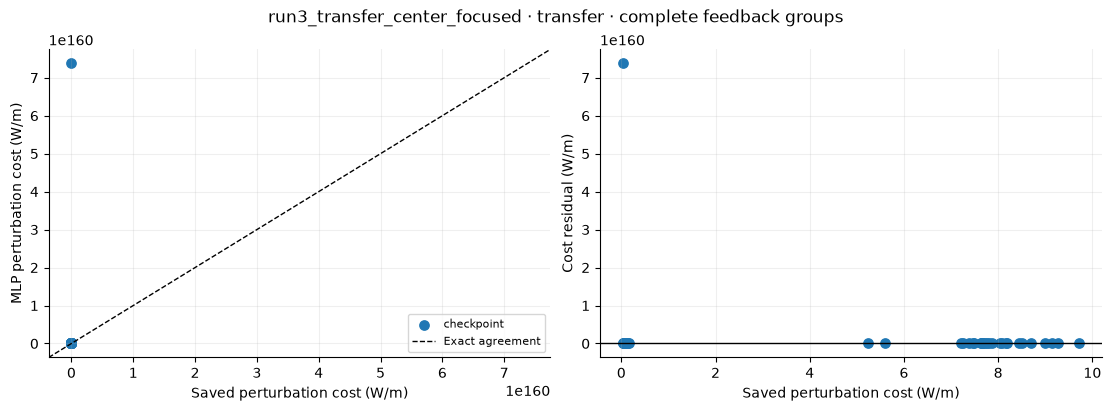

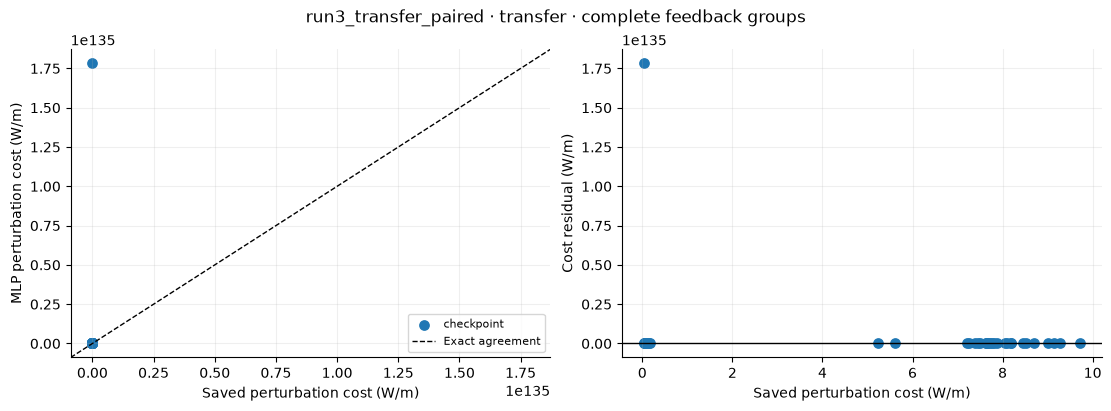

experiment,variant,seed,split,group_id,true_perturbation_cost,predicted_perturbation_cost,cost_error
run3_comparison,checkpoint,—,feedback,round:1:0,0.0426521,0.405742,0.363089
run3_comparison,checkpoint,—,feedback,round:2:0,0.0458918,0.402839,0.356947
run3_comparison,checkpoint,—,feedback,round:3:0,0.118499,0.399324,0.280825
run3_comparison,checkpoint,—,feedback,round:4:0,0.0303364,0.397121,0.366784
run3_comparison,checkpoint,—,feedback,round:5:0,0.141822,0.397476,0.255654
run3_comparison,checkpoint,—,feedback,round:6:0,0.168179,0.395802,0.227623
run3_comparison,checkpoint,—,feedback,round:7:0,5.2386,0.144989,-5.09361
run3_comparison,checkpoint,—,feedback,round:8:0,0.0364887,0.383917,0.347428
run3_comparison,checkpoint,—,feedback,round:9:0,8.17615,0.243987,-7.93217
run3_comparison,checkpoint,—,feedback,round:10:0,7.41922,0.235056,-7.18416


In [12]:
for experiment, split in comparison_keys:
    rows = [r for r in cost_rows if r['experiment'] == experiment and r['split'] == split
            and r['cost_error'] is not None]
    if not rows:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    run_ids = list(dict.fromkeys(r['run_id'] for r in rows))
    for index, run_id in enumerate(run_ids):
        current = [r for r in rows if r['run_id'] == run_id]
        label = runs[run_id]['tags']['variant']
        if runs[run_id]['tags']['seed'] is not None:
            label += f' / {runs[run_id]["tags"]["seed"]}'
        axes[0].scatter(values(current, 'true_perturbation_cost'), values(current, 'predicted_perturbation_cost'), label=label, s=45)
        axes[1].scatter(values(current, 'true_perturbation_cost'), values(current, 'cost_error'), label=label, s=45)
    parity_line(axes[0], values(rows, 'true_perturbation_cost'), values(rows, 'predicted_perturbation_cost'))
    axes[0].set(xlabel='Saved perturbation cost (W/m)', ylabel='MLP perturbation cost (W/m)')
    axes[1].axhline(0, color='black', lw=1)
    axes[1].set(xlabel='Saved perturbation cost (W/m)', ylabel='Cost residual (W/m)')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · complete feedback groups')
    show_figure(fig, f'cost_{experiment}_{split}')
table(cost_rows, columns=['experiment', 'variant', 'seed', 'split', 'group_id',
    'true_perturbation_cost', 'predicted_perturbation_cost', 'cost_error'],
    title='All saved perturbation costs', collapsed=True)


## Inspect every five-point group

The complete group catalog below includes every saved five-point initial or feedback group.
Change `DETAIL_EXPERIMENT`, `DETAIL_SPLIT`, and `DETAIL_GROUP` in the setup cell, then
rerun the plotting cell. Set `SHOW_ALL_GROUP_RESPONSES = True` to plot the entire
catalog. `plot_group_response(experiment, split, group_id)` also works directly.

Each ITM or ETM curve connects only the three saved samples. It does not represent
a dense simulator sweep. Fixed input q combines geometry and mismatch effects;
one constant-q group's fit cannot establish learned q dependence.


In [13]:
feedback_catalog = []
grouped_predictions = defaultdict(list)
for row in predictions_rows:
    grouped_predictions[(row['experiment'], row['split'], row['group_id'])].append(row)
required_directions = set(DIRECTIONS[:5])
# A response panel must compare the same saved labels for every checkpoint.
for key, rows in grouped_predictions.items():
    references = {}
    for row in rows:
        references.setdefault(row['run_id'], {})[(row['source'], row['h5_key'])] = row['power']
    first = next(iter(references.values()))
    if any(reference != first for reference in references.values()):
        raise ValueError(f'Cannot combine different saved sample selections in group panel {key}.')
for (experiment, split, group_id), rows in sorted(grouped_predictions.items()):
    if not required_directions.issubset({r['direction'] for r in rows}):
        continue
    first_run = rows[0]['run_id']
    reference = [r for r in rows if r['run_id'] == first_run]
    nominal = next(r for r in reference if r['direction'] == 'nominal')
    paired = [r for r in reference if r['direction'] != 'nominal']
    feedback_catalog.append({'experiment': experiment, 'split': split, 'group_id': group_id,
        'nominal_power_W': nominal['power'], 'ITM_ROC_m': nominal['ITM_Rc'],
        'ETM_ROC_m': nominal['ETM_Rc'], 'q_real_m': nominal['q_input_real'],
        'q_imag_m': nominal['q_input_imag'], 'checkpoints': len({r['run_id'] for r in rows}),
        'min_true_delta_W': min(r['delta_power'] for r in paired),
        'max_true_delta_W': max(r['delta_power'] for r in paired)})
table(feedback_catalog, title='All complete five-point groups', collapsed=True)


def plot_group_response(experiment, split, group_id):
    rows = grouped_predictions.get((experiment, split, group_id), [])
    if not rows or not required_directions.issubset({r['direction'] for r in rows}):
        print('No complete feedback group matches these selectors. See feedback_catalog.')
        return
    run_ids = list(dict.fromkeys(r['run_id'] for r in rows))
    reference = [r for r in rows if r['run_id'] == run_ids[0]]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
    for column, mirror in enumerate(['ITM', 'ETM']):
        field = f'delta_{mirror.lower()}_roc'
        points = sorted([r for r in reference if r['direction'] == 'nominal' or r['direction'].startswith(mirror)], key=lambda r: r[field])
        for ax, target, ylabel in zip(axes[:, column], ['power', 'delta_power'], ['Power (W)', 'Signed ΔPower (W)']):
            ax.plot(values(points, field), values(points, target), 'o--', color='black', lw=2, label='Saved Finesse samples')
            for index, run_id in enumerate(run_ids):
                predicted = sorted([r for r in rows if r['run_id'] == run_id and
                                    (r['direction'] == 'nominal' or r['direction'].startswith(mirror))], key=lambda r: r[field])
                tags = runs[run_id]['tags']
                label = tags['variant'] + (f' / {tags["seed"]}' if tags['seed'] is not None else '')
                ax.plot(values(predicted, field), values(predicted, f'predicted_{target}'), 'o--', color=f'C{index % 10}', label=label)
            ax.set(xlabel=f'Δ{mirror} ROC (m)', ylabel=ylabel)
        axes[0, column].set_title(mirror)
        axes[1, column].axhline(0, color='grey', lw=1)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · {group_id} · fixed input q\nLines connect sampled points')
    show_figure(fig, f'response_{experiment}_{split}_{group_id}')
    table(rows, columns=['variant', 'seed', 'direction', 'delta_itm_roc', 'delta_etm_roc',
          'power', 'predicted_power', 'power_error', 'delta_power', 'predicted_delta_power', 'delta_error'],
          title=f'{group_id}: every sampled response', collapsed=True)


experiment,split,group_id,nominal_power_W,ITM_ROC_m,ETM_ROC_m,q_real_m,q_imag_m,checkpoints,min_true_delta_W,max_true_delta_W
run3_comparison,feedback,round:10:0,30.4322,-1434,2586.06,-1417.49,152.965,4,-11.8435,18.6831
run3_comparison,feedback,round:11:0,31.7581,-1434,2586.79,-1417.02,155.127,4,-12.4472,19.1947
run3_comparison,feedback,round:12:0,31.4986,-1434,2586.65,-1417.11,154.714,4,-12.3277,19.0992
run3_comparison,feedback,round:13:0,33.2942,-1434,2587.6,-1416.49,157.48,4,-13.1598,19.7181
run3_comparison,feedback,round:14:0,30.2624,-1434,2585.96,-1417.56,152.678,4,-11.7678,18.6131
run3_comparison,feedback,round:15:0,281.081,-1434,2922.77,-1178.6,548.648,4,-0.0938562,0.078893
run3_comparison,feedback,round:16:0,23.119,-1434,2581.06,-1420.73,137.302,4,-9.90455,14.3656
run3_comparison,feedback,round:17:0,36.7756,-1434,2589.31,-1415.38,162.349,4,-14.7494,20.6835
run3_comparison,feedback,round:18:0,37.1203,-1463.71,2557.56,-1446.61,157.265,4,-14.916,22.018
run3_comparison,feedback,round:19:0,32.4591,-1434,2587.16,-1416.77,156.219,4,-12.7717,19.4421


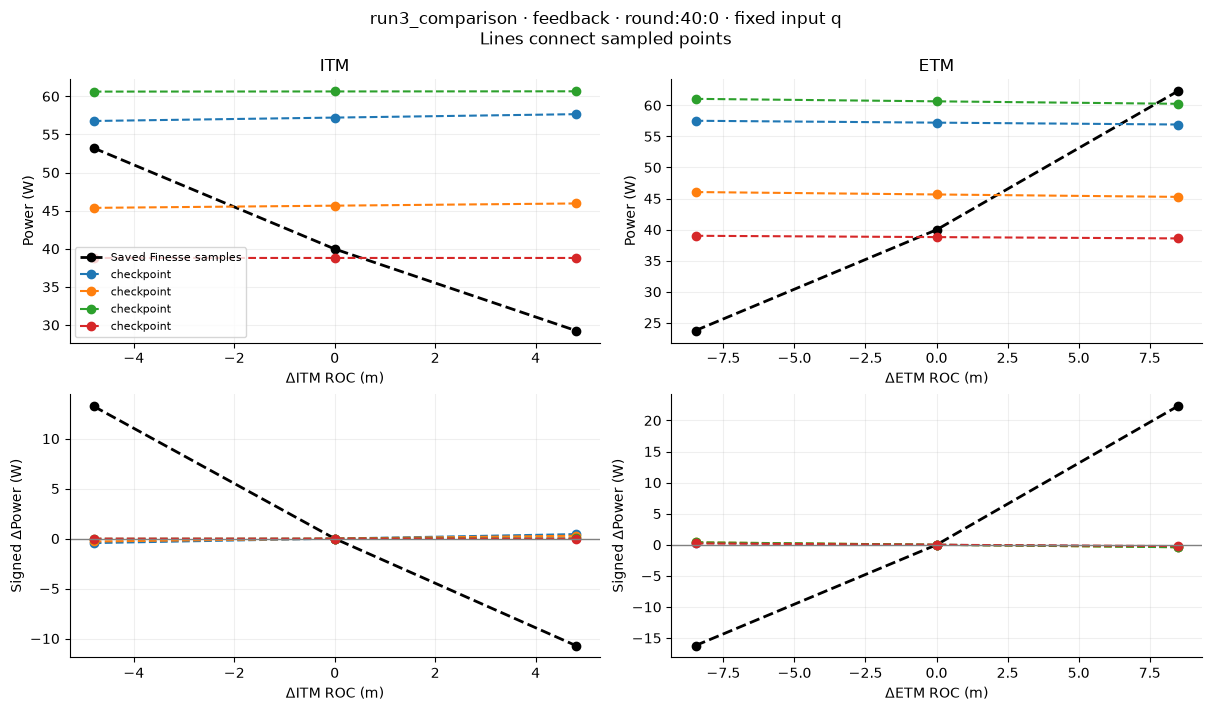

variant,seed,direction,delta_itm_roc,delta_etm_roc,power,predicted_power,power_error,delta_power,predicted_delta_power,delta_error
checkpoint,—,nominal,0,0,39.974,57.2096,17.2356,0,0,0
checkpoint,—,ITM_plus,4.79761,0,29.2758,57.6575,28.3817,-10.6982,0.447928,11.1461
checkpoint,—,ITM_minus,-4.79749,0,53.213,56.7645,3.55154,13.2389,-0.445086,-13.684
checkpoint,—,ETM_plus,0,8.47925,62.2506,56.9101,-5.34056,22.2766,-0.299524,-22.5761
checkpoint,—,ETM_minus,0,-8.47925,23.7657,57.511,33.7453,-16.2083,0.301408,16.5097
checkpoint,—,nominal,0,0,39.974,45.6558,5.68176,0,0,0
checkpoint,—,ITM_plus,4.79761,0,29.2758,45.9451,16.6693,-10.6982,0.289284,10.9875
checkpoint,—,ITM_minus,-4.79749,0,53.213,45.368,-7.845,13.2389,-0.287811,-13.5268
checkpoint,—,ETM_plus,0,8.47925,62.2506,45.2683,-16.9824,22.2766,-0.387497,-22.6641
checkpoint,—,ETM_minus,0,-8.47925,23.7657,46.0462,22.2804,-16.2083,0.390383,16.5987


In [14]:
if SHOW_ALL_GROUP_RESPONSES:
    for group in feedback_catalog:
        plot_group_response(group['experiment'], group['split'], group['group_id'])
elif feedback_catalog:
    key = (DETAIL_EXPERIMENT, DETAIL_SPLIT, DETAIL_GROUP)
    available = {(g['experiment'], g['split'], g['group_id']) for g in feedback_catalog}
    if key not in available:
        first = feedback_catalog[0]
        key = (first['experiment'], first['split'], first['group_id'])
        print(f'Configured group unavailable; showing {key}.')
    plot_group_response(*key)
else:
    print('No complete feedback groups saved in the selected experiments.')


## Largest errors and diagnostic checks

The worst sample rows are selected separately for each checkpoint and split, so an
experiment with much larger errors cannot hide failures in another experiment.
The configurable 0.1 W difference-error target is a diagnostic aid for multi-watt
responses, rather than a production acceptance criterion. Both mean and maximum
errors are shown; sign failures and checkpoints selected at the epoch budget are
called out for inspection.


In [15]:
worst_rows, diagnostic_rows = [], []
for row in metric_rows:
    paired = [p for p in runs[row['run_id']]['predictions']
              if p['split'] == row['split'] and p['direction'] != 'nominal']
    worst_rows.extend(sorted(paired, key=lambda p: abs(p['delta_error']), reverse=True)[:TOP_ERRORS_PER_RUN_SPLIT])
    budget = runs[row['run_id']]['config'].get('epochs')
    flags = []
    if row.get('delta_mae', 0) > DELTA_ERROR_TARGET_W:
        flags.append('mean Δ error exceeds target')
    if row.get('delta_max_abs_error', 0) > DELTA_ERROR_TARGET_W:
        flags.append('maximum Δ error exceeds target')
    if row.get('sign_count', 0) == 0:
        flags.append('no significant differences for sign check')
    elif row.get('sign_accuracy') is not None and row['sign_accuracy'] < 1:
        flags.append('some significant Δ signs are wrong')
    if row.get('best_epoch') is not None and budget is not None and row['best_epoch'] == budget:
        flags.append('selected checkpoint is at epoch budget')
    if 'smoke' in row['experiment'].lower():
        flags.append('smoke run: workflow check only')
    diagnostic_rows.append({'experiment': row['experiment'], 'variant': row['variant'],
        'seed': row['seed'], 'split': row['split'], 'scope': row['scope'],
        'checks': '; '.join(flags) or 'within configured Δ error target; inspect context'})
table(worst_rows, columns=['experiment', 'variant', 'seed', 'split', 'group_id', 'h5_key',
    'direction', 'nominal_power', 'power', 'predicted_power', 'power_error',
    'delta_power', 'predicted_delta_power', 'delta_error'],
    title=f'Largest {TOP_ERRORS_PER_RUN_SPLIT} difference errors per checkpoint / split')
table(diagnostic_rows, title='Checks derived from saved metrics')


experiment,variant,seed,split,group_id,h5_key,direction,nominal_power,power,predicted_power,power_error,delta_power,predicted_delta_power,delta_error
run3_comparison/run2_base_on_initial,checkpoint,—,training,base:59,sim_119,joint,139.956,33.7986,67.9039,34.1053,-106.157,1.19442,107.352
run3_comparison/run2_base_on_initial,checkpoint,—,training,base:56,sim_113,joint,31.3778,97.2523,8.80288,-88.4494,65.8745,-0.180428,-66.0549
run3_comparison/run2_base_on_initial,checkpoint,—,training,base:50,sim_101,joint,137.193,93.4825,114.713,21.2301,-43.7104,-3.82595,39.8844
run3_comparison/run2_base_on_initial,checkpoint,—,training_valid_fixed_q,base:59,sim_119,joint,139.956,33.7986,67.9039,34.1053,-106.157,1.19442,107.352
run3_comparison/run2_base_on_initial,checkpoint,—,training_valid_fixed_q,base:56,sim_113,joint,31.3778,97.2523,8.80288,-88.4494,65.8745,-0.180428,-66.0549
run3_comparison/run2_base_on_initial,checkpoint,—,training_valid_fixed_q,base:50,sim_101,joint,137.193,93.4825,114.713,21.2301,-43.7104,-3.82595,39.8844
run3_comparison/run2_base_on_initial,checkpoint,—,validation,base:68,sim_137,joint,282.093,282.081,284.166,2.08533,-0.0121701,3.12964,3.14181
run3_comparison/run2_base_on_initial,checkpoint,—,validation,base:90,sim_181,joint,282.093,282.086,286.322,4.23603,-0.00753455,3.08499,3.09252
run3_comparison/run2_base_on_initial,checkpoint,—,validation,base:44,sim_89,joint,282.094,281.989,288.893,6.90411,-0.105377,2.59577,2.70115
run3_comparison/run2_base_on_initial,checkpoint,—,validation_valid_fixed_q,base:68,sim_137,joint,282.093,282.081,284.166,2.08533,-0.0121701,3.12964,3.14181


experiment,variant,seed,split,scope,checks
run3_comparison/run2_base_on_initial,checkpoint,—,training,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run3_comparison/run2_base_on_initial,checkpoint,—,training_valid_fixed_q,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run3_comparison/run2_base_on_initial,checkpoint,—,validation,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run3_comparison/run2_base_on_initial,checkpoint,—,validation_valid_fixed_q,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run3_comparison,checkpoint,—,feedback,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run3_comparison,checkpoint,—,feedback,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run3_comparison/run3_base_on_initial,checkpoint,—,training,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run3_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run3_comparison/run3_base_on_initial,checkpoint,—,validation,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run3_comparison/run3_base_on_initial,checkpoint,—,validation_valid_fixed_q,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong


In [16]:
findings = []
for name, record in audits.items():
    audit = record['audit']
    findings.append(f'**{name}:** {audit["rows"]} samples in {audit["groups"]} groups; '
                    f'{audit["valid_fixed_q_groups"]} valid fixed-q groups, '
                    f'{audit["zero_output_rows"]} zero-output rows.')
    check = audit.get('inference_check')
    if check:
        findings.append(f'**{name} feature check:** {check["rows"] - check["mismatches"]}/{check["rows"]} '
                        'saved rows agree with the documented tolerances.')
for name, experiment in experiments.items():
    selected = [r for r in metric_rows if r['experiment'] == name]
    if experiment['scope'] == 'training-set fit':
        train = [r for r in selected if r['split'] == 'train']
        best = min(train, key=lambda r: r['delta_mae']) if train else None
        if best:
            findings.append(f'**{name}:** lowest saved training ΔPower MAE is {best["delta_mae"]:.6g} W '
                            f'({best["variant"]}, seed {best["seed"]}); maximum error is '
                            f'{best["delta_max_abs_error"]:.6g} W. This measures training reconstruction.')
    elif experiment['scope'] == 'generalization smoke run':
        findings.append(f'**{name}:** {experiment["config"].get("epochs")} epochs; '
                        'these held-out tables validate the workflow and do not establish trained model quality.')
    elif experiment['scope'] == 'standalone checkpoint evaluation':
        findings.append(f'**{name}:** existing-model predictions are included; independence from its '
                        'prior training is not established by these saved artifacts.')
    else:
        findings.append(f'**{name}:** checkpoints were monitored on '
                        f'{selected[0].get("monitor_split") if selected else "unspecified"}; '
                        'use validation for choices and preserve the test holdout.')
display(Markdown('\n\n'.join('- ' + finding for finding in findings) or 'No saved findings available.'))


- **run3_audit:** 700 samples in 140 groups; 118 valid fixed-q groups, 104 zero-output rows.

- **run3_selected_feature_audit:** 25 samples in 5 groups; 5 valid fixed-q groups, 0 zero-output rows.

- **run3_selected_feature_audit feature check:** 25/25 saved rows agree with the documented tolerances.

- **run3_comparison/run2_base_on_initial:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

- **run3_comparison:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

- **run3_comparison/run3_base_on_initial:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

- **run3_five_groups_fresh:** lowest saved training ΔPower MAE is 0.290474 W (paired, seed 9302); maximum error is 1.44182 W. This measures training reconstruction.

- **run3_five_groups_warm:** lowest saved training ΔPower MAE is 1.60267 W (paired, seed 9302); maximum error is 3.85088 W. This measures training reconstruction.

- **run3_transfer_center_focused:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

- **run3_transfer_paired:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

## Full records, configurations, and provenance

Expand a panel to view every saved sample, prediction, or history row and the exact
configuration and source hashes. Nothing in these tables is silently truncated.
The optional saved-figure gallery displays existing PNG artifacts without replacing
them. Checkpoint binaries remain listed in the artifact inventory.


In [17]:
for name, record in audits.items():
    json_panel(f'{name}: audit.json', record['audit'])
    json_panel(f'{name}: config.json', record['config'])
    table(record['samples'], title=f'{name}: all sample records', collapsed=True)
for name, experiment in experiments.items():
    json_panel(f'{name}: config.json', experiment['config'])
    if experiment['provenance']:
        json_panel(f'{name}: provenance.json (groups, exclusions, scales, hashes)', experiment['provenance'])
    summary = read_csv(experiment['path'] / 'summary.csv')
    if summary:
        table(summary, title=f'{name}: saved summary.csv', collapsed=True)
for run_id, run in runs.items():
    json_panel(f'{run_id}: metrics.json', run['metrics'])
    json_panel(f'{run_id}: resolved run config.json', run['config'])
    table(run['predictions'], title=f'{run_id}: all predictions', collapsed=True)
    if run['history']:
        table(run['history'], title=f'{run_id}: full training history', collapsed=True)


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_0,nominal,-2337.62,3194.95,-1300.15,1161.41,282.094,282.094,0,0,0,False,True
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_1,ITM_plus,-2329.91,3194.95,-1300.15,1161.41,282.092,282.094,-0.00165064,7.71411,0,False,True
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_2,ITM_minus,-2345.34,3194.95,-1300.15,1161.41,282.092,282.094,-0.00164766,-7.71411,0,False,True
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_3,ETM_plus,-2337.62,3205.5,-1300.15,1161.41,282.087,282.094,-0.00712851,0,10.5432,False,True
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_4,ETM_minus,-2337.62,3184.41,-1300.15,1161.41,282.087,282.094,-0.0070364,0,-10.5435,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_5,nominal,-3458.16,2917.84,-2666.3,1453.05,282.094,282.094,0,0,0,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_6,ITM_plus,-3446.75,2917.84,-2666.3,1453.05,282.082,282.094,-0.0117895,11.4121,0,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_7,ITM_minus,-3469.58,2917.84,-2666.3,1453.05,282.082,282.094,-0.012185,-11.4119,0,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_8,ETM_plus,-3458.16,2927.47,-2666.3,1453.05,282.091,282.094,-0.00298796,0,9.62891,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_9,ETM_minus,-3458.16,2908.21,-2666.3,1453.05,282.091,282.094,-0.00295886,0,-9.62891,False,True


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round1.h5,sim_0,nominal,-1434,3446.14,-704.544,716.892,280.681,280.681,0,0,0,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round1.h5,sim_1,ITM_plus,-1429.27,3446.14,-704.544,716.892,280.6,280.681,-0.0814364,4.73218,0,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round1.h5,sim_2,ITM_minus,-1438.73,3446.14,-704.544,716.892,280.758,280.681,0.0769286,-4.73218,0,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round1.h5,sim_3,ETM_plus,-1434,3457.51,-704.544,716.892,280.748,280.681,0.0665059,0,11.3721,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round1.h5,sim_4,ETM_minus,-1434,3434.77,-704.544,716.892,280.643,280.681,-0.0379677,0,-11.3723,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round10.h5,sim_0,nominal,-1434,2586.06,-1417.49,152.965,30.4322,30.4322,0,0,0,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round10.h5,sim_1,ITM_plus,-1429.27,2586.06,-1417.49,152.965,22.7252,30.4322,-7.70703,4.73218,0,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round10.h5,sim_2,ITM_minus,-1438.73,2586.06,-1417.49,152.965,40.907,30.4322,10.4748,-4.73218,0,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round10.h5,sim_3,ETM_plus,-1434,2594.59,-1417.49,152.965,49.1153,30.4322,18.6831,0,8.53418,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round10.h5,sim_4,ETM_minus,-1434,2577.52,-1417.49,152.965,18.5887,30.4322,-11.8435,0,-8.53394,False,True


comparison,run,checkpoint,split,groups,rows,power_mae,nominal_power_mae,delta_mae,sign_count,sign_correct,sign_accuracy,perturbation_cost_mae,full_cost_mae,predicted_full_cost_mean,true_full_cost_mean,interpretation
original_online_own_selected_points,2,base for round1; roundN-1 for roundN,online,40,200,6.15927,2.29518,5.83834,160,77,0.48125,1.87473,0.938135,0.0369371,0.975072,Each run chose its own geometries. These are original predictions before that round's Finesse feedback; not a controlled comparison of architectures.
original_online_own_selected_points,3,base for round1; roundN-1 for roundN,online,40,200,17.8715,11.3952,9.92912,131,48,0.366412,5.9183,2.95993,0.0423476,2.9962,Each run chose its own geometries. These are original predictions before that round's Finesse feedback; not a controlled comparison of architectures.
same_target_feedback_geometries,2,base,feedback,40,200,18.7552,19.7752,10.2497,131,2,0.0152672,5.8435,2.92647,0.148416,2.9962,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
same_target_feedback_geometries,2,round40,feedback,40,200,17.74,14.8932,10.1988,131,2,0.0152672,5.86519,2.93536,0.127803,2.9962,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
own_initial_checkpoint_split,2,base,training,80,160,7.42156,7.20673,4.99558,19,7,0.368421,—,—,—,—,"Training fit, including all rows production trained."
own_initial_checkpoint_split,2,base,training_valid_fixed_q,64,128,9.16037,8.9597,6.09655,18,6,0.333333,—,—,—,—,"Training fit, including all rows production trained. Only valid fixed-q groups; overlaps corresponding all-row split."
own_initial_checkpoint_split,2,base,validation,20,40,6.22299,5.86453,1.44116,3,0,0,—,—,—,—,Whole-design validation labels were held out from weight updates but used for checkpoint selection; not an independent test.
own_initial_checkpoint_split,2,base,validation_valid_fixed_q,15,30,8.23162,7.75369,1.91938,3,0,0,—,—,—,—,Whole-design validation labels were held out from weight updates but used for checkpoint selection; not an independent test. Only valid fixed-q groups; overlaps corresponding all-row split.
same_target_feedback_geometries,3,base,feedback,40,200,25.002,26.2714,10.0011,131,2,0.0152672,5.88838,2.94913,0.0564967,2.9962,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
same_target_feedback_geometries,3,round40,feedback,40,200,14.4832,7.67772,9.93456,131,48,0.366412,5.92533,2.96321,0.045737,2.9962,"Controlled checkpoint comparison at identical target feedback geometries. All target feedback labels were replayed during training; measures fit, not generalization."


variant,seed,split,best_epoch,groups,rows,power_mae,power_max_abs_error,count,delta_mae,delta_max_abs_error,sign_count,sign_accuracy,sign_threshold_w,valid_cost_groups,invalid_cost_groups,perturbation_cost_mae
center_focused,9302,train,2000,5,25,2.33489,17.3689,20,3.27634,15.7167,16,1,0.1,5,0,1.88428
log_smooth_l1,9302,train,2000,5,25,2.33489,17.3689,20,3.27634,15.7167,16,1,0.1,5,0,1.88428
paired,9302,train,2000,5,25,0.287872,0.753622,20,0.290474,1.44182,16,1,0.1,5,0,0.0499749


variant,seed,split,best_epoch,groups,rows,power_mae,power_max_abs_error,count,delta_mae,delta_max_abs_error,sign_count,sign_accuracy,sign_threshold_w,valid_cost_groups,invalid_cost_groups,perturbation_cost_mae
center_focused,9302,train,2000,5,25,4.09217,12.8261,20,4.9453,12.7323,16,1,0.1,5,0,3.32403
log_smooth_l1,9302,train,2000,5,25,4.09217,12.8261,20,4.9453,12.7323,16,1,0.1,5,0,3.32403
paired,9302,train,1900,5,25,1.64555,4.19949,20,1.60267,3.85088,16,1,0.1,5,0,1.11806


...

epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,0.0507734,0.468918,0.0507734,11.6123,11.0407,11.6123,11.0407,0.952008,run3_five_groups_warm,run3_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
50,0.0499848,0.466946,0.0499848,9.17686,11.0398,9.17686,11.0398,0.93322,run3_five_groups_warm,run3_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
100,0.0495654,0.464714,0.0495654,9.0632,11.0281,9.0632,11.0281,0.931438,run3_five_groups_warm,run3_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
150,0.0491447,0.461745,0.0491447,9.05422,11.0077,9.05422,11.0077,0.929769,run3_five_groups_warm,run3_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
200,0.0486262,0.458135,0.0486262,9.03547,10.979,9.03547,10.979,0.927389,run3_five_groups_warm,run3_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
250,0.0479897,0.453737,0.0479897,9.00983,10.9392,9.00983,10.9392,0.924075,run3_five_groups_warm,run3_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
300,0.0471956,0.448227,0.0471956,8.98062,10.8831,8.98062,10.8831,0.919469,run3_five_groups_warm,run3_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
350,0.046175,0.441025,0.046175,8.93587,10.8026,8.93587,10.8026,0.912838,run3_five_groups_warm,run3_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
400,0.0448265,0.431284,0.0448265,8.86006,10.6905,8.86006,10.6905,0.903496,run3_five_groups_warm,run3_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
450,0.0430244,0.417936,0.0430244,8.7382,10.534,8.7382,10.534,0.890327,run3_five_groups_warm,run3_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round1.h5,sim_0,nominal,-1434,3446.14,-704.544,716.892,280.681,280.681,0,0,0,False,True,279.621,-1.06001,0,0,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round1.h5,sim_1,ITM_plus,-1429.27,3446.14,-704.544,716.892,280.6,280.681,-0.0814364,4.73218,0,False,True,278.521,-2.07848,-1.0999,-1.01847,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round1.h5,sim_2,ITM_minus,-1438.73,3446.14,-704.544,716.892,280.758,280.681,0.0769286,-4.73218,0,False,True,280.721,-0.0374087,1.09953,1.0226,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round1.h5,sim_3,ETM_plus,-1434,3457.51,-704.544,716.892,280.748,280.681,0.0665059,0,11.3721,False,True,279.435,-1.31285,-0.186336,-0.252842,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round1.h5,sim_4,ETM_minus,-1434,3434.77,-704.544,716.892,280.643,280.681,-0.0379677,0,-11.3723,False,True,279.761,-0.882041,0.140001,0.177968,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round10.h5,sim_0,nominal,-1434,2586.06,-1417.49,152.965,30.4322,30.4322,0,0,0,False,True,30.1082,-0.324029,0,0,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round10.h5,sim_1,ITM_plus,-1429.27,2586.06,-1417.49,152.965,22.7252,30.4322,-7.70703,4.73218,0,False,True,24.4637,1.73847,-5.64453,2.0625,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round10.h5,sim_2,ITM_minus,-1438.73,2586.06,-1417.49,152.965,40.907,30.4322,10.4748,-4.73218,0,False,True,37.0335,-3.87349,6.92534,-3.54946,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round10.h5,sim_3,ETM_plus,-1434,2594.59,-1417.49,152.965,49.1153,30.4322,18.6831,0,8.53418,False,True,48.4113,-0.704034,18.3031,-0.380005,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round10.h5,sim_4,ETM_minus,-1434,2577.52,-1417.49,152.965,18.5887,30.4322,-11.8435,0,-8.53394,False,True,18.6696,0.0809102,-11.4386,0.40494,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit


epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,0.0507734,0.468918,0.519691,11.6123,11.0407,11.6123,11.0407,0.952008,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
50,0.048881,0.458674,0.507555,8.98944,10.9885,8.98944,10.9885,0.92777,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
100,0.0468512,0.44257,0.489421,9.19652,10.827,9.19652,10.827,0.916746,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
150,0.0439781,0.407092,0.45107,9.66029,10.356,9.66029,10.356,0.883501,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
200,0.0473972,0.283941,0.331339,10.5984,8.51186,10.5984,8.51186,0.746601,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
250,0.0533319,0.111658,0.16499,10.4113,4.9955,10.4113,4.9955,0.470377,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
300,0.0261006,0.0857136,0.111814,6.22711,4.20243,6.22711,4.20243,0.37625,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
350,0.0197509,0.068531,0.0882819,5.21158,3.55348,5.21158,3.55348,0.317734,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
400,0.0154906,0.0984283,0.113919,6.24764,4.93791,6.24764,4.93791,0.433882,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
450,0.01477,0.0531916,0.0679615,4.47438,3.01394,4.47438,3.01394,0.269906,run3_five_groups_warm,run3_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round2.h5,sim_0,nominal,-1434,3511.81,-633.548,712.127,281.446,281.446,0,0,0,False,True,233.403,-48.0429,0,0,run3_transfer_center_focused,run3_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round2.h5,sim_1,ITM_plus,-1429.27,3511.81,-633.548,712.127,281.449,281.446,0.00334256,4.73218,0,False,True,243.069,-38.3806,9.66565,9.6623,run3_transfer_center_focused,run3_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round2.h5,sim_2,ITM_minus,-1438.73,3511.81,-633.548,712.127,281.432,281.446,-0.0140447,-4.73218,0,False,True,249.882,-31.5504,16.4785,16.4925,run3_transfer_center_focused,run3_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round2.h5,sim_3,ETM_plus,-1434,3523.4,-633.548,712.127,281.048,281.446,-0.397798,0,11.5891,False,True,242.931,-38.1177,9.52743,9.92522,run3_transfer_center_focused,run3_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round2.h5,sim_4,ETM_minus,-1434,3500.22,-633.548,712.127,281.537,281.446,0.0914597,0,-11.5889,False,True,224.412,-57.1258,-8.99145,-9.08291,run3_transfer_center_focused,run3_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round3.h5,sim_0,nominal,-1434,3555.04,-585.121,704.767,279.427,279.427,0,0,0,False,True,214.28,-65.147,0,0,run3_transfer_center_focused,run3_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round3.h5,sim_1,ITM_plus,-1429.27,3555.04,-585.121,704.767,279.433,279.427,0.00519154,4.73218,0,False,True,220.622,-58.8103,6.34189,6.3367,run3_transfer_center_focused,run3_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round3.h5,sim_2,ITM_minus,-1438.73,3555.04,-585.121,704.767,279.426,279.427,-0.00152724,-4.73218,0,False,True,231.619,-47.8068,17.3387,17.3402,run3_transfer_center_focused,run3_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round3.h5,sim_3,ETM_plus,-1434,3566.77,-585.121,704.767,278.693,279.427,-0.734822,0,11.7317,False,True,222.771,-55.9218,8.49042,9.22524,run3_transfer_center_focused,run3_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round3.h5,sim_4,ETM_minus,-1434,3543.3,-585.121,704.767,280.066,279.427,0.638703,0,-11.7317,False,True,206.269,-73.7975,-8.01178,-8.65048,run3_transfer_center_focused,run3_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round2.h5,sim_0,nominal,-1434,3511.81,-633.548,712.127,281.446,281.446,0,0,0,False,True,238.305,-43.1408,0,0,run3_transfer_paired,run3_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round2.h5,sim_1,ITM_plus,-1429.27,3511.81,-633.548,712.127,281.449,281.446,0.00334256,4.73218,0,False,True,238.738,-42.7111,0.432981,0.429638,run3_transfer_paired,run3_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round2.h5,sim_2,ITM_minus,-1438.73,3511.81,-633.548,712.127,281.432,281.446,-0.0140447,-4.73218,0,False,True,238.02,-43.4122,-0.285446,-0.271401,run3_transfer_paired,run3_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round2.h5,sim_3,ETM_plus,-1434,3523.4,-633.548,712.127,281.048,281.446,-0.397798,0,11.5891,False,True,237.901,-43.1467,-0.403721,-0.00592324,run3_transfer_paired,run3_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round2.h5,sim_4,ETM_minus,-1434,3500.22,-633.548,712.127,281.537,281.446,0.0914597,0,-11.5889,False,True,238.872,-42.6658,0.566425,0.474965,run3_transfer_paired,run3_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round3.h5,sim_0,nominal,-1434,3555.04,-585.121,704.767,279.427,279.427,0,0,0,False,True,220.079,-59.3482,0,0,run3_transfer_paired,run3_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round3.h5,sim_1,ITM_plus,-1429.27,3555.04,-585.121,704.767,279.433,279.427,0.00519154,4.73218,0,False,True,220.422,-59.0106,0.342771,0.33758,run3_transfer_paired,run3_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round3.h5,sim_2,ITM_minus,-1438.73,3555.04,-585.121,704.767,279.426,279.427,-0.00152724,-4.73218,0,False,True,219.985,-59.4404,-0.0938028,-0.0922756,run3_transfer_paired,run3_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round3.h5,sim_3,ETM_plus,-1434,3566.77,-585.121,704.767,278.693,279.427,-0.734822,0,11.7317,False,True,219.522,-59.1705,-0.557173,0.177649,run3_transfer_paired,run3_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/round3.h5,sim_4,ETM_minus,-1434,3543.3,-585.121,704.767,280.066,279.427,0.638703,0,-11.7317,False,True,220.799,-59.267,0.719809,0.0811063,run3_transfer_paired,run3_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation


In [18]:
saved_figures = sorted({p for record in [*audits.values(), *experiments.values()]
                        for p in record['path'].rglob('*.png')})
if SHOW_SAVED_FIGURES:
    for path in saved_figures:
        display(Markdown(f'**{path.relative_to(DIAGNOSTICS_DIR).as_posix()}**'))
        display(Image(filename=str(path)))
else:
    print(f'{len(saved_figures)} saved PNG artifacts available. Set SHOW_SAVED_FIGURES=True to display all.')
print(f'Rendered {figure_count} diagnostic figures from saved results.')
if EXPORT_FIGURES:
    print(f'Exported PNG figures to {EXPORT_DIR}')


3 saved PNG artifacts available. Set SHOW_SAVED_FIGURES=True to display all.
Rendered 42 diagnostic figures from saved results.
